# 3-servo: pot-table

Film the horn from above while the servo crawls, passes and reverses, read the horn's angle from a printed tag against a reference tag beside it, and grade the pot against that angle, for the pot's table over the travel, its drift over the sitting, the true speed of a crawl, the backlash at a reversal and by hand, the ripple a crawl carries, and the floors of the method itself.

## Purpose

The pot is the servo's only position sensor. Its reading in counts against the horn's angle in degrees is the pot table, and every position the firmware holds goes through it. The registry carries 19.8 counts per degree from earlier work on another unit of the family, kept for sizing. This notebook measures the table on mg90-d against an outside truth.

- The table. The pot's counts against the horn's angle over the whole travel, its slope, its shape and how far each end sits from a straight line.
- The converter. The pot is read by the chip's 12-bit converter, and the codes it outputs set the table's finest step.
- Drift and hysteresis. Whether the table moved between the opening and the closing pass of the sitting, and whether the pot reads the same angle the same way from both directions.
- The crawl truth. The speed of the horn at a slow open-loop crawl, where neither the pot nor the back EMF reads well, against the README's target of 2 to 5 degrees per second.
- The ripple. The speed ripple a crawl carries, and whether it is locked to time or to the angle of a gear.
- The gear ratio, checked as tag degrees per commutation cycle of the motor.
- The backlash, from the dwell at a reversal and from the horn rocked by hand, and how the pot reads a horn held against a push.
- The method's floors, meaning the clock between the camera and the servo, the share of frames with both tags, and the tag's own noise at rest.

The truth is a printed tag on the horn read against a printed reference tag on the servo body. Stage 0's camera-tag notebook graded that reading, the image reading, to 0.16 degrees, about 3 counts of pot, and stage 0's clock-sync notebook put the camera's frames on the host clock through flashes of the board's STAT lamp, the clapper.

## Procedure

The servo is mg90-d on board dev-v006-2A-D, in the printed rig with the tag horn and the reference pad beside it, the board on the DPS at 5 V, the phone overhead in slow motion at 240 frames per second with both tags and the STAT lamp in view. The board runs the experiment image, so every drive is open loop. The sitting runner, `python -m oscnb.sitting servo-camera`, ran `stages/3-servo/pot-table/plan.py` in one sitting of about 20 minutes.

Each block is one phone clip. The runner started the recording at a prompt, `osc clapper` flashed the STAT lamp twelve times at the clip's start, the sweeps ran, and the clip was copied into the dataset under the block's name. Every sweep starts at a guard, 100 counts inside the soft limits, and ends with a park at mid travel and torque off.

1. `pass-open`, the bracket. One sweep of 20 % each way over the runway, 915 ms a direction, then a 300 ms coast with the bridge open.
2. `crawl`, six clips. A 150 ms kick at 30 %, a hold at the floor less 1 % up to the floor plus 4 %, then a 300 ms coast, both directions, from three starts, the guards and the guards moved in by a sixth and by a third of the travel. The floor is the ladder's sustaining floor, 7 %, so the holds ran at 6, 7 and 8 % in the first clip of a start and at 9 and 11 % in the second. The runner cut each hold to what the runway allows, 2.1 s at 6 % from the guards down to 0.46 s at 11 % from a third in.
3. `reversal`, one clip. A kick, then 9 % and its negative chained with no pause, then the same at 20 %.
4. `steps`, one clip. A kick, a hold at 9 %, then a step to 10 % in one sweep and to 8 % in the other, both directions.
5. `pass-close`, the same as the open, at the end of the sitting.

A second sitting, `servo-camera-10`, ran the optional `lash-hand` block, one clip of the horn rocked by hand with the servo free at zero duty, described in its own section.

## Data

Everything is under `telemetry/mg90-d__dev-v006-2A-D/`. The five blocks are in `pot-table/` as `pass-open-9`, `crawl-9`, `reversal-9`, `steps-9` and `pass-close-9`, and the sitting's manifest is `sittings/servo-camera-9.csv`. The second sitting's block is `pot-table/lash-hand-10`, its manifest `sittings/servo-camera-10.csv`. The clips' originals are not in git. Each block keeps what the extraction read from them, a corners table per clip with both tags' corners in every frame, a STAT lamp table, the clapper's own log, the lens in `camera.json` and the clips' properties in `manifest.json`, beside 960 px previews. The servo's side is one sweep folder per chain under `chains/`, as `osc-lab` writes it.

The libraries, then the pair and its folders.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.interpolate import BSpline
from scipy.ndimage import uniform_filter1d
from scipy.optimize import curve_fit
from scipy.signal import find_peaks, lombscargle

from oscnb import boards, figures, motors, results, ripple, servos, tel
from oscnb import fiducial as fd
from oscnb.display import show
from oscnb.figures import BLUE, GREEN, INK, MUTED, ORANGE, RED

In [2]:
SERVO = servos.SERVOS["mg90-d"]         # the servo: pot, train, rated V
MOTOR = motors.MOTORS[SERVO.motor]      # its motor, with its counted parts
BOARD_KEY = boards.DEFAULT              # the board, checked on every sweep
PAIR = f"{SERVO.key}__{BOARD_KEY}"      # the pair, the result file's name
PAIR_DIR = (Path("../../../telemetry") / PAIR).resolve()
DATA = PAIR_DIR / "pot-table"           # the five blocks of the sitting
MANIFEST = PAIR_DIR / "sittings" / "servo-camera-9.csv"
GEAR = SERVO.gear_ratio                 # counted teeth, motor revs per out
PER_REV = MOTOR.ripple_per_rev          # commutation events per motor rev
NOMINAL = SERVO.counts_per_deg_nominal  # earlier work, comparison only
ANGLE = "image_deg"                     # the tag reading stage 0 graded
FS = 20_000                             # rows per second, the control tick
print(SERVO.key, "on", BOARD_KEY, "from", results.rel(DATA))
print(f"gear {GEAR:.4f}:1 from counted teeth, {PER_REV} commutation events "
      f"per motor rev, pot {NOMINAL} counts per degree (nominal)")

mg90-d on dev-v006-2A-D from telemetry/mg90-d__dev-v006-2A-D/pot-table
gear 308.0533:1 from counted teeth, 6 commutation events per motor rev, pot 19.8 counts per degree (nominal)


### Earlier results carried in

The tag's grade and noise come from stage 0's camera-tag result and the clock's residual from clock-sync. The ladder gives the sustaining floor the crawl was planned on, and stage 1's pos-coupling result the pot's own noise at rest on this board.

In [3]:
TAG = results.read("0-instruments", "camera-tag")
CLOCK0 = results.read("0-instruments", "clock-sync")
LADDER = results.read("3-servo", "ladder", pair=PAIR)
POS_NOISE = results.read("1-board", "pos-coupling", pair=BOARD_KEY)
TAG_GRADE_DEG = TAG["angle_error_deg"]["value"]   # image reading, 90 %
TAG_NOISE_DEG = TAG["noise_deg"]["value"]         # the still, sd
CLOCK0_RMS_MS = CLOCK0["residual_rms_s"]["value"] * 1e3
FLOOR_PCT = LADDER["floor_pot_table_crawl_duty_pct"]["value"]
LADDER_LINE = LADDER["crawl_speed_on_v_eff_rev_s_per_v"]   # rev/s per V
POT_SD_RAW = POS_NOISE["pos_rest_sd_counts"]["capture_1"]["value"]
print(f"tag: grade {TAG_GRADE_DEG:.2f} deg, noise {TAG_NOISE_DEG:.4f} deg; "
      f"clock-sync residual {CLOCK0_RMS_MS:.2f} ms")
print(f"ladder floor {FLOOR_PCT:.0f} %, crawl line "
      f"{LADDER_LINE['value']:.1f} rev/s per V; pot at rest "
      f"{POT_SD_RAW:.2f} counts sd (stage 1)")

tag: grade 0.16 deg, noise 0.0126 deg; clock-sync residual 1.59 ms
ladder floor 7 %, crawl line 99.6 rev/s per V; pot at rest 1.13 counts sd (stage 1)


### The gear train

The registry holds the train's ratio and its teeth, counted on another unit of the family, the pinion in the motor's entry and the rest in the servo's. The train is written out here mesh by mesh, the driving gear first, with its product checked against the registry's ratio. Each shaft turns a known number of times per output turn, so a feature locked to a shaft repeats a known number of times per output degree. Those are the lines the crawl's ripple is compared with.

In [4]:
# (driving, driven) teeth per mesh, the motor's pinion first; the four
# shafts after the meshes are gear A, gear B, gear C and the output
TRAIN = SERVO.train
SHAFTS = ("gear A", "gear B", "gear C", "output")
ratio = np.prod([driven / driving for driving, driven in TRAIN])
assert abs(ratio / GEAR - 1) < 1e-5, f"{ratio} against {GEAR}"
LINES = {"commutation": PER_REV * GEAR / 360, "motor rev": GEAR / 360}
turns = GEAR                            # driving shaft turns per output turn
for n, ((driving, driven), shaft) in enumerate(zip(TRAIN, SHAFTS), 1):
    LINES[f"mesh {n}"] = driving * turns / 360   # teeth per output degree
    turns *= driving / driven
    LINES[shaft] = turns / 360          # shaft turns per output degree
for name, f in LINES.items():
    print(f"{name:12s} {f:8.4f} cycles per output degree, "
          f"{1 / f:7.2f} deg per cycle")

commutation    5.1342 cycles per output degree,    0.19 deg per cycle
motor rev      0.8557 cycles per output degree,    1.17 deg per cycle
mesh 1         7.7013 cycles per output degree,    0.13 deg per cycle
gear A         0.1604 cycles per output degree,    6.23 deg per cycle
mesh 2         1.9253 cycles per output degree,    0.52 deg per cycle
gear B         0.0401 cycles per output degree,   24.93 deg per cycle
mesh 3         0.4011 cycles per output degree,    2.49 deg per cycle
gear C         0.0106 cycles per output degree,   94.74 deg per cycle
mesh 4         0.1056 cycles per output degree,    9.47 deg per cycle
output         0.0028 cycles per output degree,  360.00 deg per cycle


### The sitting's manifest

The runner's log of the sitting, one row per event. The clip events say when each recording started and stopped, and the guards row gives the drive starts in counts.

In [5]:
EVENTS = pd.read_csv(MANIFEST)
clip_ev = EVENTS[EVENTS["event"] == "clip"].copy()
clip_ev["name"] = clip_ev["detail"].str.split().str[0]
clip_ev["what"] = clip_ev["detail"].str.split().str[1]
guard_row = EVENTS.loc[EVENTS["event"] == "guards", "detail"].iloc[0]
GUARDS = tuple(float(x) for x in guard_row.split()[0:3:2])
rail_row = EVENTS.loc[EVENTS["event"] == "rail", "detail"].iloc[0]
RAIL_V = float(rail_row.split()[0])     # V, the rail every plan ran on
span_min = (EVENTS["t_host"].max() - EVENTS["t_host"].min()) / 60
print(f"{len(EVENTS)} events over {span_min:.0f} min, "
      f"{(clip_ev['what'] == 'started').sum()} clips, guards {GUARDS}, rail "
      f"{RAIL_V} V")
show(EVENTS[EVENTS["event"].isin(["plan", "dataset", "guards", "rail",
                                  "pilot"])][["event", "detail"]], n=None)

80 events over 20 min, 10 clips, guards (414.0, 3460.0), rail 5.0 V


,event,detail
2,plan,pass (open)
3,dataset,pass-open: telemetry/mg90-d__dev-v006-2A-D/pot...
4,guards,414 to 3460 counts
6,rail,"5.0 V: reads 4.996 V, DPS 5.250 V"
8,pilot,5.0 V 30 % for 300 ms: 3288 counts/s
14,plan,crawl
15,dataset,crawl: telemetry/mg90-d__dev-v006-2A-D/pot-tab...
55,plan,reversal
56,dataset,reversal: telemetry/mg90-d__dev-v006-2A-D/pot-...
63,plan,steps


### chains.csv

One row per chain in each block, `k` its number, `schedule` its steps as `osc-lab` took them, `duty_pct` and `start_share` where the plan set them, `t_start` and `t_end` its host times, `folder` its sweep. The clip each chain belongs to is the one whose recording brackets its start.

In [6]:
BLOCKS = ("pass-open-9", "crawl-9", "reversal-9", "steps-9", "pass-close-9")
starts = clip_ev[clip_ev["what"] == "started"]["t_host"].to_numpy()
stops = clip_ev[clip_ev["what"] == "stopped"]["t_host"].to_numpy()
names = clip_ev[clip_ev["what"] == "started"]["name"].to_numpy()
CHAINS, CLIPS = [], {}
for block in BLOCKS:
    ch = pd.read_csv(DATA / block / "chains.csv")
    for _, r in ch.iterrows():
        i = int(np.flatnonzero((starts <= r["t_start"] + 0.5)
                               & (stops >= r["t_start"]))[0])
        # the two passes share the file name; the block names them apart
        name = block[:-2] if names[i] == "pass" else names[i]
        CLIPS.setdefault(name, (block, names[i], []))[2].append(r["k"])
        CHAINS.append({"clip": name, "block": block, **r.to_dict()})
CHAINS = pd.DataFrame(CHAINS)
show(CHAINS[["clip", "k", "schedule", "duty_pct", "start_share"]], n=None)
print({name: ks for name, (_, _, ks) in CLIPS.items()})

,clip,k,schedule,duty_pct,start_share
0,pass-open,0,"20@915,coast:300",NaN,NaN
1,crawl-0-0,0,"30@150,then:6@2135,coast:300",6.000,0.000
2,crawl-0-0,1,"30@150,then:7@1830,coast:300",7.000,0.000
3,crawl-0-0,2,"30@150,then:8@1601,coast:300",8.000,0.000
4,crawl-0-1,3,"30@150,then:9@1423,coast:300",9.000,0.000
5,crawl-0-1,4,"30@150,then:11@1164,coast:300",11.000,0.000
6,crawl-1-0,5,"30@150,then:6@1491,coast:300",6.000,0.167
7,crawl-1-0,6,"30@150,then:7@1278,coast:300",7.000,0.167
8,crawl-1-0,7,"30@150,then:8@1118,coast:300",8.000,0.167
9,crawl-1-1,8,"30@150,then:9@994,coast:300",9.000,0.167


{'pass-open': [0], 'crawl-0-0': [0, 1, 2], 'crawl-0-1': [3, 4], 'crawl-1-0': [5, 6, 7], 'crawl-1-1': [8, 9], 'crawl-2-0': [10, 11, 12], 'crawl-2-1': [13, 14], 'reversal': [0, 1], 'steps': [0, 1], 'pass-close': [0]}


### manifest.json and camera.json

The extraction's record of each clip, its size, frame count, rate and checksum, and where it found the STAT lamp. The lens is fitted from one view per pause of the board clip, `board.mp4`, filmed with the phone on its mount in portrait, and the same lens serves every clip of the sitting.

In [7]:
rows = []
for block in BLOCKS:
    doc = pd.read_json(DATA / block / "manifest.json", typ="series")
    for clip, c in doc["clips"].items():
        rows.append({"block": block, "clip": clip, "frames": c["frames"],
                     "fps": c["fps"], "width": c["width"],
                     "height": c["height"], "s": c["duration_s"],
                     "stat_roi": c.get("stat_roi")})
CLIP_INFO = pd.DataFrame(rows)
show(CLIP_INFO[CLIP_INFO["clip"] != "board.mp4"], n=None)
CAM = fd.Camera.load(DATA / "crawl-9" / "camera.json")
same = all(np.allclose(fd.Camera.load(DATA / b / "camera.json").K, CAM.K)
           for b in BLOCKS)
print(f"lens: {CAM.views} views, {CAM.rms_px:.3f} px rms, f "
      f"{CAM.K[0, 0]:.0f} {CAM.K[1, 1]:.0f} px, size {CAM.size}, "
      f"the same in every block: {same}")

,block,clip,frames,fps,width,height,s,stat_roi
0,pass-open-9,pass.mp4,7563,169.760,1080,1920,44.551,"[496, 1048, 24, 24]"
2,crawl-9,crawl-0-0.mp4,14341,170.126,1080,1920,84.296,"[496, 1048, 24, 24]"
3,crawl-9,crawl-0-1.mp4,10583,169.820,1080,1920,62.319,"[496, 1040, 24, 24]"
4,crawl-9,crawl-1-0.mp4,12646,169.917,1080,1920,74.425,"[496, 1040, 24, 24]"
5,crawl-9,crawl-1-1.mp4,9969,169.962,1080,1920,58.654,"[496, 1040, 24, 24]"
6,crawl-9,crawl-2-0.mp4,11797,170.207,1080,1920,69.310,"[496, 1048, 24, 24]"
7,crawl-9,crawl-2-1.mp4,10346,169.870,1080,1920,60.905,"[496, 1048, 24, 24]"
8,reversal-9,reversal.mp4,10319,170.172,1080,1920,60.639,"[496, 1048, 24, 24]"
9,steps-9,steps.mp4,10510,170.003,1080,1920,61.822,"[496, 1048, 24, 24]"
10,pass-close-9,pass.mp4,8918,169.917,1080,1920,52.485,"[496, 1048, 24, 24]"


lens: 23 views, 0.420 px rms, f 1563 1564 px, size (1080, 1920), the same in every block: True


The clips run 58 to 84 s, except the closing pass, which kept recording after its sweep. The container reports about 170 frames per second on average. The frames sit on a 240 Hz grid with about 40 % of them dropped, so the container's own time of each frame is used, never its index.

### The corners, the lamp and the clapper

Per clip, `<clip>.corners.csv` holds one row per frame, its container time `t`, the horn tag's four corners `hx0` to `hy3` and the reference's `rx0` to `ry3` in pixels, NaN where a tag was not found. `<clip>.stat.csv` holds the STAT lamp's level per frame, and `<clip>-clapper.csv` the host time before and after each of the twelve flash commands. One clip as an example.

In [8]:
example = DATA / "crawl-9"
corners = pd.read_csv(example / "crawl-0-0.corners.csv")
stat = pd.read_csv(example / "crawl-0-0.stat.csv")
clapper = pd.read_csv(example / "crawl-0-0-clapper.csv")
show(corners[["frame", "t", "hx0", "hy0", "h_side_px", "rx0", "ry0",
              "r_side_px"]], n=3)
show(stat, n=3)
show(clapper.assign(t_before=clapper["t_before"] - clapper["t_before"][0],
                    t_after=clapper["t_after"] - clapper["t_before"][0]),
     n=3)
dt = np.diff(corners["t"]) * 1e3
print(f"{len(corners)} frames, interval median {np.median(dt):.2f} ms, "
      f"99th percentile {np.percentile(dt, 99):.2f} ms; tags "
      f"{corners['h_side_px'].median():.0f} px across")

,frame,t,hx0,hy0,h_side_px,rx0,ry0,r_side_px
0,0,0.000,860.569,730.938,174.711,865.275,1003.085,174.820
1,1,0.008,860.469,731.035,174.689,865.332,1003.138,174.839
2,2,0.017,860.423,731.025,174.705,865.325,1003.155,174.853


,frame,t,level
0,0,0.000,-4.811
1,1,0.008,-6.135
2,2,0.017,-6.257


,flash,t_before,t_after
0,0,0.000,0.001
1,1,1.702,1.703
2,2,2.508,2.509


14341 frames, interval median 4.20 ms, 99th percentile 8.40 ms; tags 175 px across


The clapper's times are shown from its first flash. Each flash command returns within a millisecond, so `t_before` is the host's time of the flash to well under the clock's floor.

### The chains

Each chain is `sweep.csv`, `meta.json` and `segments.csv`, one row per control tick at 20 kHz. Segment 0 is a half second torque-off baseline, `pos` the pot in counts, `current_raw` the shunt amplifier's crest sample, `duty_counts` the applied window, `tick` restarting in every segment. `segments.csv` gives each segment's direction, commanded duty and host start time, and a row's host time is its segment's start plus its tick over 20 kHz. Every sweep names its board in its own `meta.json`, which is checked against the registry.

In [9]:
def board_of(meta, where=""):
    """The board a sweep's meta names, its sense block checked."""
    board = boards.from_meta(meta)      # identified from the data itself
    if board is None:
        raise ValueError(f"{where}: no board matches {meta['sense']}")
    board.check_meta(meta, where)       # raises on any mismatch
    return board


def load_sweep(block, k):
    """(rows with a host time each, meta, segments) of one chain."""
    folder = DATA / block / "chains" / str(k)
    df, meta = tel.load(folder)
    board_of(meta, str(results.rel(folder)))
    seg = pd.read_csv(folder / "segments.csv").set_index("seg")
    df["host"] = df["seg"].map(seg["t_start"]) + df["tick"] / meta["tick_hz"]
    return df, meta, seg


SWEEPS = {(name, k): load_sweep(block, k)
          for name, (block, _, ks) in CLIPS.items() for k in ks}
df, meta, seg = SWEEPS[("crawl-0-0", 0)]
show(seg.reset_index(), n=None)
print(f"{len(SWEEPS)} chains; crawl-0-0 chain 0: schedule "
      f"{meta['schedule']}, rows dropped {meta['rows_dropped']}, plant "
      f"stamp {meta['plant']['plant_stamp']} "
      f"({meta['plant']['stamp_verdict']})")

,seg,dir,cmd_duty_q15,streamed,samples,t_start,t_end
0,0,0,0,1,10000,1794184509.769,1794184510.273
1,1,1,9830,1,3000,1794184511.205,1794184511.358
2,2,1,1966,1,42700,1794184511.358,1794184513.501
3,3,1,0,1,6000,1794184513.501,1794184513.805
4,4,-1,-9830,1,3000,1794184517.246,1794184517.399
5,5,-1,-1966,1,42700,1794184517.399,1794184519.543
6,6,-1,0,1,6000,1794184519.543,1794184519.846


21 chains; crawl-0-0 chain 0: schedule ['30@150', 'then:6@2135', 'coast:300'], rows dropped 0, plant stamp 0x9c45 (match)


A crawl chain is a baseline, then for each direction a kick, the hold and a coast. A pass is a baseline, then a drive and a coast each way. A reversal chain is a kick, the duty and its negative, each way, and a steps chain a kick, the hold and the step, each way. The rows between segments, the seeks to the start, are not recorded.

## Raw data

One frame of a crawl clip's preview, with the corners the extraction found in the original drawn over it, and an arrow along each tag's edge. The angle of record is the horn's arrow against the reference's.

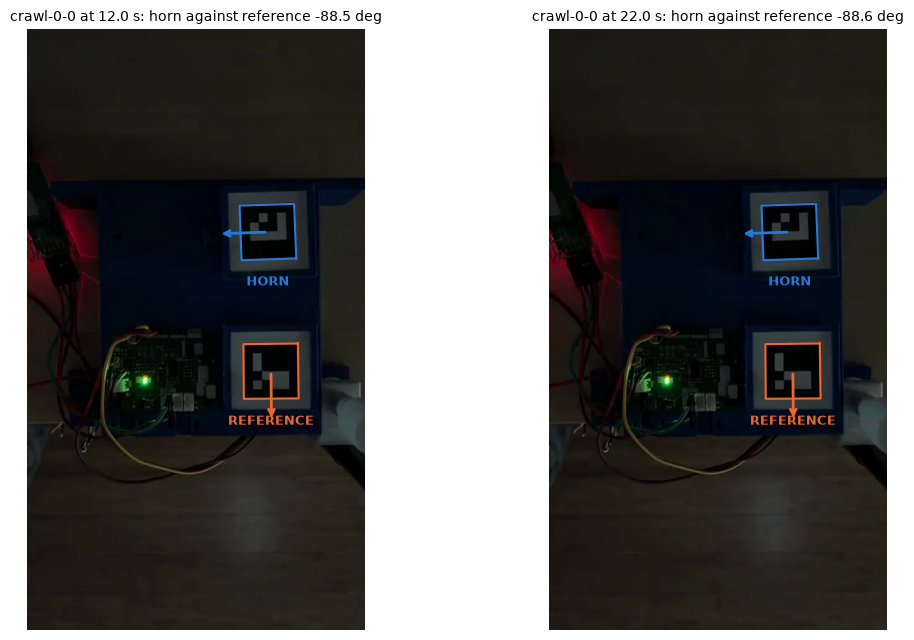

In [10]:
def draw_tags(ax, img, row, scale):
    """A frame with both tags' corners and edge directions drawn on."""
    ax.imshow(img[:, :, ::-1])
    ax.axis("off")
    for tag, color, name in (("h", BLUE, "HORN"), ("r", ORANGE, "REFERENCE")):
        c = fd.corners(row.to_frame().T, tag)[0] * scale
        ax.plot(*np.vstack([c, c[:1]]).T, "-", color=color, lw=1.5)
        mid, side = c.mean(axis=0), np.linalg.norm(c[1] - c[0])
        a = np.radians(fd.edge_direction(c))
        ax.annotate("", xy=mid + 0.9 * side * np.array([np.cos(a), np.sin(a)]),
                    xytext=mid, arrowprops={"arrowstyle": "->",
                                            "color": color, "lw": 2})
        ax.text(mid[0], mid[1] + 0.8 * side, name, color=color, ha="center",
                va="top", fontsize=9, fontweight="bold")


fig, axes = plt.subplots(1, 2, figsize=(12, 6.5))
for ax, t_want in zip(axes, (12.0, 22.0)):
    preview = example / "crawl-0-0.preview.mp4"
    k = int(round(t_want * 30))         # the preview runs at 30 fps
    _, t, img = next(fd.video_frames(preview, start=k, stop=k + 1))
    row = corners.iloc[(corners["t"] - t).abs().argmin()]
    draw_tags(ax, img, row, img.shape[1] / CAM.size[0])
    h, r = fd.corners(row.to_frame().T, "h")[0], fd.corners(row.to_frame().T,
                                                          "r")[0]
    ax.set_title(f"crawl-0-0 at {t:.1f} s: horn against reference "
                 f"{fd.image_angle(h, r):+.1f} deg", fontsize=10)
figures.finish(fig)

Two moments of the first crawl clip, the horn at two angles with the reference tag still. The preview is a 960 px copy for display, and the corners come from the full-size original.

## Method

### The clock

A clip's frames carry the phone's container time, and the servo's rows the host's. The clapper ties the two. Each of its twelve flashes is a stretch where the STAT lamp's level stands clear of its rest, found by `fiducial.bursts`, and its host time is the clapper's `t_before`. A line through the twelve pairs, $t_\mathrm{video} = t_0 + r \, t_\mathrm{host}$, gives the offset $t_0$ and the rate $r$, and a frame's host time is its container time through the inverse.

Stage 0 fitted the flash onsets. An onset is read on the first frame over the threshold, so it is late by up to one frame interval, and the interval jumps between 4.2 and 8.3 ms with the dropped frames. A flash's midpoint, halfway between its first and last lit frame, shares that error at both ends, so it cancels. `osc clapper` lights the lamp for 100 ms, so the midpoint's host time is `t_before` plus 50 ms. The midpoint fit is the clock of record and the onset fit is kept beside it.

In [11]:
HALF_FLASH_S = 0.050    # s, half the clapper's 100 ms flash, its midpoint


def clock(block, clip):
    """Container time to host time from the STAT flashes: the midpoint fit
    of record and stage 0's onset fit beside it."""
    stat = pd.read_csv(DATA / block / f"{clip}.stat.csv")
    clap = pd.read_csv(DATA / block / f"{clip}-clapper.csv")
    b = fd.bursts(stat["t"], stat["level"])
    if len(b) != len(clap):
        raise ValueError(f"{block}/{clip}: {len(b)} flashes, {len(clap)} "
                         "logged")
    h0 = float(clap["t_before"].iloc[0])   # host times from the first flash
    host = clap["t_before"] - h0
    off, rate, rms = fd.fit_clock(b["on"], host)
    mid = (b["on"] + b["off"]) / 2
    off_m, rate_m, rms_m = fd.fit_clock(mid, host + HALF_FLASH_S)
    return {"h0": h0, "offset": off_m, "rate": rate_m, "rms_ms": rms_m * 1e3,
            "onset_rate": rate, "onset_rms_ms": rms * 1e3,
            "onset_late_ms": (off - off_m) * 1e3, "flashes": len(b),
            "flash_ms": float(np.median(b["off"] - b["on"]) * 1e3)}


CLOCKS = pd.DataFrame([{"clip": name, **clock(block, clip)}
                       for name, (block, clip, _) in CLIPS.items()])
CLOCKS["ppm"] = (CLOCKS["rate"] - 1) * 1e6
CLOCKS["onset_ppm"] = (CLOCKS["onset_rate"] - 1) * 1e6
show(CLOCKS[["clip", "flashes", "flash_ms", "rms_ms", "onset_rms_ms",
             "ppm", "onset_ppm", "onset_late_ms"]], n=None)

,clip,flashes,flash_ms,rms_ms,onset_rms_ms,ppm,onset_ppm,onset_late_ms
0,pass-open,12,98.000,1.724,2.010,76.748,142.749,0.551
1,crawl-0-0,12,98.000,0.689,2.020,48.914,101.091,1.129
2,crawl-0-1,12,100.000,1.155,0.825,7.555,-13.053,0.472
3,crawl-1-0,12,100.000,1.308,1.692,-9.957,-107.659,1.896
4,crawl-1-1,12,100.000,1.464,1.729,26.137,157.076,-0.603
5,crawl-2-0,12,99.500,1.575,1.579,98.195,170.338,0.207
6,crawl-2-1,12,100.000,1.212,2.259,59.337,115.324,0.721
7,reversal,12,100.000,1.489,1.893,107.429,110.463,0.895
8,steps,12,98.000,1.688,1.793,-11.796,41.167,0.744
9,pass-close,12,96.000,1.402,2.536,14.836,-32.596,2.291


### The angle of record

`fiducial.angles` reads every frame's horn tag against the reference tag. The reference sits still on the body, so its mapping is taken once from its median corners. The image reading, `image_deg`, is the direction the horn tag's edges point in the undistorted image less the reference's, and is the angle of record, since the phone looks straight down. The plane-mapped reading, `angle_deg`, is kept as the cross-check. Positive is counter-clockwise seen from above. A frame's host time is its container time through the clip's clock, and `both` says both tags were found.

In [12]:
def clip_angles(name):
    """Per frame: container and host time, both readings, the reference's
    motion in px and whether both tags were found."""
    block, clip, _ = CLIPS[name]
    c = pd.read_csv(DATA / block / f"{clip}.corners.csv")
    a = fd.angles(c)
    ck = CLOCKS.set_index("clip").loc[name]
    return pd.DataFrame({
        "frame": a["frame"], "t": a["t"],
        "host": ck["h0"] + (a["t"] - ck["offset"]) / ck["rate"],
        "image_deg": a["image_deg"], "angle_deg": a["angle_deg"],
        "ref_motion_px": a["ref_motion_px"], "horn_seen": c["hx0"].notna(),
        "both": np.isfinite(a["image_deg"])})


TAGS = {name: clip_angles(name) for name in CLIPS}
print({name: f"{len(a)} frames, both {100 * a['both'].mean():.1f} %"
       for name, a in TAGS.items()})

{'pass-open': '7563 frames, both 99.8 %', 'crawl-0-0': '14341 frames, both 99.5 %', 'crawl-0-1': '10583 frames, both 99.7 %', 'crawl-1-0': '12646 frames, both 99.3 %', 'crawl-1-1': '9969 frames, both 99.7 %', 'crawl-2-0': '11797 frames, both 99.4 %', 'crawl-2-1': '10346 frames, both 96.4 %', 'reversal': '10319 frames, both 95.2 %', 'steps': '10510 frames, both 99.7 %', 'pass-close': '8918 frames, both 100.0 %'}


### The pot on the host clock

A row's host time is its segment's `t_start` from `segments.csv` plus its tick over 20 kHz. The pot at a frame is a 2 ms boxcar of `pos`, 41 rows, interpolated to the frame's host time inside one segment's rows. The pot's speed at a row is the slope across a centered 10 ms window of that boxcar. Every frame inside a streamed segment gets the pot, its speed and the segment's identity, and the frame table below is the one the table is fitted on.

In [13]:
BOX_ROWS = 41           # rows, the pot's 2 ms boxcar
SPEED_ROWS = 201        # rows, the 10 ms window of the pot's speed


def boxcar(x, n):
    """Centered mean of n rows (n odd), shrunk at the ends."""
    x = np.asarray(x, float)
    k = np.ones(n)
    return np.convolve(x, k, "same") / np.convolve(np.ones_like(x), k, "same")


def pot_speed(pos):
    """counts/s per row: the slope of the 2 ms boxcar across a centered
    10 ms window, NaN where the window runs off the segment."""
    p = boxcar(pos, BOX_ROWS)
    half = SPEED_ROWS // 2
    v = np.full(len(p), np.nan)
    if len(p) > SPEED_ROWS:
        span = (SPEED_ROWS - 1) / FS
        v[half:-half] = (p[SPEED_ROWS - 1:] - p[:-(SPEED_ROWS - 1)]) / span
    return v

In [14]:
def step_of(schedule, s):
    """The schedule step a segment ran: segment 0 is the baseline."""
    steps = schedule.split(",")
    return "baseline" if s == 0 else steps[(s - 1) % len(steps)]


def segment_frames(name, k, s, g, seg, chain):
    """The frames inside segment s of chain k, with the pot at each."""
    a, h = TAGS[name], g["host"].to_numpy()
    fr = a[(a["host"] >= h[0]) & (a["host"] <= h[-1])]
    hf = fr["host"].to_numpy()
    return pd.DataFrame({
        "clip": name, "k": k, "seg": s,
        "step": step_of(chain["schedule"], s), "dir": int(seg.loc[s, "dir"]),
        "duty_pct": chain.get("duty_pct", np.nan),
        "share": chain.get("start_share", np.nan),
        "frame": fr["frame"].to_numpy(), "host": hf, "t_seg": hf - h[0],
        "seg_len": h[-1] - h[0], "image_deg": fr["image_deg"].to_numpy(),
        "angle_deg": fr["angle_deg"].to_numpy(),
        "pos": np.interp(hf, h, boxcar(g["pos"], BOX_ROWS)),
        "pos_speed": np.interp(hf, h, pot_speed(g["pos"]))})

The rest points are the timing-free part of the data. The last 100 ms of every torque-off baseline and of every coast, where the shaft has stopped, give one pair each of the pot's mean and the tag's mean, with the approach direction the drive before a coast. The start of each drive gives another, the first 2 ms of the drive's rows, before anything moves, against the tag's frames over the 150 ms before it.

In [15]:
TAIL_S = 0.10           # s, the rest at the end of a baseline or a coast
START_ROWS = 40         # rows, a drive's first 2 ms, before it moves
BEFORE_S = 0.15         # s, the tag's frames before a drive starts
MIN_FRAMES = 5          # frames with both tags a rest point needs


def rest_point(name, k, s, g, kind, approach, host_lo, host_hi, rows):
    """One (pot, tag) pair from the rows and the tag frames given."""
    a = TAGS[name]
    fa = a[(a["host"] >= host_lo) & (a["host"] < host_hi) & a["both"]]
    if len(fa) < MIN_FRAMES:
        return None
    return {"clip": name, "k": k, "seg": s, "kind": kind,
            "approach": approach, "pos": rows["pos"].mean(),
            "pos_sd": rows["pos"].std(), "image_deg": fa[ANGLE].mean(),
            "image_sd": fa[ANGLE].std(), "angle_deg": fa["angle_deg"].mean(),
            "n_frames": len(fa), "host": host_hi}


def rest_points(name, k, s, g, seg, step):
    """The rest points one segment gives: its tail, its start, or none."""
    h, d, out = g["host"].to_numpy(), int(seg.loc[s, "dir"]), []
    if s == 0 or step.startswith("coast"):
        tail = g[g["host"] >= h[-1] - TAIL_S]
        out.append(rest_point(name, k, s, g, "baseline" if s == 0 else "coast",
                              0 if s == 0 else d, h[-1] - TAIL_S,
                              h[-1] + 1e-9, tail))
    if s > 0 and (s == 1 or int(seg.loc[s - 1, "dir"]) != d):
        out.append(rest_point(name, k, s, g, "start", 0, h[0] - BEFORE_S,
                              h[0], g.iloc[:START_ROWS]))
    return [p for p in out if p is not None]

In [16]:
frame_parts, static = [], []
for (name, k), (df, meta, seg) in SWEEPS.items():
    chain = CHAINS[(CHAINS["clip"] == name) & (CHAINS["k"] == k)].iloc[0]
    for s, g in df.groupby("seg"):
        frame_parts.append(segment_frames(name, k, s, g, seg, chain))
        static += rest_points(name, k, s, g, seg,
                              step_of(chain["schedule"], s))
FRAMES = pd.concat(frame_parts, ignore_index=True)
STATIC = pd.DataFrame(static)
print(f"{len(FRAMES)} frames in segments, "
      f"{int(FRAMES[ANGLE].notna().sum())} with both tags; "
      f"{len(STATIC)} rest points")
show(STATIC.groupby("kind")[["pos_sd", "image_sd", "n_frames"]].median()
     .reset_index(), n=None)

13279 frames in segments, 13192 with both tags; 97 rest points


,kind,pos_sd,image_sd,n_frames
0,baseline,0.971,0.012,17.000
1,coast,0.996,0.013,17.000
2,start,1.516,0.013,25.000


In a baseline or a coast tail the pot's sd is about one count, its own noise, and the tag's about 0.012 degrees, so a rest point is good to a fraction of a count on the pot and about 0.2 counts on the tag. The drive starts read 1.5 counts, since 40 rows average less.

### The pot stream's stamps against the camera

A segment's `t_start` is the host's time of the segment as `osc-lab` stamped it. Whether the servo's motion starts at that stamp is a question the camera answers. For each chain and direction the tag's angle and the pot are both put on a 1 ms grid, smoothed over 10 ms and differenced, and the shift of the pot's stamps that best correlates the two is read over +/-60 ms in 0.5 ms steps, refined by a parabola through the peak. A positive shift means the motion the camera sees comes after the stamps, so the stamps lead it. A direction group is the kick, hold and coast of a crawl chain, the drive and coast of a pass, or a duty and its successor in the reversal and steps chains.

In [17]:
GROUPS = {"pass": ((1, 2), (3, 4)), "crawl": ((1, 2, 3), (4, 5, 6)),
          "reversal": ((1, 2, 3), (4, 5, 6)), "steps": ((1, 2, 3), (4, 5, 6))}
SEARCH_S, STEP_S, GRID_S = 0.06, 0.0005, 0.001   # s
SMOOTH_PTS = 10                                  # grid points, 10 ms


def lead_of(tags, rows):
    """(shift s, correlation): the pot stamps' lead over the tag's motion
    by the correlation of 10 ms smoothed first differences."""
    f = tags[tags["both"]]
    t0, t1 = rows["host"].min(), rows["host"].max()
    f = f[(f["host"] >= t0 - 0.3) & (f["host"] <= t1 + 0.3)]
    grid = np.arange(t0 - 0.1, t1 + 0.1, GRID_S)
    va = np.diff(uniform_filter1d(np.interp(grid, f["host"], f[ANGLE]),
                                  SMOOTH_PTS))
    offs = np.arange(-SEARCH_S, SEARCH_S + STEP_S / 2, STEP_S)
    cs = np.array([np.corrcoef(va, np.diff(uniform_filter1d(np.interp(
        grid, rows["host"] + o, rows["pos"]), SMOOTH_PTS)))[0, 1]
        for o in offs])
    i = int(np.argmax(cs))
    if 0 < i < len(cs) - 1:             # a parabola through the peak
        y0, y1, y2 = cs[i - 1:i + 2]
        return offs[i] + 0.5 * (y0 - y2) / (y0 - 2 * y1 + y2) * STEP_S, cs[i]
    return offs[i], cs[i]

In [18]:
lead_rows = []
first_t = min(seg.loc[0, "t_start"] for _, _, seg in SWEEPS.values())
for (name, k), (df, meta, seg) in SWEEPS.items():
    kind = name.split("-")[0]           # pass, crawl, reversal or steps
    for gi, segs in enumerate(GROUPS[kind]):
        r = df[df["seg"].isin(segs)]
        shift, corr = lead_of(TAGS[name], r)
        lead_rows.append({"clip": name, "k": k, "group": gi,
                          "dir": int(r["dir"].iloc[0]), "lead_ms": shift * 1e3,
                          "corr": corr, "minutes": (seg.loc[0, "t_start"]
                                                    - first_t) / 60})
LEAD = pd.DataFrame(lead_rows)
LEAD_LINE = results.fit_line(LEAD["minutes"], LEAD["lead_ms"])
LEAD_OF = {(r["clip"], r["k"], r["dir"]): r["lead_ms"] / 1e3
           for _, r in LEAD.iterrows()}
print(f"{len(LEAD)} groups: lead {LEAD['lead_ms'].min():+.1f} to "
      f"{LEAD['lead_ms'].max():+.1f} ms, correlation {LEAD['corr'].min():.2f}"
      f" to {LEAD['corr'].max():.2f}")
print(f"line on the sitting: {LEAD_LINE['intercept']:+.1f} ms at the open, "
      f"{LEAD_LINE['slope']:+.2f} +/- {LEAD_LINE['slope_se']:.2f} ms per min,"
      f" {LEAD_LINE['rms']:.1f} ms rms about it")

42 groups: lead -0.5 to +22.9 ms, correlation 0.89 to 0.98
line on the sitting: +13.9 ms at the open, -0.92 +/- 0.13 ms per min, 3.4 ms rms about it


Every group correlates at 0.89 or better, and the lead is not one number. It wanders over the sitting, and its results section shows how. The table below is fitted with no shift at all, one free offset per moving segment instead, which absorbs any lead that stays constant through a segment. The shifts serve the reversals, where the pot and the tag are compared millisecond by millisecond.

### The table's model

The table is $\mathrm{pos} = T(\theta) + c_s$, with $\theta$ ("theta") the tag angle, $T$ a cubic B-spline in $\theta$ shared by every segment, and $c_s$ one free offset per moving segment $s$. The rest points carry no offset, $c = 0$, so they set the table's level and the offsets take up whatever moves a whole segment against the tag, a constant lead of the stamps among it. The moving data are the frames of the holds and the pass drives from 150 ms after the segment opens, the kick's spin-up out, to 20 ms before it ends, where the pot moves faster than 50 counts per second. The kicks and the coasts under way are left out.

The knot spacing is chosen by a two-fold cross-validation over chains, the even chains against the odd. A table is fitted on one half and scored on the other half's segments, each with its own offset taken out, over the angles the trained half covered.

In [19]:
SKIP_S = 0.15           # s, the kick's spin-up out of a hold
END_S = 0.02            # s, the end of a segment out
MOVING_CPS = 50         # counts/s, a frame that moves
KNOTS = (1.0, 1.5, 2.0, 3.0, 5.0, 10.0)   # deg, the spacings tried
SMOOTH_KNOT = 10.0      # deg, the knots of the table's smooth part

fr = FRAMES[FRAMES[ANGLE].notna()].copy()
held = fr["step"].str.startswith("then") | fr["step"].str.startswith("20@")
MOVING = fr[held & (fr["t_seg"] > SKIP_S) & (fr["t_seg"] < fr["seg_len"]
                                             - END_S)
            & (fr["pos_speed"].abs() > MOVING_CPS)].copy()
MOVING["sid"] = (MOVING["clip"] + "/" + MOVING["k"].astype(str) + "/"
                 + MOVING["seg"].astype(str))
LO, HI = float(MOVING[ANGLE].min()), float(MOVING[ANGLE].max())
REST = STATIC[(STATIC["image_deg"] >= LO) & (STATIC["image_deg"] <= HI)]
REST = REST.copy()
STARTS = STATIC[STATIC["kind"] == "start"].copy()
print(f"{len(MOVING)} moving frames in {MOVING['sid'].nunique()} segments "
      f"over {LO:.1f} to {HI:.1f} deg; {len(REST)} rest points inside it")

6001 moving frames in 50 segments over -163.2 to -28.6 deg; 75 rest points inside it


In [20]:
def basis(theta, knot, lo=None, hi=None, k=3):
    """The cubic B-spline basis over [lo, hi], knots every `knot` deg."""
    lo, hi = LO if lo is None else lo, HI if hi is None else hi
    inner = np.arange(lo, hi + 1e-9, knot)
    if inner[-1] < hi:
        inner = np.append(inner, hi)
    t = np.r_[[lo] * k, inner, [hi] * k]
    n = len(t) - k - 1
    x = np.clip(theta, lo, hi)
    B = np.empty((len(x), n))
    for j in range(n):
        c = np.zeros(n)
        c[j] = 1
        B[:, j] = BSpline(t, c, k, extrapolate=False)(x)
    return np.nan_to_num(B)


def table_at(model, theta):
    """T(theta) of a fitted table, NaN outside the range it was fitted on."""
    theta = np.asarray(theta, float)
    y = basis(theta, model["knot"]) @ model["c"]
    return np.where((theta >= LO) & (theta <= HI), y, np.nan)

In [21]:
def fit_table(moving, rest, knot):
    """T and one offset per moving segment; the rest points at offset 0.
    Returns (model, {segment: offset}, residuals moving then rest)."""
    sids = sorted(moving["sid"].unique())
    col = {s: i for i, s in enumerate(sids)}
    Bm = basis(moving[ANGLE].to_numpy(), knot)
    S = np.zeros((len(moving), len(sids)))
    S[np.arange(len(moving)), [col[s] for s in moving["sid"]]] = 1.0
    Br = basis(rest["image_deg"].to_numpy(), knot)
    X = np.vstack([np.hstack([Bm, S]),
                   np.hstack([Br, np.zeros((len(rest), len(sids)))])])
    y = np.r_[moving["pos"].to_numpy(), rest["pos"].to_numpy()]
    beta = np.linalg.lstsq(X, y, rcond=None)[0]
    nb = Bm.shape[1]
    model = {"c": beta[:nb], "knot": knot}
    return model, dict(zip(sids, beta[nb:])), y - X @ beta


def held_out_rms(model, moving):
    """rms over held-out segments, each with its own offset taken out."""
    r = moving["pos"].to_numpy() - table_at(model, moving[ANGLE])
    r = pd.Series(r, index=moving.index)
    r = r.groupby(moving["sid"]).transform(lambda x: x - x.mean())
    return float(np.sqrt(np.nanmean(r ** 2)))

In [22]:
cv_rows = []
for knot in KNOTS:
    scores = []
    for fold in (0, 1):
        train = MOVING[MOVING["k"] % 2 == fold]
        test = MOVING[MOVING["k"] % 2 != fold]
        model, _, _ = fit_table(train, REST, knot)
        inside = ((test[ANGLE] >= train[ANGLE].min())
                  & (test[ANGLE] <= train[ANGLE].max()))
        scores.append(held_out_rms(model, test[inside]))
    cv_rows.append({"knot_deg": knot, "held_out_rms_counts": np.mean(scores)})
CV = pd.DataFrame(cv_rows)
KNOT = float(CV.loc[CV["held_out_rms_counts"].idxmin(), "knot_deg"])
show(CV, n=None)
print(f"knot spacing of record {KNOT:g} deg")

,knot_deg,held_out_rms_counts
0,1.000,3.136
1,1.500,3.100
2,2.000,3.121
3,3.000,3.302
4,5.000,4.740
5,10.000,6.370


knot spacing of record 1.5 deg


The held-out rms falls to about 3.1 counts at 1 to 2 degree knots and rises past 3 degrees, so the table holds real structure down to a couple of degrees. 1.5 degrees scores best and is the table of record. 10 degree knots, which keep only the table's smooth bend, are fitted beside it, and the table less its smooth part is its fine texture.

In [23]:
MODEL, OFFSETS, resid = fit_table(MOVING, REST, KNOT)
MOVING["resid"] = resid[:len(MOVING)]
REST["resid"] = resid[len(MOVING):]
MOVING["offset"] = MOVING["sid"].map(OFFSETS)
SMOOTH, _, _ = fit_table(MOVING, REST, SMOOTH_KNOT)
GRID = np.arange(np.ceil(LO), np.floor(HI) + 1e-9, 1.0)   # deg, 1 deg grid
T_GRID = table_at(MODEL, GRID)
T_SMOOTH = table_at(SMOOTH, GRID)
LINE = np.polyfit(GRID, T_GRID, 1)      # the mid-travel line, counts/deg
SCALE = LINE[0]
seg_rms = MOVING.groupby("sid")["resid"].apply(
    lambda x: np.sqrt(np.mean(x ** 2)))
fit_rms = np.sqrt(np.mean(MOVING["resid"] ** 2))
print(f"table over {GRID[0]:.0f} to {GRID[-1]:.0f} deg: line "
      f"{SCALE:.2f} counts/deg, residual {fit_rms:.2f} counts rms over "
      f"{len(MOVING)} frames (per segment median "
      f"{seg_rms.median():.1f}, max {seg_rms.max():.1f}), rest points "
      f"{np.sqrt(np.mean(REST['resid'] ** 2)):.2f}")

table over -163 to -29 deg: line 18.97 counts/deg, residual 2.84 counts rms over 6001 frames (per segment median 2.3, max 5.2), rest points 3.14


The ends of the travel. The steady moving data stop several degrees short of both guards, so the ends are read from the rest points at the drive starts, where every chain starts from a guard or from a point a sixth or a third in. A line through the starts within 150 counts of each guard gives the slope there and the angle at the guard, with the line's covariance for its error. The guards come from the manifest.

In [24]:
END_REACH = 150         # counts, the starts near a guard


def end_line(starts, guard):
    """Slope, angle at the guard and their errors from one end's starts."""
    (b1, b0), cov = np.polyfit(starts["image_deg"], starts["pos"], 1,
                               cov=True)
    at = (guard - b0) / b1              # the angle where the line meets it
    J = np.array([-(guard - b0) / b1 ** 2, -1 / b1])
    return {"n": len(starts), "slope": b1, "slope_se": np.sqrt(cov[0, 0]),
            "guard_deg": at, "guard_deg_se": np.sqrt(J @ cov @ J),
            "rms": (starts["pos"] - (b0 + b1 * starts["image_deg"])).std(),
            "line": (b1, b0)}


END_LO = end_line(STARTS[STARTS["pos"] < GUARDS[0] + END_REACH], GUARDS[0])
END_HI = end_line(STARTS[STARTS["pos"] > GUARDS[1] - END_REACH], GUARDS[1])
SPAN = END_HI["guard_deg"] - END_LO["guard_deg"]
SPAN_SE = np.hypot(END_HI["guard_deg_se"], END_LO["guard_deg_se"])
GUARD_OFF = [g - np.polyval(LINE, e["guard_deg"])
             for g, e in zip(GUARDS, (END_LO, END_HI))]
for name, e in (("low", END_LO), ("high", END_HI)):
    print(f"{name} end: {e['n']} starts, {e['slope']:.1f} +/- "
          f"{e['slope_se']:.1f} counts/deg, guard at {e['guard_deg']:.2f} "
          f"+/- {e['guard_deg_se']:.2f} deg")
print(f"guard to guard {SPAN:.2f} +/- {SPAN_SE:.2f} deg, "
      f"{(GUARDS[1] - GUARDS[0]) / SPAN:.2f} counts/deg on average; the "
      f"guards sit {GUARD_OFF[0]:+.0f} and {GUARD_OFF[1]:+.0f} counts off "
      "the mid-travel line")

low end: 11 starts, 22.3 +/- 0.8 counts/deg, guard at -170.22 +/- 0.15 deg
high end: 11 starts, 22.9 +/- 0.6 counts/deg, guard at -16.10 +/- 0.10 deg
guard to guard 154.12 +/- 0.19 deg, 19.76 counts/deg on average; the guards sit -70 and +52 counts off the mid-travel line


## The clock and the floors

What the method itself can resolve. The clock fit's residual per clip, the share of frames with both tags, how still the reference tag sat, and the tag's angle noise at rest against the pot's. The tag's noise at rest is read over the second half of every torque-off baseline, where the horn has settled, as the sd of the image reading about a line through those frames.

In [25]:
noise_rows = []
for (name, k), (df, meta, seg) in SWEEPS.items():
    base = tel.baseline(df)             # the torque-off half, second half
    a = TAGS[name]
    fa = a[(a["host"] >= base["host"].iloc[0])
           & (a["host"] <= base["host"].iloc[-1]) & a["both"]]
    t = fa["host"] - fa["host"].iloc[0]
    trend = np.polyval(np.polyfit(t, fa[ANGLE], 1), t)
    noise_rows.append({"clip": name, "k": k, "frames": len(fa),
                       "tag_sd_deg": (fa[ANGLE] - trend).std(),
                       "plane_sd_deg": fa["angle_deg"].std(),
                       "pot_sd": base["pos"].std()})
NOISE = pd.DataFrame(noise_rows)
QUALITY = pd.DataFrame([{
    "clip": name, "both_pct": 100 * a["both"].mean(),
    "ref_med_px": a["ref_motion_px"].median(),
    "ref_p99_px": a["ref_motion_px"].quantile(0.99)}
    for name, a in TAGS.items()])
fast = FRAMES["pos_speed"].abs() > 1500     # counts/s, the kicks and passes
QUALITY["horn_fast_pct"] = QUALITY["clip"].map(
    FRAMES[fast].groupby("clip")[ANGLE].apply(lambda x: 100 * x.notna().mean()))
show(QUALITY, n=None)
print(f"tag at rest: {NOISE['tag_sd_deg'].median():.4f} deg sd median "
      f"({NOISE['tag_sd_deg'].min():.4f} to {NOISE['tag_sd_deg'].max():.4f}"
      f", {len(NOISE)} baselines), plane-mapped "
      f"{NOISE['plane_sd_deg'].median():.4f}; pot "
      f"{NOISE['pot_sd'].median():.2f} counts raw")

,clip,both_pct,ref_med_px,ref_p99_px,horn_fast_pct
0,pass-open,99.775,0.081,1.290,99.608
1,crawl-0-0,99.505,0.087,1.175,92.208
2,crawl-0-1,99.717,0.085,0.209,96.262
3,crawl-1-0,99.265,0.098,1.274,82.237
4,crawl-1-1,99.749,0.083,0.253,94.231
5,crawl-2-0,99.381,0.052,0.303,100.000
6,crawl-2-1,96.433,0.051,0.609,100.000
7,reversal,95.203,0.049,0.446,100.000
8,steps,99.724,0.077,1.609,100.000
9,pass-close,99.978,0.048,0.322,100.000


tag at rest: 0.0134 deg sd median (0.0054 to 0.0278, 21 baselines), plane-mapped 0.0102; pot 0.96 counts raw


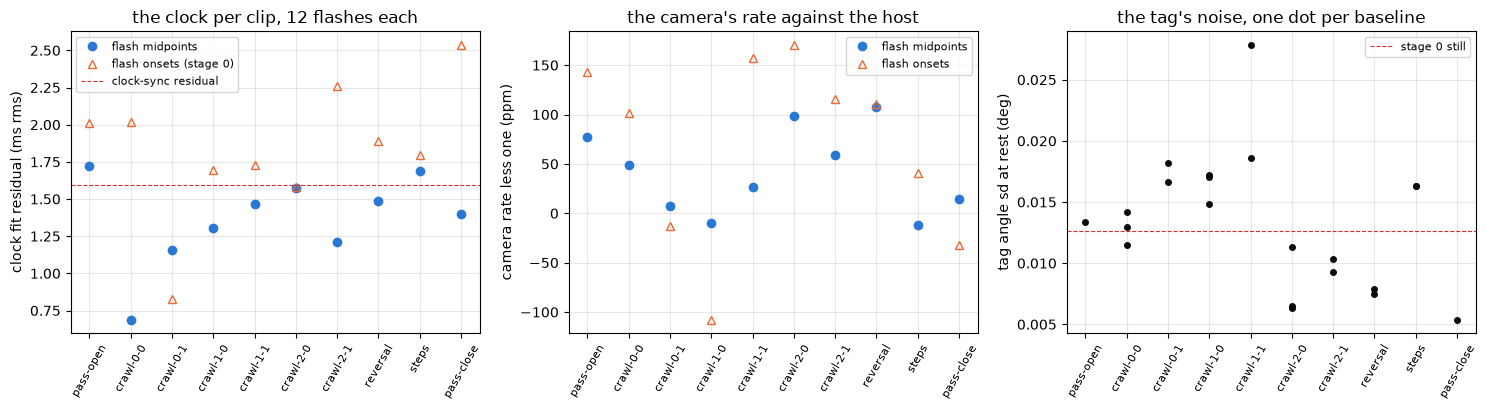

In [26]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4.2))
x = np.arange(len(CLOCKS))
ax[0].plot(x, CLOCKS["rms_ms"], "o", color=BLUE, label="flash midpoints")
ax[0].plot(x, CLOCKS["onset_rms_ms"], "^", color=ORANGE, mfc="none",
           label="flash onsets (stage 0)")
ax[0].axhline(CLOCK0_RMS_MS, **figures.HIGHLIGHT_STYLE,
              label="clock-sync residual")
ax[1].plot(x, CLOCKS["ppm"], "o", color=BLUE, label="flash midpoints")
ax[1].plot(x, CLOCKS["onset_ppm"], "^", color=ORANGE, mfc="none",
           label="flash onsets")
for a in ax[:2]:
    a.set_xticks(x, CLOCKS["clip"], rotation=60, fontsize=8)
    a.legend(fontsize=8)
figures.label(ax[0], y="clock fit residual (ms rms)",
              title="the clock per clip, 12 flashes each")
figures.label(ax[1], y="camera rate less one (ppm)",
              title="the camera's rate against the host")
for name, g in NOISE.groupby("clip", sort=False):
    ax[2].plot(np.full(len(g), list(CLIPS).index(name)), g["tag_sd_deg"],
               "o", color=INK, ms=4)
ax[2].axhline(TAG_NOISE_DEG, **figures.HIGHLIGHT_STYLE,
              label="stage 0 still")
ax[2].set_xticks(range(len(CLIPS)), list(CLIPS), rotation=60, fontsize=8)
ax[2].legend(fontsize=8)
figures.label(ax[2], y="tag angle sd at rest (deg)",
              title="the tag's noise, one dot per baseline")
figures.finish(fig)

Left, the clock fit's residual per clip, the midpoint fit of record against stage 0's onset fit. The midpoints fit to 0.69 to 1.72 ms rms and the onsets to 0.82 to 2.54 ms, the midpoints better in nine clips of ten, and the onsets read late by about a millisecond on average, as an onset read on the first lit frame should. Middle, the camera's rate against the host's, within 200 ppm either way by both fits, which over a minute-long clip is under 12 ms of drift that the line takes out. Right, the tag's angle noise at rest, one dot per torque-off baseline, against stage 0's still at 0.0126 degrees. The median is 0.013 degrees.

Both tags are found in 95.2 to 99.98 % of frames, the reference in every frame. The horn is missed mostly at the fast kicks, where the tag blurs, and inside the streamed segments above 1500 counts per second it is found in 82 to 100 % of frames, the worst in crawl-1-0. The reference tag moves 0.05 to 0.10 px at the median, and 0.2 to 1.6 px at the 99th percentile, the largest tail in the steps clip. The image reading takes the horn against the reference in each frame, so a common motion of both cancels.

Stage 0 graded the image reading to 0.16 degrees at the 90th percentile over a full turn, 3 counts of pot at 18.9 counts per degree. That grade, not the 0.013 degrees of noise, is the floor of every comparison of the pot against the tag below, and the clock's 1 to 2.5 ms is the floor of every timing.

## The table

The pot against the tag over the whole travel. The thing to see is the bend of the table about its mid-travel line and the steep ends at the guards.

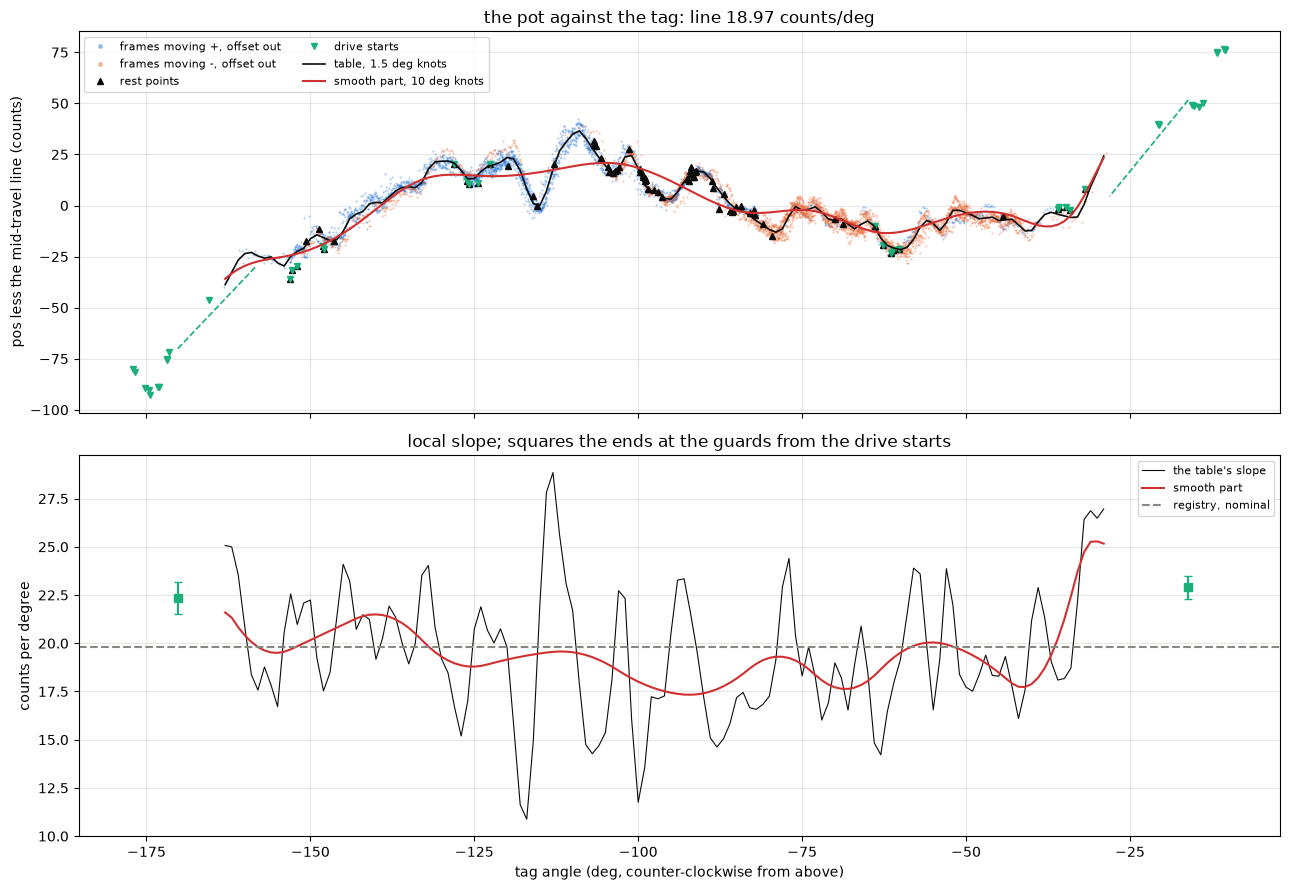

In [27]:
MOVING["dir_s"] = np.sign(MOVING["pos_speed"])   # the direction of motion
SLOPE = np.gradient(T_GRID, GRID)                # counts/deg, local
SLOPE_SMOOTH = np.gradient(T_SMOOTH, GRID)
fig, ax = plt.subplots(2, 1, figsize=(13, 9), sharex=True)
for d, color in ((1, BLUE), (-1, ORANGE)):
    g = MOVING[MOVING["dir_s"] == d]
    ax[0].plot(g[ANGLE], g["pos"] - g["offset"] - np.polyval(LINE, g[ANGLE]),
               ".", ms=1, color=color, alpha=0.4,
               label=f"frames moving {'+' if d > 0 else '-'}, offset out")
ax[0].plot(REST["image_deg"], REST["pos"] - np.polyval(LINE, REST["image_deg"]),
           "^", color=INK, ms=4, label="rest points")
ax[0].plot(STARTS["image_deg"],
           STARTS["pos"] - np.polyval(LINE, STARTS["image_deg"]), "v",
           color=GREEN, ms=4, label="drive starts")
ax[0].plot(GRID, T_GRID - np.polyval(LINE, GRID), "-", color=INK, lw=1.2,
           label=f"table, {KNOT:g} deg knots")
ax[0].plot(GRID, T_SMOOTH - np.polyval(LINE, GRID), "-", color=RED, lw=1.5,
           label=f"smooth part, {SMOOTH_KNOT:g} deg knots")
for e, guard in ((END_LO, GUARDS[0]), (END_HI, GUARDS[1])):
    th = np.linspace(e["guard_deg"], e["guard_deg"] + np.sign(
        -90 - e["guard_deg"]) * 12, 20)
    ax[0].plot(th, np.polyval(e["line"], th) - np.polyval(LINE, th), "--",
               color=GREEN, lw=1.2)
leg = ax[0].legend(fontsize=8, ncol=2)
for h in leg.legend_handles:            # the frames' dots readable
    h.set_markersize(5)
figures.label(ax[0], y="pos less the mid-travel line (counts)",
              title=f"the pot against the tag: line {SCALE:.2f} counts/deg")
ax[1].plot(GRID, SLOPE, "-", color=INK, lw=0.8, label="the table's slope")
ax[1].plot(GRID, SLOPE_SMOOTH, "-", color=RED, lw=1.5, label="smooth part")
ax[1].axhline(NOMINAL, color=MUTED, ls="--", label="registry, nominal")
for e in (END_LO, END_HI):
    ax[1].errorbar(e["guard_deg"], e["slope"], yerr=e["slope_se"], fmt="s",
                   color=GREEN, capsize=3)
ax[1].legend(fontsize=8)
figures.label(ax[1], x="tag angle (deg, counter-clockwise from above)",
              y="counts per degree", title="local slope; squares the ends "
              "at the guards from the drive starts")
figures.finish(fig)

Top, every moving frame's pot reading less its segment's offset and less the mid-travel line, against the tag angle, with the rest points, which carry no offset, and the drive starts. The black line is the table of record and the red one its smooth part. The dashed green lines are the end lines through the drive starts near each guard, which carry the table past the last steady moving data. The pot is an S-curve against the horn, a few tens of counts over its line through mid travel and bending away fast in the last ten degrees each side. Bottom, the local slope. The smooth part runs about 17 to 21.5 counts per degree over -155 to -37 degrees, and the ends at the guards read 22.3 and 22.9.

The numbers, on two definitions of the mid-travel slope, the full fitted range and the range -155 to -37 degrees where the data are dense in both directions. Over that range the table, its smooth part and the fine part between them are read on a 2 degree grid against a line fitted there.

In [28]:
SIZE_LO, SIZE_HI, SIZE_BIN = -155.0, -37.0, 2.0   # deg, the dense range
grid2 = np.arange(SIZE_LO + SIZE_BIN / 2, SIZE_HI, SIZE_BIN)
on2 = np.interp(grid2, GRID, T_GRID)
smooth2 = np.interp(grid2, GRID, T_SMOOTH)


def about_line(table):
    """(slope, pp, rms) of a table about its own line on grid2."""
    fit = np.polyfit(grid2, table, 1)
    dev = table - np.polyval(fit, grid2)
    return fit[0], np.ptp(dev), np.sqrt(np.mean(dev ** 2))


scale_dense, _, _ = about_line(on2)
_, SMOOTH_PP, SMOOTH_RMS = about_line(smooth2)
FINE = on2 - smooth2
SCALES_BY_DEF = np.array([SCALE, scale_dense])
dev = T_GRID - np.polyval(LINE, GRID)
print(f"mid-travel slope: {SCALE:.2f} over the fitted range, "
      f"{scale_dense:.2f} over {SIZE_LO:.0f} to {SIZE_HI:.0f} deg; "
      f"{SCALES_BY_DEF.mean():.2f} +/- {SCALES_BY_DEF.std(ddof=1):.2f} "
      f"(sd), the registry {NOMINAL} "
      f"({NOMINAL / SCALES_BY_DEF.mean() - 1:+.1%})")
print(f"on {len(grid2)} bins of {SIZE_BIN:g} deg: smooth part "
      f"{SMOOTH_PP:.1f} counts pp, {SMOOTH_RMS:.2f} rms; fine part "
      f"{np.sqrt(np.mean(FINE ** 2)):.2f} rms, {np.ptp(FINE):.1f} pp")
print(f"whole table about its line: {np.ptp(dev):.0f} counts pp, "
      f"{np.sqrt(np.mean(dev ** 2)):.1f} rms; smooth slope "
      f"{SLOPE_SMOOTH[(GRID >= SIZE_LO) & (GRID <= SIZE_HI)].min():.1f} to "
      f"{SLOPE_SMOOTH[(GRID >= SIZE_LO) & (GRID <= SIZE_HI)].max():.1f}")

mid-travel slope: 18.97 over the fitted range, 18.85 over -155 to -37 deg; 18.91 +/- 0.09 (sd), the registry 19.8 (+4.7%)
on 59 bins of 2 deg: smooth part 49.8 counts pp, 12.37 rms; fine part 5.98 rms, 30.7 pp
whole table about its line: 75 counts pp, 15.8 rms; smooth slope 17.3 to 21.5


The mid-travel slope is 18.9 +/- 0.1 counts per degree over the two definitions, 4.5 % under the registry's 19.8. The registry's number is close to the guard-to-guard average, 19.76, which the steep ends lift above the mid-travel slope. Over the dense range the smooth part bends 50 counts peak to peak, 12.4 counts rms, about 2.6 degrees, and the fine texture on top of it is 6.0 counts rms and 31 peak to peak.

### The fine texture

Whether the fine texture is a feature of the pot against the angle, repeatable from chain to chain, or noise, and whether the fast passes see it. This part follows the second analysis of this sitting, which read it against a degree-5 polynomial table over the slow data. Its sources are the rest points of every baseline after 200 ms and of every coast's last 80 ms where the pot is within 2 counts sd and the tag within 0.05 degrees, and the crawl holds under 35 degrees per second, the pot at each frame the mean of the rows within +/-3 ms of the frame's time less the chain's lead, since a row stamped $t$ was truly read at $t$ plus the lead. The kicks enter at a tenth of the weight past the ends of the slow data, so the polynomial bends right at the ends.

In [29]:
POT_HALF_S = 0.003      # s, the +/- window of the pot at a frame
HOLD_MAX_DEG_S = 35     # deg/s, a hold slow enough for the texture
KICK_WEIGHT = 0.1       # the kicks' share of the weight past the ends


def pot_at(rows, t):
    """The mean pos of the rows within +/-POT_HALF_S of each time t."""
    th, p = rows["host"].to_numpy(), rows["pos"].to_numpy(float)
    order = np.argsort(th, kind="stable")
    th, p = th[order], p[order]
    cs = np.concatenate([[0.0], np.cumsum(p)])
    lo = np.searchsorted(th, t - POT_HALF_S)
    hi = np.searchsorted(th, t + POT_HALF_S)
    out = np.full(len(t), np.nan)
    ok = hi > lo
    out[ok] = (cs[hi[ok]] - cs[lo[ok]]) / (hi[ok] - lo[ok])
    return out


def pairs(name, k, segs, lead, sign=1):
    """One row per frame of segments `segs`: the tag, the pot at the
    frame's time, the tag's speed. The stamps lead the motion by `lead`,
    so the row truly at frame time T is stamped T - lead (sign 1); sign
    -1 reads the stamp T + lead instead, the second analysis's code."""
    df, _, _ = SWEEPS[(name, k)]
    out = []
    for s in segs:
        rows = df[df["seg"] == s]
        d = int(rows["dir"].iloc[0])
        f = TAGS[name]
        f = f[(f["host"] >= rows["host"].min())
              & (f["host"] <= rows["host"].max()) & f["both"]].copy()
        f["ang"] = f[ANGLE]
        f["pos"] = pot_at(rows, f["host"].to_numpy()
                          - sign * lead.get((name, k, d), 0.0))
        f["dir"], f["seg"], f["k"], f["clip"] = d, s, k, name
        f["speed"] = np.gradient(f["ang"], f["host"])
        out.append(f)
    return pd.concat(out, ignore_index=True).dropna(subset=["pos"])

In [30]:
def still(name, rows, t0, t1):
    """(pos, ang) mean over [t0, t1] when the pot and the tag are still."""
    p = rows[(rows["host"] >= t0) & (rows["host"] <= t1)]["pos"]
    a = TAGS[name]
    a = a[(a["host"] >= t0) & (a["host"] <= t1)][ANGLE].dropna()
    if len(p) < 100 or len(a) < 8 or p.std() > 2.0 or a.std() > 0.05:
        return None
    return {"pos": p.mean(), "ang": a.mean()}


still_pts = []
for (name, k), (df, meta, seg) in SWEEPS.items():
    p = still(name, df, seg.loc[0, "t_start"] + 0.2, seg.loc[0, "t_end"])
    still_pts += [{**p, "clip": name, "k": k}] if p else []
    for s in seg.index[(seg.index > 0) & (seg["cmd_duty_q15"] == 0)]:
        lead = LEAD_OF.get((name, k, int(seg.loc[s, "dir"])), 0.0)
        # a row stamped t is truly at t + lead
        t1 = df.loc[df["seg"] == s, "host"].max() + lead
        p = still(name, df.assign(host=df["host"] + lead), t1 - 0.08, t1)
        still_pts += [{**p, "clip": name, "k": k}] if p else []
STILL = pd.DataFrame(still_pts)
crawl_ks = [(n, k) for n, k in SWEEPS if n.startswith("crawl")]
SHARE_OF = CHAINS[CHAINS["clip"].str.startswith("crawl")].set_index("k")[
    "start_share"].round(3)
print(f"{len(STILL)} still points")

55 still points


In [31]:
def slow_sources(sign):
    """(holds under HOLD_MAX_DEG_S, the degree-5 table, the slow range)
    with the pot read at the given sign of the lead."""
    slow = pd.concat([pairs(n, k, (2, 5), LEAD_OF, sign)
                      for n, k in crawl_ks], ignore_index=True)
    slow = slow[slow["speed"].abs() <= HOLD_MAX_DEG_S].copy()
    kicks = pd.concat([pairs(n, k, (1, 4), LEAD_OF, sign)
                       for n, k in crawl_ks], ignore_index=True)
    lo = min(STILL["ang"].min(), slow["ang"].min())
    hi = max(STILL["ang"].max(), slow["ang"].max())
    kicks = kicks[(kicks["ang"] < lo) | (kicks["ang"] > hi)]
    src = pd.concat([STILL.assign(w=1 / len(STILL)),
                     slow.assign(w=1 / len(slow)),
                     kicks.assign(w=KICK_WEIGHT / len(kicks))])
    poly = np.polyfit(src["ang"], src["pos"], 5, w=np.sqrt(src["w"]))
    slow["share"] = slow["k"].map(SHARE_OF)
    return slow, poly, (lo, hi), len(kicks)

The passes run at about 100 degrees per second, where the chain's lead moves the pot by tens of counts, so each pass direction is put on the polynomial's clock by its own shift, the one of -40 to +40 ms that gives the least rms against the polynomial inside the slow range. The residual of every source about the polynomial, binned per degree, is then the texture. Its repeatability is the correlation between pairs of crawl chains that covered the same angles in the same direction from the same start, and the passes' share of it is the slope of a pass's bins on the slow bins.

The shift that fits a pass on the table is a check on the reading of the lead. It needs no correlation, so when the pot is read at the right side of its stamps the re-timing shift and the correlation lead of the same pass agree in sign. The second analysis's code read the pot at the stamp $T + \tau$ where its own alignment places it at $T - \tau$. Both readings are run below, and the one whose re-timing agrees with the leads is the record.

In [32]:
TEX_BIN = np.arange(-180, 0, 1.0)       # deg, the texture's bins
PASS_SHIFTS_MS = np.arange(-40, 41, 1.0)


def pass_on_poly(name, d, segs, poly, slow_range, sign):
    """(shift ms, frames) of a pass direction at the lead that best fits
    the polynomial inside the slow range."""
    best = None
    for s_ms in PASS_SHIFTS_MS:
        g = pairs(name, 0, segs, {(name, 0, d): s_ms / 1e3}, sign)
        r = g["pos"] - np.polyval(poly, g["ang"])
        inside = (g["ang"] > slow_range[0]) & (g["ang"] < slow_range[1])
        rms = np.sqrt(np.mean(r[inside] ** 2))
        if best is None or rms < best[0]:
            best = (rms, s_ms, g)
    return best[1], best[2].assign(dir=d)


def on_carry(pos):
    """Within 12 counts of a multiple of 256, the converter's carries."""
    return (pos - np.round(pos / 256) * 256).abs() <= 12

In [33]:
def bins_of(d):
    """The mean residual per texture bin."""
    return d.assign(bin=pd.cut(d["ang"], TEX_BIN)).groupby(
        "bin", observed=False)["resid"].mean()


def chain_pairs(slow):
    """Correlation and sd of difference between chains' bins, the same
    direction from the same start."""
    out = []
    for (d, share), g in slow.groupby(["dir", "share"]):
        ks = sorted(g["k"].unique())
        for i, a in enumerate(ks):
            for b in ks[i + 1:]:
                z = pd.concat([bins_of(g[g["k"] == a]),
                               bins_of(g[g["k"] == b])], axis=1).dropna()
                if len(z) > 8:
                    out.append((np.corrcoef(z.iloc[:, 0], z.iloc[:, 1])[0, 1],
                                np.std(z.iloc[:, 0] - z.iloc[:, 1])))
    return np.array(out)


def pass_shares(slow, passes, still_):
    """The slope of each pass group's bins on the slow bins."""
    ref = bins_of(pd.concat([slow, still_]))
    out = {}
    for (name, d), g in passes.groupby(["clip", "dir"]):
        z = pd.concat([ref, bins_of(g)], axis=1).dropna()
        x = z.iloc[:, 0] - z.iloc[:, 0].mean()
        y = z.iloc[:, 1] - z.iloc[:, 1].mean()
        out[f"{name} {d:+d}"] = (np.polyfit(x, y, 1)[0], len(z))
    return out

In [34]:
def texture(sign):
    """The texture with the pot read at one sign of the lead."""
    slow, poly, rng, n_kicks = slow_sources(sign)
    shifts, parts = {}, []
    for name in ("pass-open", "pass-close"):
        for d, segs in ((1, (1, 2)), (-1, (3, 4))):
            shifts[(name, d)], g = pass_on_poly(name, d, segs, poly, rng,
                                                sign)
            parts.append(g)
    passes = pd.concat(parts, ignore_index=True)
    still_ = STILL.copy()
    for part in (still_, slow, passes):
        part["resid"] = part["pos"] - np.polyval(poly, part["ang"])
        part["masked"] = on_carry(part["pos"])
    out = {"slow": slow, "poly": poly, "range": rng, "kicks": n_kicks,
           "shifts": shifts, "passes": passes, "still": still_}
    for label, sl, ps in (("all codes", slow, passes),
                          ("carries masked", slow[~slow["masked"]],
                           passes[~passes["masked"]])):
        out[label] = {"pairs": chain_pairs(sl),
                      "shares": pass_shares(sl, ps, still_)}
    return out

In [35]:
READINGS = {sign: texture(sign) for sign in (1, -1)}
for sign, tx in READINGS.items():
    print(f"pot at the stamp T {'-' if sign > 0 else '+'} lead:")
    for (name, d), s_ms in tx["shifts"].items():
        print(f"  {name} {d:+d}: re-timing {s_ms:+.0f} ms, correlation "
              f"lead {LEAD_OF[(name, 0, d)] * 1e3:+.1f} ms")
    for label in ("all codes", "carries masked"):
        cp = tx[label]["pairs"]
        print(f"  {label}: {len(cp)} chain pairs, correlation "
              f"{cp[:, 0].mean():.2f} (lowest {cp[:, 0].min():.2f}), sd "
              f"of difference {cp[:, 1].mean():.1f} counts; shares "
              + ", ".join(f"{k} {v[0]:.2f}"
                          for k, v in tx[label]["shares"].items()))
TX = READINGS[1]                        # the reading of record
SLOW, PASSES, POLY = TX["slow"], TX["passes"], TX["poly"]
STILL, (slow_lo, slow_hi) = TX["still"], TX["range"]
TEXTURE = {label: TX[label] for label in ("all codes", "carries masked")}
SHARES = np.array([v[0] for v in TEXTURE["carries masked"]["shares"].values()])
OTHER_SHARES = np.array([v[0] for v in
                         READINGS[-1]["carries masked"]["shares"].values()])
print(f"{len(SLOW)} hold frames, {TX['kicks']} kick frames past the ends; "
      f"masked share of the frames: hold {SLOW['masked'].mean():.1%}, pass "
      f"{PASSES['masked'].mean():.1%}")

pot at the stamp T - lead:
  pass-open +1: re-timing +13 ms, correlation lead +22.9 ms
  pass-open -1: re-timing +11 ms, correlation lead +15.5 ms
  pass-close +1: re-timing +1 ms, correlation lead +6.5 ms
  pass-close -1: re-timing -1 ms, correlation lead +1.5 ms
  all codes: 28 chain pairs, correlation 0.93 (lowest 0.66), sd of difference 2.1 counts; shares pass-close -1 0.64, pass-close +1 0.58, pass-open -1 0.73, pass-open +1 0.74
  carries masked: 24 chain pairs, correlation 0.93 (lowest 0.63), sd of difference 2.1 counts; shares pass-close -1 0.62, pass-close +1 0.56, pass-open -1 0.72, pass-open +1 0.68
pot at the stamp T + lead:
  pass-open +1: re-timing -12 ms, correlation lead +22.9 ms
  pass-open -1: re-timing -9 ms, correlation lead +15.5 ms
  pass-close +1: re-timing +0 ms, correlation lead +6.5 ms
  pass-close -1: re-timing +3 ms, correlation lead +1.5 ms
  all codes: 27 chain pairs, correlation 0.93 (lowest 0.62), sd of difference 2.6 counts; shares pass-close -1 0.27, p

The same share on the table of record's construction, for comparison. There the texture is each frame's residual about the 10 degree smooth table with its own segment's offset out, so a constant lead per segment drops out of it, and the passes are binned the same way against the crawl holds under 35 degrees per second and the rest points.

In [36]:
smooth_model, smooth_off, _ = fit_table(MOVING, REST, SMOOTH_KNOT)
fine_m = MOVING.assign(ang=MOVING[ANGLE], masked=on_carry(MOVING["pos"]),
                       resid=MOVING["pos"] - table_at(smooth_model,
                                                      MOVING[ANGLE])
                       - MOVING["sid"].map(smooth_off))
fine_r = REST.assign(ang=REST["image_deg"], resid=REST["pos"]
                     - table_at(smooth_model, REST["image_deg"]))
slow_a = fine_m[fine_m["clip"].str.startswith("crawl")
                & (fine_m["pos_speed"].abs() / SCALE <= HOLD_MAX_DEG_S)]
pass_a = fine_m[fine_m["clip"].str.startswith("pass")]
A_SHARES = pass_shares(slow_a[~slow_a["masked"]],
                       pass_a[~pass_a["masked"]], fine_r)
A_SHARE = np.array([v[0] for v in A_SHARES.values()])
print("table of record's construction, carries masked: "
      + ", ".join(f"{k} {v[0]:.2f}" for k, v in A_SHARES.items()))

table of record's construction, carries masked: pass-close -1 0.81, pass-close +1 0.87, pass-open -1 0.85, pass-open +1 0.95


The reading of the lead decides the passes' share. With the pot read at the stamp $T + \tau$, as the second analysis's code read it, the re-timing that fits a pass on the table runs against the correlation lead, -12 and -9 ms for the opening pass whose leads are +23 and +15 ms, and the passes see 0.25 to 0.43 of the slow texture. That was the third of the reconciliation. With the pot read at $T - \tau$, where the alignment places it, the re-timing agrees with the leads in sign, +13 and +11 ms against +23 and +15 for the opening pass and within 6 ms for the closing one, the chain pairs agree to 2.1 counts instead of 2.6, and the passes see 0.56 to 0.72 of it. That reading is the record. The re-timing still comes out at about half the opening pass's correlation lead, which is not explained here.

On the table of record's construction the passes see 0.81 to 0.95 of the texture. The two constructions give 0.56 to 0.95 between them, and whether the passes at 100 degrees per second see less of the texture than a crawl does is unresolved, with low confidence. A third of it, as first read, came from the stamp read on the wrong side.

What the texture is remains open. The pot's wiper or its coupling to the output gear, sticking and slipping at a crawl, would give a texture that weakens at speed. A feature of the pot's track, or the train's transmission error read through the pot, would read the same at any speed. The converter's own part is the next section, and the open questions name the captures that would separate the rest.

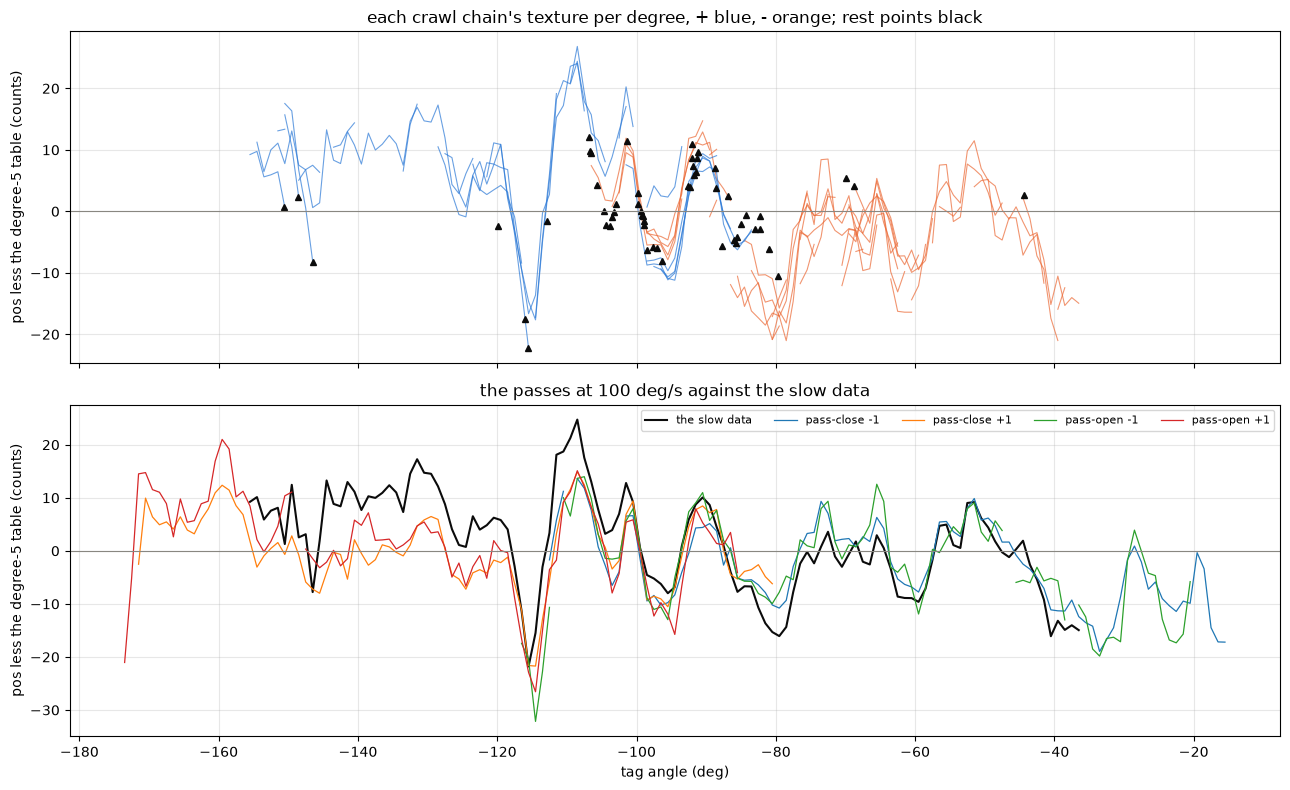

In [37]:
fig, ax = plt.subplots(2, 1, figsize=(13, 8), sharex=True)
for (d, share), g in SLOW.groupby(["dir", "share"]):
    for k, gk in g.groupby("k"):
        b = bins_of(gk)
        ax[0].plot([i.mid for i in b.index], b.to_numpy(), "-", lw=0.8,
                   color=BLUE if d > 0 else ORANGE, alpha=0.7)
ax[0].plot(STILL["ang"], STILL["resid"], "^", color=INK, ms=4)
figures.label(ax[0], y="pos less the degree-5 table (counts)",
              title="each crawl chain's texture per degree, + blue, - "
              "orange; rest points black")
ref = bins_of(pd.concat([SLOW, STILL]))
ax[1].plot([i.mid for i in ref.index], ref.to_numpy(), "-", color=INK,
           lw=1.5, label="the slow data")
for (name, d), g in PASSES.groupby(["clip", "dir"]):
    b = bins_of(g)
    ax[1].plot([i.mid for i in b.index], b.to_numpy(), "-", lw=0.9,
               label=f"{name} {d:+d}")
ax[1].legend(fontsize=8, ncol=5)
figures.label(ax[1], x="tag angle (deg)",
              y="pos less the degree-5 table (counts)",
              title="the passes at 100 deg/s against the slow data")
for a in ax:
    a.axhline(0, color=MUTED, lw=0.8)
figures.finish(fig)

Top, every crawl chain's residual per degree about the degree-5 table, one line per chain, with the rest points. Chains at different duties from the same start trace the same wiggles, with a pairwise correlation of 0.93 and 2.1 counts sd of difference, and the timing-free rest points sit on the same wiggles. The texture is locked to the angle. Bottom, the slow data's texture with the four pass groups over it.

Two definitions of the texture's size appear in this notebook, and they measure different things. About the degree-5 table the residual per degree keeps the bends of 10 to 25 degrees that a degree-5 polynomial does not follow. The table of record's fine part, the 1.5 degree table less its 10 degree smooth part, keeps only what is finer than its smooth knots, and its offsets per segment take out the stamp lead times the speed. The fine texture of record is the second, 6 counts rms and 30 peak to peak, about 0.3 degrees rms.

## The converter's carry codes

The pot is read by the chip's 12-bit converter, and an ideal converter gives every code the same width. Here every driven row moving faster than 150 counts per second adds to the code it read a weight equal to its speed, so a code's sum is its width in counts of the local slope whatever speed it was crossed at, and a stall or a slow stretch does not read as a wide code. A code is missing when it was never output with output on both sides of it, and wide when its width is more than 2.5 times the running median of its 61 neighbors.

In [38]:
CODE_CPS = 150          # counts/s, a row crossing codes, not resting
CODE_BOX = 201          # rows, the 10 ms boxcar of the speed weight
NEIGHBORS = 61         # codes, the running median a width is against
WIDE_DNL = 1.5          # LSB over the median, a wide code
EDGE = 30               # codes, the ends of the swept range left out

widths = np.zeros(4096)
for (name, k), (df, meta, seg) in SWEEPS.items():
    driven = df[(df["seg"] > 0) & (df["duty_counts"] != 0)]
    for s, g in driven.groupby("seg"):
        if len(g) < 400:
            continue
        v = np.abs(np.gradient(boxcar(g["pos"], CODE_BOX)) * FS)
        m = v > CODE_CPS
        widths += np.bincount(g["pos"].to_numpy()[m].astype(int),
                              weights=v[m] / FS, minlength=4096)[:4096]
lo_c, hi_c = np.flatnonzero(widths)[[0, -1]]
CODES = np.arange(lo_c + EDGE, hi_c - EDGE)
local = pd.Series(widths).rolling(NEIGHBORS, center=True).median()
with np.errstate(invalid="ignore"):     # the median is NaN at the ends
    DNL = widths / local.to_numpy() - 1
seen = widths > 0
driven_rows = sum(int((df["duty_counts"] != 0).sum())
                  for df, _, _ in SWEEPS.values())
print(f"{driven_rows / 1e6:.2f} M driven rows; codes {lo_c} to {hi_c} seen")

1.15 M driven rows; codes 274 to 3596 seen


In [39]:
def runs(codes):
    """Consecutive codes grouped as (first, last)."""
    out = []
    for c in codes:
        if out and c == out[-1][1] + 1:
            out[-1][1] = c
        else:
            out.append([c, c])
    return [tuple(r) for r in out]


MISSING_RUNS = runs([int(c) for c in CODES if not seen[c]])
# the traps note's rule: missing with output within 8 codes on both sides
eight = [c for c in CODES if not seen[c] and seen[max(c - 8, 0):c].any()
         and seen[c + 1:c + 9].any()]
WIDE = [int(c) for c in CODES if DNL[c] > WIDE_DNL]
others = np.setdiff1d(CODES, WIDE + eight)
print(f"codes {CODES[0]} to {CODES[-1]}; never output: {MISSING_RUNS}")
print(f"{len(eight)} codes missing by the 8-code rule; wide: "
      + ", ".join(f"{c} ({widths[c] / local[c]:.1f} LSB)" for c in WIDE))
print(f"every other code: DNL sd {np.nanstd(DNL[others]):.2f} LSB")

codes 304 to 3565; never output: [(512, 517), (768, 768), (1024, 1034), (1280, 1281), (2048, 2058), (2304, 2305), (2560, 2565), (3328, 3329)]
29 codes missing by the 8-code rule; wide: 511 (4.6 LSB), 1023 (12.8 LSB), 1279 (3.1 LSB), 2047 (7.9 LSB), 2559 (5.9 LSB)
every other code: DNL sd 0.26 LSB


Every missing run starts at a multiple of 256, and every wide code sits just below one, at 511, 1023, 1279, 2047 and 2559. All other codes have a differential nonlinearity of 0.26 LSB sd. How much horn angle a wide code covers comes from the tag. For each crossing of a wide code by a driven segment, the rows at the code times the tag's speed across the crossing give the degrees the horn turned while the pot read that one code.

In [40]:
crossings = []
for w in WIDE:
    for (name, k), (df, meta, seg) in SWEEPS.items():
        a = TAGS[name][TAGS[name]["both"]]
        driven = df[(df["seg"] > 0) & (df["duty_counts"] != 0)]
        for s, g in driven.groupby("seg"):
            p, h = g["pos"].to_numpy(), g["host"].to_numpy()
            on = np.flatnonzero(p == w)
            if not ((p < w - 3).any() and (p > w + 3).any()) or len(on) < 20:
                continue                # not a crossing of this code
            t0, t1 = h[on[0]], h[on[-1]]
            fa = a[(a["host"] > t0 - 0.05) & (a["host"] < t1 + 0.05)]
            if len(fa) < 4:
                continue
            speed = np.polyfit(fa["host"] - t0, fa[ANGLE], 1)[0]
            crossings.append({"code": w, "clip": name, "k": k, "seg": s,
                              "rows": len(on), "deg": len(on) / FS * abs(speed),
                              "dwell_ms": (t1 - t0) * 1e3})
CROSS = pd.DataFrame(crossings)
CODE_DEG = CROSS.groupby("code")["deg"].agg(["mean", "std", "size"])
show(CODE_DEG.reset_index(), n=None)

,code,mean,std,size
0,511,0.200,0.023,10
1,1023,0.623,0.102,15
2,1279,0.195,0.049,15
3,2047,0.714,0.125,18
4,2559,0.323,0.063,17


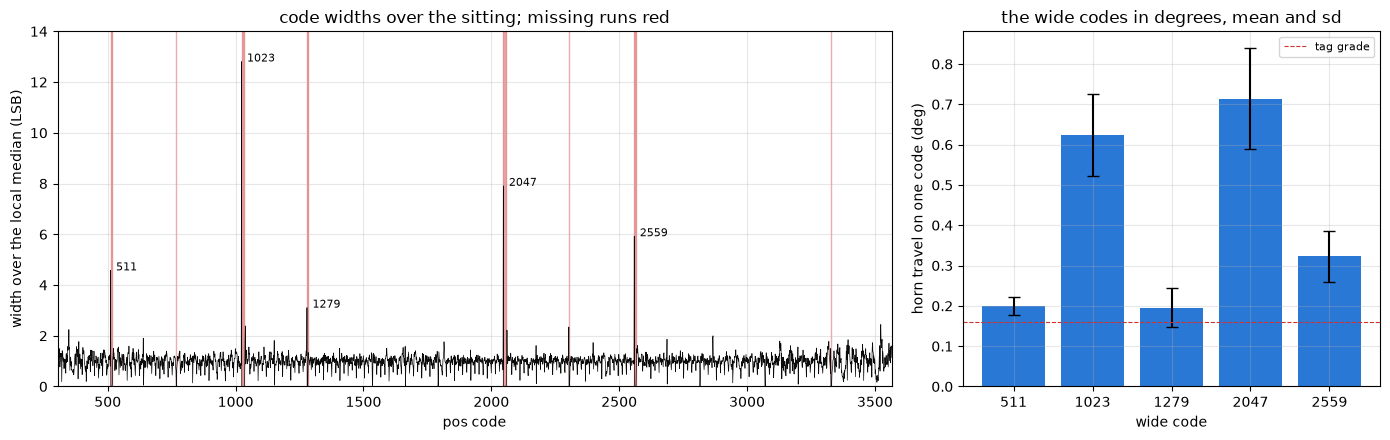

In [41]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4.5),
                       gridspec_kw={"width_ratios": [2, 1]})
ax[0].plot(np.arange(4096), widths / local, "-", color=INK, lw=0.5)
for r in MISSING_RUNS:
    ax[0].axvspan(r[0] - 0.5, r[1] + 0.5, color=RED, alpha=0.4)
for c in WIDE:
    ax[0].annotate(str(c), (c, widths[c] / local[c]), fontsize=8,
                   textcoords="offset points", xytext=(4, 0))
ax[0].set_xlim(CODES[0], CODES[-1])
ax[0].set_ylim(0, 14)
figures.label(ax[0], x="pos code", y="width over the local median (LSB)",
              title="code widths over the sitting; missing runs red")
ax[1].bar(CODE_DEG.index.astype(str), CODE_DEG["mean"],
          yerr=CODE_DEG["std"], color=BLUE, capsize=4)
ax[1].axhline(TAG_GRADE_DEG, **figures.HIGHLIGHT_STYLE, label="tag grade")
ax[1].legend(fontsize=8)
figures.label(ax[1], x="wide code", y="horn travel on one code (deg)",
              title="the wide codes in degrees, mean and sd")
figures.finish(fig)

Left, each code's width against its neighbors, the missing runs shaded. Right, the horn travel read as one code at each wide code. Code 2047 covers 0.71 +/- 0.13 degrees of horn (sd, 18 crossings) and code 1023 0.62 +/- 0.10 (15 crossings), four times the tag's grade. A rest on 2047 reads with no noise at all, since the code is wider than the pot's noise.

This is a property of the stream every notebook reads, the same over all 1.15 M driven rows of the sitting. The likely reading is the converter's capacitor array at its major carries, since the codes fall on binary positions whatever the pot does, and a feature of the pot's track would not land on multiples of 256. The consequence for a position table is that a table read from this stream holds a step at each carry, measured below, and that near mid travel the pot reports one code over 0.7 degrees of horn, so any position near 2047 counts is known to that width and no finer. The 1.5 degree knots of the table of record smear these steps. A firmware table can mask the carry codes, correct them, or carry them as they are, and that choice belongs to the firmware's design.

What the carries do to the pot's reading against the angle. Over the slow data of the texture section, the residual within 12 counts of each multiple of 256 less the residual 12 to 36 counts either side gives the step the carry puts into a table.

In [42]:
carry_rows = []
for c in range(512, 3584, 256):
    gap = (SLOW["pos"] - c).abs()
    near, side = SLOW[gap <= 12], SLOW[(gap > 12) & (gap <= 36)]
    if len(near) > 5 and len(side) > 5:
        carry_rows.append({"carry": c, "near_n": len(near),
                           "step_counts": near["resid"].mean()
                           - side["resid"].mean()})
CARRY = pd.DataFrame(carry_rows)
rest_2047 = NOISE.loc[NOISE["pot_sd"].idxmin()]
show(CARRY, n=None)
print(f"step per carry {CARRY['step_counts'].min():+.1f} to "
      f"{CARRY['step_counts'].max():+.1f} counts; the stillest baseline, "
      f"{rest_2047['clip']} chain {rest_2047['k']}, pot sd "
      f"{rest_2047['pot_sd']:.2f}")

,carry,near_n,step_counts
0,768,10,3.956
1,1024,8,-2.098
2,1280,7,1.908
3,1536,20,0.669
4,1792,26,-4.754
5,2048,65,-0.639
6,2304,30,-2.206
7,2560,38,-0.693
8,2816,12,-1.490


step per carry -4.8 to +4.0 counts; the stillest baseline, reversal chain 0, pot sd 0.00


The steps run -4.8 to +4.0 counts over the nine carries the slow data cross, the largest at 1792 and 768, inside the texture's own size, and the texture does not come from the carries. It survives with every frame within 12 counts of a multiple of 256 left out, as the chain-pair correlation and the pass shares above show.

## Drift and hysteresis

The rest points carry no timing, so they are the clean test of both. Drift is the table's level at the closing pass less at the opening pass, from the rest points of each, and the trend of every rest point's residual about the table over the sitting. Hysteresis is the rest reading arriving in the - direction less arriving in the + direction, over the coasts whose drive came from each side.

In [43]:
REST["minutes"] = (REST["host"] - REST["host"].min()) / 60
opened = REST[REST["clip"] == "pass-open"]["resid"]
closed = REST[REST["clip"] == "pass-close"]["resid"]
DRIFT = closed.mean() - opened.mean()
DRIFT_SE = np.hypot(closed.std() / np.sqrt(len(closed)),
                    opened.std() / np.sqrt(len(opened)))
(trend, _), trend_cov = np.polyfit(REST["minutes"], REST["resid"], 1,
                                   cov=True)
plus = REST[REST["approach"] == 1]["resid"]
minus = REST[REST["approach"] == -1]["resid"]
HYST = minus.mean() - plus.mean()       # counts, from - less from +
HYST_SE = np.hypot(minus.std() / np.sqrt(len(minus)),
                   plus.std() / np.sqrt(len(plus)))
print(f"close less open: {DRIFT:+.2f} +/- {DRIFT_SE:.2f} counts "
      f"({len(opened)} and {len(closed)} rest points); trend "
      f"{10 * trend:+.2f} +/- {10 * np.sqrt(trend_cov[0, 0]):.2f} counts "
      f"per 10 min over {REST['minutes'].max():.1f} min, {len(REST)} points")
print(f"arriving - less arriving +: {HYST:+.2f} +/- {HYST_SE:.2f} counts "
      f"({len(minus)} and {len(plus)}), {HYST / SCALE:+.3f} deg")
passes = MOVING[MOVING["clip"].str.startswith("pass")]
PASS_COVER = passes.groupby(["clip", "dir_s"])[ANGLE].agg(["min", "max"])
show(PASS_COVER.reset_index(), n=None)

close less open: -0.06 +/- 1.98 counts (3 and 3 rest points); trend -0.82 +/- 1.03 counts per 10 min over 14.5 min, 75 points
arriving - less arriving +: +1.78 +/- 0.70 counts (17 and 17), +0.094 deg


,clip,dir_s,min,max
0,pass-close,-1.000,-106.795,-28.648
1,pass-close,1.000,-160.261,-87.091
2,pass-open,-1.000,-108.452,-32.303
3,pass-open,1.000,-163.202,-92.733


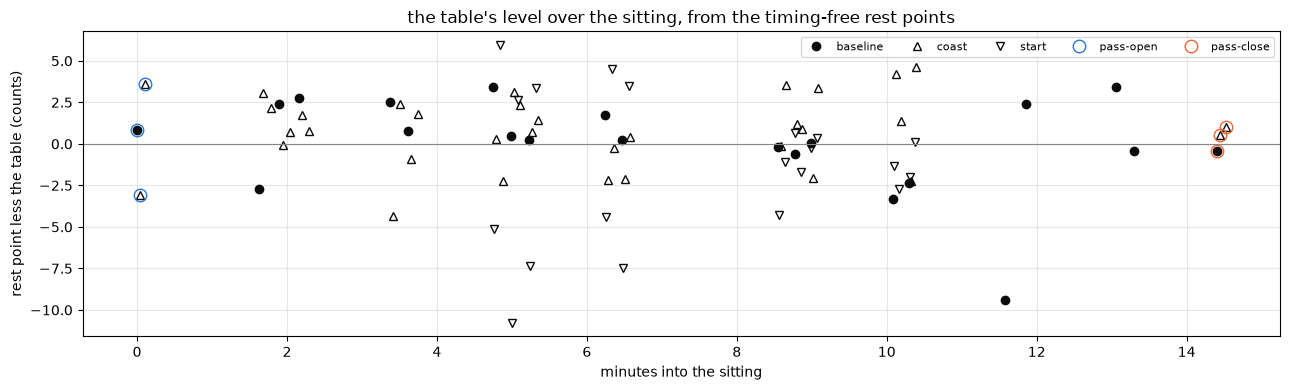

In [44]:
fig, ax = plt.subplots(figsize=(13, 4))
for kind, marker in (("baseline", "o"), ("coast", "^"), ("start", "v")):
    g = REST[REST["kind"] == kind]
    ax.plot(g["minutes"], g["resid"], marker, ls="none", color=INK,
            mfc="none" if kind != "baseline" else INK, label=kind)
for name, color in (("pass-open", BLUE), ("pass-close", ORANGE)):
    g = REST[REST["clip"] == name]
    ax.plot(g["minutes"], g["resid"], "o", ms=9, mfc="none", color=color,
            label=name)
ax.axhline(0, color=MUTED, lw=0.8)
ax.legend(fontsize=8, ncol=5)
figures.label(ax, x="minutes into the sitting",
              y="rest point less the table (counts)",
              title="the table's level over the sitting, from the "
              "timing-free rest points")
figures.finish(fig)

The rest points over the 14.5 minutes of the sitting, the two passes circled. The closing pass sits -0.06 +/- 1.98 counts from the opening pass, and the trend over all 75 rest points is -0.8 +/- 1.0 counts per 10 minutes. No drift shows above 2 sigma, which bounds it at about 4 counts, 0.2 degrees, over the sitting. The support is thin, three rest points at each pass, since each pass direction covers only half the travel.

Arriving in the - direction, the pot reads 1.8 +/- 0.7 counts higher than arriving in the + direction, 0.09 degrees, at 2.5 sigma on 17 rest points a side. The direction term of the stamp-lead fit below reads +0.8 +/- 0.6 counts the other way round under motion. Hysteresis is not established, and the bound of record is under 3 counts, 0.15 degrees, with low confidence.

## The stamp lead

Under motion the pot and the tag do not agree segment by segment, and what that looked like first was a hysteresis. The table's offsets per moving segment split by the direction of motion, the pot reading higher than the table going + and lower going -, which reads like a dead band of 0.5 degrees between the pot and the horn, or the case twisting in its pocket under the motor's reaction torque.

In [45]:
o = MOVING.groupby("sid").agg(
    clip=("clip", "first"), k=("k", "first"), seg=("seg", "first"),
    dir=("dir_s", "median"), v=("pos_speed", "mean"), t=("host", "mean"),
    n=("pos", "size"))
o["c"] = o.index.map(OFFSETS)
o["lead_s"] = [LEAD_OF[(r["clip"], r["k"],
                        int(SWEEPS[(r["clip"], r["k"])][2].loc[r["seg"],
                                                               "dir"]))]
               for _, r in o.iterrows()]
o["c_lead"] = o["c"] - o["lead_s"] * o["v"]   # the chain's lead taken out
SEG_OFFSETS = o
by_dir = o.groupby("dir")["c"].agg(["mean", "std", "size"])
show(by_dir.reset_index(), n=None)


def regress(df, y, cols):
    """Least squares of y on a constant and cols, with standard errors."""
    X = np.column_stack([np.ones(len(df))] + [df[c] for c in cols])
    b = np.linalg.lstsq(X, df[y], rcond=None)[0]
    r = df[y] - X @ b
    cov = np.linalg.pinv(X.T @ X) * np.sum(r ** 2) / max(1, len(df) - len(b))
    return b, np.sqrt(np.diag(cov)), np.sqrt(np.mean(r ** 2))

,dir,mean,std,size
0,-1.000,-4.660,8.213,25
1,1.000,4.990,7.906,25


A lead $\tau$ ("tau") of the pot's stamps against the motion makes a segment's offset $\tau v$, with $v$ the segment's speed in counts per second, so it flips with the direction and grows with the speed. A dead band or a twist gives a constant per direction whatever the speed. Each crawl clip holds two or three chains at different speeds inside a minute, so within a clip the two separate, $c = c_0 + h \, \mathrm{dir} + \tau v$. The clips with four or more moving segments are fitted that way.

In [46]:
clip_rows = []
for name, g in o.groupby("clip", sort=False):
    if len(g) < 4:
        continue
    b, se, rms = regress(g, "c", ["dir", "v"])
    clip_rows.append({"clip": name, "segments": len(g), "h_counts": b[1],
                      "h_se": se[1], "tau_ms": b[2] * 1e3,
                      "tau_se_ms": se[2] * 1e3, "rms": rms,
                      "minutes": (g["t"].mean() - first_t) / 60})
PER_CLIP = pd.DataFrame(clip_rows)
show(PER_CLIP, n=None)
three = PER_CLIP[PER_CLIP["segments"] >= 6]   # three speeds or more
H_THREE = (three["h_counts"].mean(),
           three["h_counts"].std() / np.sqrt(len(three)))
b, se, rms = regress(o, "c_lead", ["dir"])
print(f"h over the {len(three)} clips of three speeds "
      f"{H_THREE[0]:+.2f} +/- {H_THREE[1]:.2f} "
      f"counts; over all {len(o)} segments with each chain's lead out, dir "
      f"{b[1]:+.2f} +/- {se[1]:.2f} counts, rms {rms:.1f}")
for cols in (["dir"], ["v"]):
    b, se, rms = regress(o, "c", cols)
    print(f"offsets on {cols[0]} alone: rms {rms:.1f} counts")

,clip,segments,h_counts,h_se,tau_ms,tau_se_ms,rms,minutes
0,crawl-0-0,6,0.749,1.193,28.706,4.846,0.857,1.977
1,crawl-0-1,4,8.170,1.164,13.044,1.659,0.233,3.576
2,crawl-1-0,6,-0.401,1.209,28.605,3.382,0.582,5.061
3,crawl-1-1,4,9.806,0.729,6.700,1.023,0.132,6.427
4,crawl-2-0,6,-0.044,0.608,-4.088,1.576,0.256,8.835
5,crawl-2-1,4,0.465,2.700,-2.481,3.628,0.377,10.254
6,reversal,8,2.924,1.840,-4.035,1.264,1.990,11.810
7,steps,8,0.681,2.329,-1.471,3.837,0.818,13.257


h over the 5 clips of three speeds +0.78 +/- 0.58 counts; over all 50 segments with each chain's lead out, dir -0.39 +/- 1.05 counts, rms 7.3
offsets on dir alone: rms 7.9 counts
offsets on v alone: rms 8.5 counts


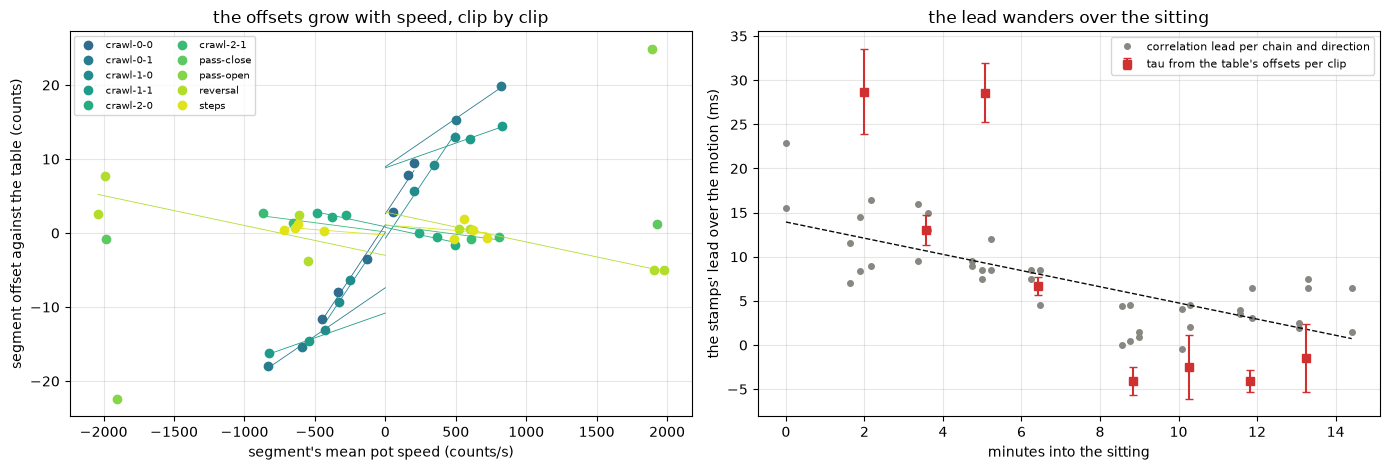

In [47]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4.8))
for (name, g), color in zip(o.groupby("clip", sort=False),
                            figures.shades("viridis", o["clip"].nunique())):
    ax[0].plot(g["v"], g["c"], "o", color=color, label=name)
    row = PER_CLIP[PER_CLIP["clip"] == name]
    if len(row):
        b, _, _ = regress(g, "c", ["dir", "v"])
        for d, end in ((1, g["v"].max()), (-1, g["v"].min())):
            v = np.array([0.0, end])    # + speeds go +, - speeds go -
            ax[0].plot(v, b[0] + b[1] * d + b[2] * v, "-", color=color,
                       lw=0.6)
ax[0].legend(fontsize=7, ncol=2)
figures.label(ax[0], x="segment's mean pot speed (counts/s)",
              y="segment offset against the table (counts)",
              title="the offsets grow with speed, clip by clip")
ax[1].plot(LEAD["minutes"], LEAD["lead_ms"], "o", color=MUTED, ms=4,
           label="correlation lead per chain and direction")
m = np.linspace(0, LEAD["minutes"].max(), 2)
ax[1].plot(m, LEAD_LINE["intercept"] + LEAD_LINE["slope"] * m, "--",
           color=INK, lw=1)
ax[1].errorbar(PER_CLIP["minutes"], PER_CLIP["tau_ms"],
               yerr=PER_CLIP["tau_se_ms"], fmt="s", color=RED, capsize=3,
               label="tau from the table's offsets per clip")
ax[1].legend(fontsize=8)
figures.label(ax[1], x="minutes into the sitting",
              y="the stamps' lead over the motion (ms)",
              title="the lead wanders over the sitting")
figures.finish(fig)

Left, each moving segment's offset against its speed, one color per clip, with each clip's fit through it. Inside a clip the offsets lie on a line through the origin in speed, the signature of a time lead, and the slope changes from clip to clip. Right, the lead two ways. The per-clip $\tau$ from the table's offsets, in red, starts near +29 ms in the first crawl clips and falls to about -4 ms by the reversal and steps clips. The correlation lead of each chain and direction, in grey, which needs no table, falls the same way, from about +23 ms at the opening pass to about 0 late in the sitting, on a line of -0.92 ms per minute with 3.4 ms rms about it.

The direction split is the lead, with high confidence. A lead of 9 ms at 30 degrees per second, 570 counts per second, is 5 counts, the size of the split, and at the opening pass's 1900 counts per second the same lead makes the 25 counts its offsets show. With each chain's correlation lead taken out the direction term over all 50 segments is -0.4 +/- 1.1 counts, and inside the five clips with three speeds or more it is +0.8 +/- 0.6, both nothing. A twist of the case or a loose horn would not scale with speed and would not change sign late in the sitting.

What drifts is the stamps. The camera's clock is fitted per clip to 1 to 2.5 ms and shows no growth inside a clip. The lead is a property of the host's segment stamps against the motion the servo makes, 0 to 30 ms and wandering, likely the stamp taken when `osc-lab` sends a step while the servo starts it a varying time later, or the host's serial batching. It is filed as notebooks#63, a tooling issue, with the fix to log the first telemetry row's arrival beside the command's stamp and to clap at both ends of a clip. After the per-chain alignment the lead's scatter about its line over the sitting is the 4 ms floor of any pot timing in this notebook.

## The crawl

Thirty holds, 6 to 11 % at 5 V, each direction from three starts. A hold is read from 200 ms after it opens, the kick's spin-down out, to 20 ms before it ends. Its speed is a line through the tag's angle over that window, and the pot's a line through the pot taken through the table's inverse, so both are in output degrees. A stop is a stretch of 40 ms or more where the pot's slope over 20 ms, of its 10 ms boxcar, is under 1 degree per second, and a hold stalled if it ends stopped.

In [48]:
HOLD_SKIP_S = 0.2       # s, the kick's spin-down out of a hold
STOP_DEG_S = 1.0        # deg/s, the pot's 20 ms slope under it is stopped
STOP_MIN_S = 0.04       # s, a stop lasts at least this long
STOP_ROWS = 400         # rows, the 20 ms slope of a stop
inc = np.r_[True, np.diff(T_GRID) > 0]  # the table's increasing stretch


def pot_deg(p):
    """The pot through the table's inverse, in tag degrees."""
    return np.interp(p, T_GRID[inc], GRID[inc], left=np.nan, right=np.nan)


def stops_of(pos):
    """[(first, last) rows] of the stops in a hold, and the slow mask."""
    ps = boxcar(pos, CODE_BOX)
    v = np.full(len(ps), np.nan)
    v[STOP_ROWS // 2:-STOP_ROWS // 2] = ((ps[STOP_ROWS:] - ps[:-STOP_ROWS])
                                         / (STOP_ROWS / FS) / SCALE)
    v = pd.Series(v).bfill().ffill().to_numpy()
    slow = np.abs(v) < STOP_DEG_S
    e = np.diff(np.r_[0, slow.astype(int), 0])
    runs_ = zip(np.flatnonzero(e == 1), np.flatnonzero(e == -1))
    return [(i, j) for i, j in runs_ if (j - i) / FS >= STOP_MIN_S], slow


def hold_window(name, k, s):
    """(rows, tag frames, window start) of one hold."""
    df, _, seg = SWEEPS[(name, k)]
    g = df[df["seg"] == s]
    w0, w1 = g["host"].iloc[0] + HOLD_SKIP_S, g["host"].iloc[-1] - END_S
    a = TAGS[name][TAGS[name]["both"]]
    return (g[(g["host"] >= w0) & (g["host"] <= w1)],
            a[(a["host"] >= w0) & (a["host"] <= w1)], w0)

In [49]:
def hold_row(name, k, s):
    """Speeds, stops and the window of one crawl hold."""
    gw, fa, w0 = hold_window(name, k, s)
    chain = CHAINS[(CHAINS["clip"] == name) & (CHAINS["k"] == k)].iloc[0]
    span = gw["host"].iloc[-1] - gw["host"].iloc[0]
    stops, slow = stops_of(gw["pos"])
    p = pot_deg(boxcar(gw["pos"], BOX_ROWS))
    ok = np.isfinite(p)
    return {"clip": name, "k": k, "seg": s,
            "dir": int(SWEEPS[(name, k)][2].loc[s, "dir"]),
            "duty_pct": int(chain["duty_pct"]),
            "share": round(float(chain["start_share"]), 3), "window_s": span,
            "tag_deg_s": np.polyfit(fa["host"] - w0, fa[ANGLE], 1)[0],
            "pot_deg_s": np.polyfit(gw["host"].to_numpy()[ok] - w0, p[ok],
                                    1)[0],
            "stops": len(stops),
            "stopped_share": sum(j - i for i, j in stops) / FS / span,
            "ends_stopped": bool(slow[-int(0.05 * FS):].all()),
            "angle_lo": fa[ANGLE].min(), "angle_hi": fa[ANGLE].max()}


CRAWL = pd.DataFrame([hold_row(name, k, s)
                      for name, (_, _, ks) in CLIPS.items()
                      if name.startswith("crawl") for k in ks for s in (2, 5)])
CRAWL["speed"] = CRAWL["tag_deg_s"].abs()
BY_DUTY = CRAWL.groupby("duty_pct").agg(
    holds=("speed", "size"), mean=("speed", "mean"), sd=("speed", "std"),
    lo=("speed", "min"), hi=("speed", "max"), stalled=("ends_stopped", "sum"))
show(BY_DUTY.reset_index(), n=None)

,duty_pct,holds,mean,sd,lo,hi,stalled
0,6,6,6.407,6.126,0.006,14.961,4
1,7,6,15.248,7.630,0.086,20.696,1
2,8,6,20.774,9.955,0.649,26.180,1
3,9,6,30.565,2.843,25.073,32.680,0
4,11,6,44.319,1.078,42.365,45.445,0


In [50]:
running = CRAWL[(CRAWL["stopped_share"] < 0.02)]
in_band = CRAWL[(CRAWL["speed"] >= 2) & (CRAWL["speed"] <= 5)
                & ~CRAWL["ends_stopped"] & (CRAWL["stops"] == 0)]
moving_at_end = CRAWL[~CRAWL["ends_stopped"]]
ratio = (CRAWL["pot_deg_s"] / CRAWL["tag_deg_s"])[CRAWL["speed"] > 5]
POT_TAG = (ratio.mean(), ratio.std() / np.sqrt(len(ratio)), len(ratio))
show(CRAWL[CRAWL["ends_stopped"] | (CRAWL["duty_pct"] == 6)][
    ["clip", "k", "dir", "duty_pct", "share", "window_s", "speed", "stops",
     "ends_stopped", "angle_lo", "angle_hi"]], n=None)
print(f"slowest hold with no stop: {running['speed'].min():.1f} deg/s at "
      f"{running.loc[running['speed'].idxmin(), 'duty_pct']} %; slowest "
      f"still moving at its end: {moving_at_end['speed'].min():.1f} deg/s")
print(f"holds sustained inside 2 to 5 deg/s: {len(in_band)}; pot over tag "
      f"speed {POT_TAG[0]:.4f} +/- {POT_TAG[1]:.4f} ({POT_TAG[2]} holds)")

,clip,k,dir,duty_pct,share,window_s,speed,stops,ends_stopped,angle_lo,angle_hi
0,crawl-0-0,0,1,6,0.000,1.915,0.006,1,True,-148.726,-148.594
1,crawl-0-0,0,-1,6,0.000,1.915,0.329,1,True,-44.452,-42.535
2,crawl-0-0,1,1,7,0.000,1.610,0.086,1,True,-147.067,-146.358
4,crawl-0-0,2,1,8,0.000,1.381,0.649,1,True,-152.752,-150.576
10,crawl-1-0,5,1,6,0.167,1.271,3.977,1,True,-121.476,-115.444
11,crawl-1-0,5,-1,6,0.167,1.271,7.300,1,True,-68.890,-59.379
20,crawl-2-0,10,1,6,0.333,0.628,11.869,0,False,-96.422,-89.189
21,crawl-2-0,10,-1,6,0.333,0.628,14.961,0,False,-98.550,-89.207


slowest hold with no stop: 11.9 deg/s at 6 %; slowest still moving at its end: 11.9 deg/s
holds sustained inside 2 to 5 deg/s: 0; pot over tag speed 1.0015 +/- 0.0017 (25 holds)


Below 9 % a hold either ran at about 12 degrees per second or more, or stopped, and no hold sustained 2 to 5 degrees per second. The stalls follow position. The + holds from the low guard stalled at 6, 7 and 8 %, near -150 degrees, and the - hold from the high guard stalled at 6 %, while the 6 % holds from a third in ran 11.9 and 15.0 degrees per second over their 0.63 s windows and were still moving when the windows ended. The slowest hold at 7 % or more that never stopped ran 16.1 degrees per second. Moving + from the low guard took 9 %. The pot's speed through the table agrees with the tag's to 0.2 %.

### One stop, or stick-slip

A hold that stops can stop once, or stop and start again, the stick-slip a crawl at its floor might show. Every hold at 6 to 8 % is read on the tag. Its speed is the gradient of its angle smoothed over 50 ms, a stop is 40 ms or more under 0.5 degrees per second, and a restart is 0.3 degrees of further motion after a stop ends. A bare 1 degree per second rule counts the tag's own noise as restarts.

In [51]:
RESTART_DEG = 0.3       # deg, further motion after a stop: a restart
STILL_DEG_S = 0.5       # deg/s, the tag's speed under it is stopped


def tag_stops(name, k, s):
    """(t, angle, speed, [(start, end)] stops) of one hold on the tag."""
    df, _, _ = SWEEPS[(name, k)]
    f = pairs(name, k, (s,), LEAD_OF)   # frames the pot covers at the lead
    t = (f["host"] - df.loc[df["seg"] == s, "host"].min()).to_numpy()
    ang = f[ANGLE].to_numpy()
    n = max(3, int(0.05 / np.median(np.diff(t))))
    v = np.gradient(uniform_filter1d(ang, n), t)
    still_ = np.abs(v) < STILL_DEG_S
    e = np.diff(np.r_[0, still_.astype(int), 0])
    found = [(t[i], t[j - 1]) for i, j in zip(np.flatnonzero(e == 1),
                                             np.flatnonzero(e == -1))
             if t[j - 1] - t[i] >= STOP_MIN_S]
    return t, ang, v, found


slip_rows, SLIP_TRACES = [], {}
for _, r in CRAWL[CRAWL["duty_pct"] <= 8].iterrows():
    t, ang, v, found = tag_stops(r["clip"], r["k"], r["seg"])
    restarts = sum(bool((np.abs(ang[t > e] - np.interp(e, t, ang))
                         > RESTART_DEG).any()) for _, e in found)
    first = found[0][0] if found else np.nan
    slip_rows.append({"k": r["k"], "dir": r["dir"], "duty_pct": r["duty_pct"],
                      "share": r["share"], "stops": len(found),
                      "restarts": restarts, "first_stop_s": first,
                      "moved_after_deg": abs(ang[-1] - np.interp(first, t, ang))
                      if found else 0.0})
    SLIP_TRACES[(r["k"], r["dir"])] = (t, ang - ang[0], v)
SLIP = pd.DataFrame(slip_rows)
show(SLIP[SLIP["stops"] > 0], n=None)
print(f"holds with a restart: {int((SLIP['restarts'] > 0).sum())} of "
      f"{len(SLIP)}")

,k,dir,duty_pct,share,stops,restarts,first_stop_s,moved_after_deg
0,0,1,6,0.000,9,0,0.283,0.034
1,0,-1,6,0.000,13,0,0.499,0.011
2,1,1,7,0.000,10,0,0.420,0.047
4,2,1,8,0.000,6,0,0.696,0.009
6,5,1,6,0.167,5,0,0.888,0.026
7,5,-1,6,0.167,3,0,1.004,0.013


holds with a restart: 0 of 18


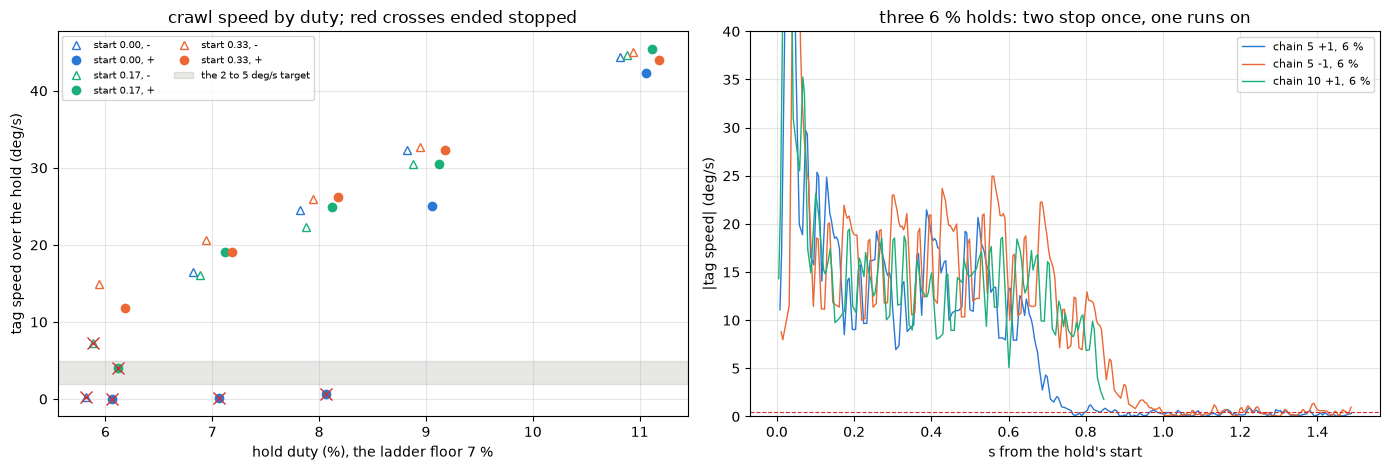

In [52]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4.8))
shade = dict(zip((0.0, 0.167, 0.333), (BLUE, GREEN, ORANGE)))
for (share, d), g in CRAWL.groupby(["share", "dir"]):
    jitter = 0.12 * d + 0.06 * (share * 6 - 1)
    ax[0].plot(g["duty_pct"] + jitter, g["speed"],
               **figures.direction_style(d, shade[share]),
               label=f"start {share:.2f}, {'+' if d > 0 else '-'}")
    st = g[g["ends_stopped"]]
    ax[0].plot(st["duty_pct"] + jitter, st["speed"], "x", color=RED, ms=9)
ax[0].axhspan(2, 5, color=MUTED, alpha=0.2, label="the 2 to 5 deg/s target")
ax[0].legend(fontsize=7, ncol=2)
figures.label(ax[0], x="hold duty (%), the ladder floor 7 %",
              y="tag speed over the hold (deg/s)",
              title="crawl speed by duty; red crosses ended stopped")
for key, color in (((5, 1), BLUE), ((5, -1), ORANGE), ((10, 1), GREEN)):
    t, ang, v = SLIP_TRACES[key]
    ax[1].plot(t, np.abs(v), "-", color=color, lw=1,
               label=f"chain {key[0]} {key[1]:+d}, 6 %")
ax[1].axhline(STILL_DEG_S, **figures.HIGHLIGHT_STYLE)
ax[1].set_ylim(0, 40)
ax[1].legend(fontsize=8)
figures.label(ax[1], x="s from the hold's start", y="|tag speed| (deg/s)",
              title="three 6 % holds: two stop once, one runs on")
figures.finish(fig)

Left, every hold's speed by its duty, one color per start, filled for + and open for -, red crosses on the holds that ended stopped, the shaded band the README's target. Speed spreads widely at 6 to 8 % and tightens at 9 and 11 %. Right, the tag's speed through the two 6 % holds from a sixth in, each one deceleration to a stop that lasts, and a 6 % hold from a third in that runs on. Every stalled hold stopped once and stayed stopped, moving 0.05 degrees or less after its first stop. There is no stick-slip at 6 %.

The speed per percent of duty near the floor, two ways. Over the holds that never stopped at 7 to 11 %, a line of speed on duty, and over every hold still moving, the line the second analysis drew from its own window that opens 300 ms in. The holds' route is the number for a design, since the steps below are confounded by position.

In [53]:
def speed_line(df):
    """(deg/s per %, its se, the duty where it reaches zero)."""
    (b1, b0), cov = np.polyfit(df["duty_pct"], df["speed"], 1, cov=True)
    return b1, np.sqrt(cov[0, 0]), -b0 / b1


late = []
for _, r in CRAWL.iterrows():
    t, ang, _, _ = tag_stops(r["clip"], r["k"], r["seg"])
    m = t >= 0.3                        # the second analysis's window
    late.append(abs(np.polyfit(t[m], ang[m], 1)[0]))
CRAWL["speed_after_0p3"] = late
held_route = speed_line(running[running["duty_pct"] >= 7])
all_route = speed_line(CRAWL[CRAWL["speed_after_0p3"] > 1].assign(
    speed=lambda x: x["speed_after_0p3"]))
# rev/s per V effective, times the volts of 1 % on the rail
LADDER_DEG_PER_PCT = LADDER_LINE["value"] * RAIL_V / 100 * 360 / GEAR
for name, (b, se, zero) in (("running holds, 7 to 11 %", held_route),
                            ("every moving hold", all_route)):
    print(f"{name}: {b:.2f} +/- {se:.2f} deg/s per %, zero at {zero:.1f} %")
print(f"the ladder's crawl line on 5 V: {LADDER_DEG_PER_PCT:.2f} deg/s per %")

running holds, 7 to 11 %: 6.50 +/- 0.27 deg/s per %, zero at 4.2 %
every moving hold: 6.84 +/- 0.29 deg/s per %, zero at 4.5 %
the ladder's crawl line on 5 V: 5.82 deg/s per %


## The ripple

A crawl's speed is not steady, and the tag sees it as a wobble of the angle about the hold's line. The question is what sets its frequency. A ripple locked to the angle of a gear repeats a fixed number of times per output degree, so its frequency in hertz rises with the speed. An oscillation of the train repeats at a fixed frequency in hertz whatever the speed. Each hold that moves faster than 5 degrees per second is read from 300 ms in, its angle less its line, and the same samples are given a normalized Lomb-Scargle periodogram twice, once against time in hertz and once placed on the mean motion's angle, $x = v t$, in cycles per output degree. The two pooled spectra over the same holds say which axis holds the line, the taller and narrower one.

In [54]:
RIPPLE_SKIP_S = 0.3     # s, the hold's start out
MIN_DEG_S = 5.0         # deg/s, a hold fast enough for a spectrum
F_HZ = np.linspace(0.2, 30, 3000)       # Hz
F_CPD = np.linspace(0.01, 0.6, 3000)    # cycles per output degree
spec_hz, spec_cpd, rip_rows = [], [], []
for _, r in CRAWL.iterrows():
    t, ang, _, _ = tag_stops(r["clip"], r["k"], r["seg"])
    m = t >= RIPPLE_SKIP_S
    t, ang = t[m], ang[m]
    b, a0 = np.polyfit(t, ang, 1)
    det = ang - (a0 + b * t)
    det -= det.mean()
    n = max(3, int(0.05 / np.median(np.diff(t))))
    v = np.gradient(uniform_filter1d(ang, n), t)
    row = {**r[["clip", "k", "dir", "duty_pct", "share"]].to_dict(),
           "v": abs(b), "amp_deg": det.std() * np.sqrt(2),
           "speed_ripple": np.std(v - v.mean()) * np.sqrt(2) / abs(b)}
    if abs(b) >= MIN_DEG_S and len(t) >= 20:
        p_hz = lombscargle(t, det, 2 * np.pi * F_HZ, normalize=True)
        p_cpd = lombscargle(abs(b) * t, det, 2 * np.pi * F_CPD,
                            normalize=True)
        spec_hz.append(p_hz)
        spec_cpd.append(p_cpd)
        row.update({"f_hz": F_HZ[np.argmax(p_hz)],
                    "cpd": F_CPD[np.argmax(p_cpd)]})
    rip_rows.append(row)
RIPPLE = pd.DataFrame(rip_rows)
P_HZ, P_CPD = np.mean(spec_hz, axis=0), np.mean(spec_cpd, axis=0)
print(f"{len(spec_hz)} holds over {MIN_DEG_S:g} deg/s")

25 holds over 5 deg/s


In [55]:
def line_stats(x, P):
    """The pooled line's peak, height and full width at half its height."""
    i = int(np.argmax(P))
    lo = hi = i
    while lo > 0 and P[lo] > P[i] / 2:
        lo -= 1
    while hi < len(P) - 1 and P[hi] > P[i] / 2:
        hi += 1
    return {"at": x[i], "height": P[i], "fwhm_rel": (x[hi] - x[lo]) / x[i]}


LINE_HZ, LINE_CPD = line_stats(F_HZ, P_HZ), line_stats(F_CPD, P_CPD)
bumps, _ = find_peaks(P_CPD)
top = bumps[np.argsort(P_CPD[bumps])[::-1][:3]]   # the three tallest
print("tallest bumps against angle: " + ", ".join(
    f"{F_CPD[i]:.3f} ({P_CPD[i]:.3f})" for i in top))
two = F_CPD[top[:2]]                    # the main line's flat top
TOP_CPD = (np.floor(two.min() * 100) / 100, np.ceil(two.max() * 100) / 100)
low = F_CPD < 0.07                      # the second line, below the first
SECOND_CPD = F_CPD[low][np.argmax(P_CPD[low])]
per = RIPPLE.dropna(subset=["cpd"])
FIT_HZ = results.fit_line(per["v"], per["f_hz"])
FIT_CPD = results.fit_line(per["v"], per["cpd"])
for name, s, unit in (("time", LINE_HZ, "Hz"), ("angle", LINE_CPD,
                                                "cycles/deg")):
    print(f"{name} domain: peak {s['height']:.2f} at {s['at']:.3f} {unit}, "
          f"width {100 * s['fwhm_rel']:.0f} % of its position")
print(f"second line {SECOND_CPD:.3f} cycles/deg ({1 / SECOND_CPD:.1f} deg); "
      f"per hold: Hz on speed {FIT_HZ['slope']:.3f} +/- "
      f"{FIT_HZ['slope_se']:.3f} per deg/s, cycles/deg on speed "
      f"{FIT_CPD['slope']:+.4f} +/- {FIT_CPD['slope_se']:.4f}")
print(f"spread per hold: {per['f_hz'].std() / per['f_hz'].mean():.0%} in Hz,"
      f" {per['cpd'].std() / per['cpd'].mean():.0%} in cycles/deg; "
      f"mid-travel holds {per[per['share'] > 0.3]['cpd'].mean():.3f} +/- "
      f"{per[per['share'] > 0.3]['cpd'].std():.3f}")

tallest bumps against angle: 0.166 (0.359), 0.143 (0.357), 0.039 (0.280)
time domain: peak 0.29 at 1.194 Hz, width 640 % of its position
angle domain: peak 0.36 at 0.166 cycles/deg, width 123 % of its position
second line 0.039 cycles/deg (25.6 deg); per hold: Hz on speed 0.094 +/- 0.037 per deg/s, cycles/deg on speed -0.0009 +/- 0.0011
spread per hold: 78% in Hz, 58% in cycles/deg; mid-travel holds 0.169 +/- 0.028


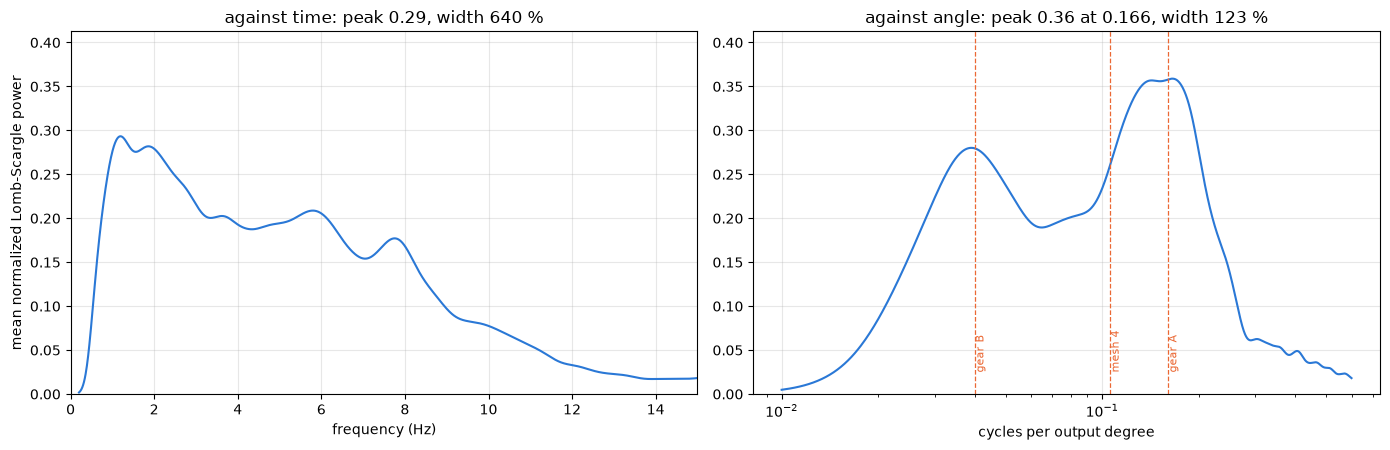

In [56]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4.6))
ax[0].plot(F_HZ, P_HZ, "-", color=BLUE, lw=1.5)
ax[0].set_xlim(0, 15)
figures.label(ax[0], x="frequency (Hz)",
              y="mean normalized Lomb-Scargle power",
              title=f"against time: peak {LINE_HZ['height']:.2f}, width "
              f"{100 * LINE_HZ['fwhm_rel']:.0f} %")
ax[1].plot(F_CPD, P_CPD, "-", color=BLUE, lw=1.5)
for name in ("gear A", "gear B", "mesh 4"):
    ax[1].axvline(LINES[name], color=ORANGE, lw=0.9, ls="--")
    ax[1].text(LINES[name], 0.02, f" {name}", fontsize=8,
               color=ORANGE, va="bottom", rotation=90)
ax[1].set_xscale("log")
for a in ax:                            # one power scale for both
    a.set_ylim(0, 1.15 * max(P_HZ.max(), P_CPD.max()))
figures.label(ax[1], x="cycles per output degree", title=f"against angle: "
              f"peak {LINE_CPD['height']:.2f} at {LINE_CPD['at']:.3f}, "
              f"width {100 * LINE_CPD['fwhm_rel']:.0f} %")
figures.finish(fig)

The same 25 holds and the same normalization, pooled against time on the left and against angle on the right, on one power scale. Against time the power smears from under 1 Hz to past 8 Hz, a peak of 0.29 with a width of over six times its position. Against angle it gathers into one line with a flat top, two bumps at 0.143 and 0.166 cycles per output degree within 1 % of each other in power, a period of 6 to 7 degrees, with a peak of 0.36 and a width of 1.2 times its position, and a second line at 0.039, a 25 degree period. Hold by hold the peak's frequency in hertz climbs with speed and its position in cycles per degree stays flat. The ripple is locked to the angle, with high confidence.

The train's lines, from the counted teeth, are dashed. Gear A's once per turn, 0.160, sits inside the main line's top, 0.14 to 0.17, and the holds at mid travel alone read 0.169 +/- 0.028. The final mesh's 0.106 sits below the top, on its lower flank. The second line is gear B's once per turn, 0.040, within 2 %. So the main line is most likely gear A turning, with the final mesh possibly adding to its width, and the second line gear B. Which of the two carries the main line is medium confidence. In hertz the ripple sits at 0.14 to 0.17 times the speed in degrees per second, 1 to 7.5 Hz over 7 to 45 degrees per second, so a notch that follows it has to move with the speed.

Its size, as the tag's wobble about each hold's line and as the swing of the tag's speed about its mean, by duty.

In [57]:
RIP_BY_DUTY = RIPPLE[RIPPLE["v"] > 1].groupby("duty_pct").agg(
    holds=("amp_deg", "size"), amp_deg=("amp_deg", "mean"),
    speed_ripple=("speed_ripple", "mean"))
show(RIP_BY_DUTY.reset_index(), n=None)
RIP_MOVING = RIPPLE[RIPPLE["v"] > 1]
amp = RIP_MOVING["amp_deg"]
print(f"amplitude {amp.mean():.2f} +/- {amp.std():.2f} deg (sd, {len(amp)} "
      f"holds), {amp.min():.2f} to {amp.max():.2f}")

,duty_pct,holds,amp_deg,speed_ripple
0,6,4,0.798,1.519
1,7,5,0.455,0.521
2,8,5,0.434,0.487
3,9,6,0.397,0.494
4,11,6,0.280,0.460


amplitude 0.45 +/- 0.42 deg (sd, 26 holds), 0.06 to 1.77


The tag wobbles 0.3 to 0.8 degrees about a hold's line on average by duty, the largest at 6 % and the smallest at 11 %, and its speed swings about half the mean speed and more. That swing includes the slow wander of the hold over its window. The motor's own commutation ripple counts the speed per motor revolution with none of that wander, and gives the ripple's size that way, the gear ratio check with it.

## The gear ratio

A brushed motor puts its commutation events on its current, 6 per motor revolution here, and the ripple tach of `oscnb.ripple` counts them as cycles through a hold. Cycles per tag degree over a whole hold give the train's ratio with no constant from the pot. The holds of 100 cycles or more are used, since the short holds lose a cycle at their edges. The speed of each commutation cycle, averaged over one revolution and taken about a quadratic trend through the hold, gives the ripple's size as the motor sees it.

In [58]:
MIN_CYCLES, LONG_CYCLES = 40, 100       # cycles, a hold read, a hold kept
comm_rows = []
for _, r in CRAWL[(CRAWL["stopped_share"] < 0.02)].iterrows():
    gw, fa, w0 = hold_window(r["clip"], r["k"], r["seg"])
    f_seed = r["speed"] * GEAR / 360 * PER_REV   # Hz, the expected line
    if f_seed <= 40:
        continue
    x = gw["current_raw"].to_numpy(float)
    f0 = ripple.line_freq(x, lo=0.6 * f_seed, hi=1.6 * f_seed)
    tc = ripple.tracked_crossings(x, 0, len(x) - 1, f0)
    if len(tc) - 1 < MIN_CYCLES:
        continue
    t_c = gw["host"].iloc[0] + tc / FS
    th = np.interp(t_c, fa["host"], fa[ANGLE])
    _, _, rev_s = ripple.cycle_speeds(tc, PER_REV)
    per_rev = np.convolve(rev_s, np.ones(PER_REV) / PER_REV, "valid")
    i = np.arange(len(per_rev))
    wobble = per_rev - np.polyval(np.polyfit(i, per_rev, 2), i)
    comm_rows.append({"clip": r["clip"], "k": r["k"], "dir": r["dir"],
                      "duty_pct": r["duty_pct"], "cycles": len(tc) - 1,
                      "gear": 360 / PER_REV * (len(tc) - 1)
                      / abs(th[-1] - th[0]),
                      "rev_sd_pct": 100 * wobble.std() / rev_s.mean()})
COMM = pd.DataFrame(comm_rows)
long_ = COMM[COMM["cycles"] >= LONG_CYCLES]
GEAR_COMM = (long_["gear"].mean(), long_["gear"].std() / np.sqrt(len(long_)))
print(f"{len(long_)} holds of {LONG_CYCLES}+ cycles ({long_['cycles'].sum()}"
      f" cycles): {GEAR_COMM[0]:.1f} +/- {GEAR_COMM[1]:.1f}:1 against "
      f"{GEAR:.2f} from the teeth ({GEAR_COMM[0] / GEAR - 1:+.1%}); all "
      f"{len(COMM)} holds {COMM['gear'].mean():.1f}, sd "
      f"{COMM['gear'].std():.1f}")
short = COMM[COMM["cycles"] < LONG_CYCLES]["gear"]
print(f"short holds: median {short.median():.1f}, quartiles "
      f"{short.quantile(0.25):.1f} to {short.quantile(0.75):.1f}")
print(f"speed ripple per motor revolution {COMM['rev_sd_pct'].mean():.1f} "
      f"+/- {COMM['rev_sd_pct'].std():.1f} % sd of the mean speed")

12 holds of 100+ cycles (1774 cycles): 306.5 +/- 1.3:1 against 308.05 from the teeth (-0.5%); all 23 holds 305.1, sd 4.3
short holds: median 302.8, quartiles 300.6 to 305.4
speed ripple per motor revolution 8.2 +/- 4.5 % sd of the mean speed


The commutation count gives 306.5 +/- 1.3 to 1 over the long holds, 0.5 % under the 308.05 from the counted teeth, and the short holds read lower, a median of 302.8 with quartiles of 300.6 to 305.4, most likely from a cycle lost at an edge. The counted teeth stay the anchor, and the count agrees with them within 1 %, which also says the tag's degrees are the train's. Seen by the motor, one revolution's mean speed swings about 8 % sd of its mean, smaller than the tag's swing, which also carries each hold's slow wander.

The pot follows the horn through the ripple. Within each hold, the pot at each frame through the chain's lead less the table at the tag's angle has an sd of about 2 counts, under the tag's grade.

In [59]:
follow = []
for _, r in CRAWL.iterrows():
    g = pairs(r["clip"], r["k"], (r["seg"],), LEAD_OF)
    g = g[g["host"] >= g["host"].min() + RIPPLE_SKIP_S]
    resid = g["pos"] - table_at(MODEL, g["ang"])
    follow.append(resid.std())
CRAWL["pot_less_table_sd"] = follow
f = CRAWL["pot_less_table_sd"].dropna()
print(f"pot less table within a hold: {f.mean():.1f} +/- {f.std():.1f} "
      f"counts sd (max {f.max():.1f}, {len(f)} holds); the tag's grade is "
      f"{TAG_GRADE_DEG * SCALE:.1f} counts")

pot less table within a hold: 2.1 +/- 0.9 counts sd (max 3.7, 30 holds); the tag's grade is 3.0 counts


## The lash

At a reversal the duty flips from $d$ to $-d$ with no pause. The motor decelerates, stops and turns back, and the horn dwells at its turning point while the motor crosses the train's lash, then follows. Four events, 9 % and 20 % each way. Two readings bound the lash from either side.

The count reads the motor's commutation events, the current's spikes over its 2 ms running median, while the pot stays within 2 counts of its turning value. One event is $360 / (308.05 \times 6) = 0.195$ degrees of output, and the count misses events while the motor is near rest, so it is a lower bound. The model reads the horn's dwell on the tag, from its extremum to 0.15 degrees of departure in the new direction, and the motor's travel in it, the motor reversing at the flip and reaching the new speed $v_a$ with the time constant $\tau$ fitted to the tag after departure, $\theta_\mathrm{lash} = v_a \left(t_d - \tau (1 - e^{-t_d/\tau})\right)$ over the dwell $t_d$. It overstates when $\tau$ is short. Speed times the dwell is its upper bound. The tag's times are put on the pot's clock by the chain's lead.

In [60]:
DWELL_COUNTS = 2.0      # counts, the pot within this of its turning value
DEG_PER_EVENT = 360 / (GEAR * PER_REV)   # output degrees per event


def event_count(k, s0):
    """The pot's dwell and the motor's events at one flip, on the pot's
    clock from the flip's stamp (A's count)."""
    df, _, seg = SWEEPS[("reversal", k)]
    pre, post = df[df["seg"] == s0], df[df["seg"] == s0 + 1]
    d0 = int(np.sign(seg.loc[s0, "cmd_duty_q15"]))   # the side before
    w = post[post["host"] < post["host"].iloc[0] + 0.08]
    t = w["host"].to_numpy() - post["host"].iloc[0]
    p = boxcar(w["pos"], BOX_ROWS)
    i = int(np.argmax(d0 * p[: int(0.06 * FS)]))
    near = np.abs(p - p[i]) <= DWELL_COUNTS
    lo = hi = i
    while lo > 0 and near[lo - 1]:
        lo -= 1
    while hi < len(p) - 1 and near[hi + 1]:
        hi += 1
    x = w["current_raw"].to_numpy(float)
    spikes = x - pd.Series(x).rolling(41, center=True,
                                      min_periods=1).median().to_numpy()
    rev_s = abs(np.polyfit(pre["host"].to_numpy()[-4000:],
                           pre["pos"].to_numpy(float)[-4000:], 1)[0]) \
        / SCALE * GEAR / 360
    gap = max(int(0.45 * FS / (rev_s * PER_REV)), 10)
    pk, _ = find_peaks(spikes, prominence=8, distance=gap)
    return {"k": k, "s0": s0, "d0": d0, "t": t, "p": p, "events": t[pk],
            "pot_dwell": (t[lo], t[hi]), "t_pot_turn": t[i]}

In [61]:
def horn_dwell(ev):
    """The tag's turn at one flip on the pot's clock: extremum,
    departure, speeds before and after, the re-acceleration's tau."""
    df, _, seg = SWEEPS[("reversal", ev["k"])]
    lead = LEAD_OF[("reversal", ev["k"], int(seg.loc[ev["s0"], "dir"]))]
    flip = df.loc[df["seg"] == ev["s0"] + 1, "host"].min() + lead
    a = TAGS["reversal"]
    f = a[(a["host"] > flip - 0.6) & (a["host"] < flip + 0.8) & a["both"]]
    t, ang, d0 = f["host"].to_numpy() - flip, f[ANGLE].to_numpy(), ev["d0"]
    pre, post = (t > -0.4) & (t < -0.05), (t > 0.35) & (t < 0.75)
    v_before = np.polyfit(t[pre], ang[pre], 1)[0]
    v_after = np.polyfit(t[post], ang[post], 1)[0]
    i = np.argmax(np.where((t > 0) & (t < 0.5), d0 * ang, -np.inf))
    dep = np.flatnonzero((t > t[i]) & (d0 * (ang - ang[i]) < -0.15))
    t_dep = t[dep[0]]
    m = (t >= t_dep) & (t < t_dep + 0.6)

    def model(tt, a0, va, tau):
        x = tt - t_dep
        return a0 + va * x - va * tau * (1 - np.exp(-x / tau))
    popt, _ = curve_fit(model, t[m], ang[m], p0=[ang[i], v_after, 0.05],
                        maxfev=20000)
    pt = df.loc[df["seg"].isin([ev["s0"], ev["s0"] + 1]), "host"] + lead - flip
    pp = uniform_filter1d(df.loc[pt.index, "pos"].to_numpy(float), 100)
    pt = pt.to_numpy()
    j = np.argmax(np.where((pt > 0) & (pt < 0.5), d0 * pp, -np.inf))
    pdep = np.flatnonzero((pt > pt[j]) & (d0 * (pp - pp[j]) < -3))
    return {"lead": lead, "t": t, "ang": ang, "t_ext": t[i], "t_dep": t_dep,
            "v_before": v_before, "v_after": v_after, "tau": abs(popt[2]),
            "pot_before_horn": t_dep - pt[pdep[0]], "pp": pp, "pt": pt}

In [62]:
LASH_ROWS, LASH_TRACES = [], []
for k in (0, 1):
    duty = int(CHAINS[(CHAINS["clip"] == "reversal")
                      & (CHAINS["k"] == k)]["duty_pct"].iloc[0])
    for s0 in (2, 5):
        ev = event_count(k, s0)
        hd = horn_dwell(ev)
        dwell = hd["t_dep"] - hd["t_ext"]
        va, tau = abs(hd["v_after"]), hd["tau"]
        lo_, hi_ = ev["pot_dwell"]
        e = ev["events"]
        LASH_ROWS.append({
            "duty_pct": duty, "from_dir": ev["d0"],
            "pot_dwell_ms": (hi_ - lo_) * 1e3, "horn_dwell_ms": dwell * 1e3,
            "events_pot_dwell": int(((e >= lo_) & (e <= hi_)).sum()),
            "events_horn_dwell": int(((e >= hd["t_ext"])
                                      & (e <= hd["t_dep"])).sum()),
            "model_deg": va * (dwell - tau * (1 - np.exp(-dwell / tau))),
            "bound_deg": va * dwell, "tau_ms": tau * 1e3,
            "v_after": hd["v_after"],
            "pot_before_horn_ms": hd["pot_before_horn"] * 1e3})
        LASH_TRACES.append((duty, ev, hd))
LASH = pd.DataFrame(LASH_ROWS)
LASH["count_deg"] = LASH["events_pot_dwell"] * DEG_PER_EVENT
LASH["count_horn_deg"] = LASH["events_horn_dwell"] * DEG_PER_EVENT
show(LASH, n=None)

,duty_pct,from_dir,pot_dwell_ms,horn_dwell_ms,events_pot_dwell,events_horn_dwell,model_deg,bound_deg,tau_ms,v_after,pot_before_horn_ms,count_deg,count_horn_deg
0,9,1,12.100,24.997,1,3,0.576,0.779,6.670,-31.180,14.597,0.195,0.584
1,9,-1,15.700,16.698,2,2,0.132,0.557,29.557,33.369,8.433,0.390,0.390
2,20,1,13.700,12.499,0,1,0.594,1.008,5.797,-80.624,0.289,0.000,0.195
3,20,-1,5.950,16.698,0,2,0.931,1.441,6.377,86.279,8.432,0.000,0.390


In [63]:
def mean_sd_of(col):
    return f"{LASH[col].mean():.2f} +/- {LASH[col].std():.2f}"


print(f"count in the pot's dwell {mean_sd_of('count_deg')} deg (sd); in "
      f"the horn's dwell {mean_sd_of('count_horn_deg')}; model "
      f"{mean_sd_of('model_deg')}; speed x dwell {mean_sd_of('bound_deg')}")
print(f"dwell: pot {mean_sd_of('pot_dwell_ms')} ms, horn "
      f"{mean_sd_of('horn_dwell_ms')} ms; the pot departs "
      f"{mean_sd_of('pot_before_horn_ms')} ms before the horn")

count in the pot's dwell 0.15 +/- 0.19 deg (sd); in the horn's dwell 0.39 +/- 0.16; model 0.56 +/- 0.33; speed x dwell 0.95 +/- 0.38
dwell: pot 11.86 +/- 4.21 ms, horn 17.72 +/- 5.24 ms; the pot departs 7.94 +/- 5.87 ms before the horn


The horn's dwell by the count's own rule, the tag within 2 counts of its turn through the mid-travel slope, on the camera's clock with no lead, completes the comparison of the two dwell rules.

In [64]:
a = TAGS["reversal"][TAGS["reversal"]["both"]]
rule = []
for duty, ev, hd in LASH_TRACES:
    df, _, _ = SWEEPS[("reversal", ev["k"])]
    tf = df.loc[df["seg"] == ev["s0"] + 1, "host"].min()
    f = a[(a["host"] > tf - 0.05) & (a["host"] < tf + 0.12)]
    th = f[ANGLE].to_numpy()
    j = int(np.argmax(ev["d0"] * th))
    near = np.abs(th - th[j]) <= DWELL_COUNTS / SCALE
    lo = hi = j
    while lo > 0 and near[lo - 1]:
        lo -= 1
    while hi < len(th) - 1 and near[hi + 1]:
        hi += 1
    rule.append((f["host"].iloc[hi] - f["host"].iloc[lo]) * 1e3)
LASH["horn_dwell_2count_ms"] = rule
rule = LASH["horn_dwell_2count_ms"]
print(f"horn dwell by the 2-count rule {rule.mean():.1f} +/- {rule.std():.1f}"
      " ms (sd)")

horn dwell by the 2-count rule 15.6 +/- 8.6 ms (sd)


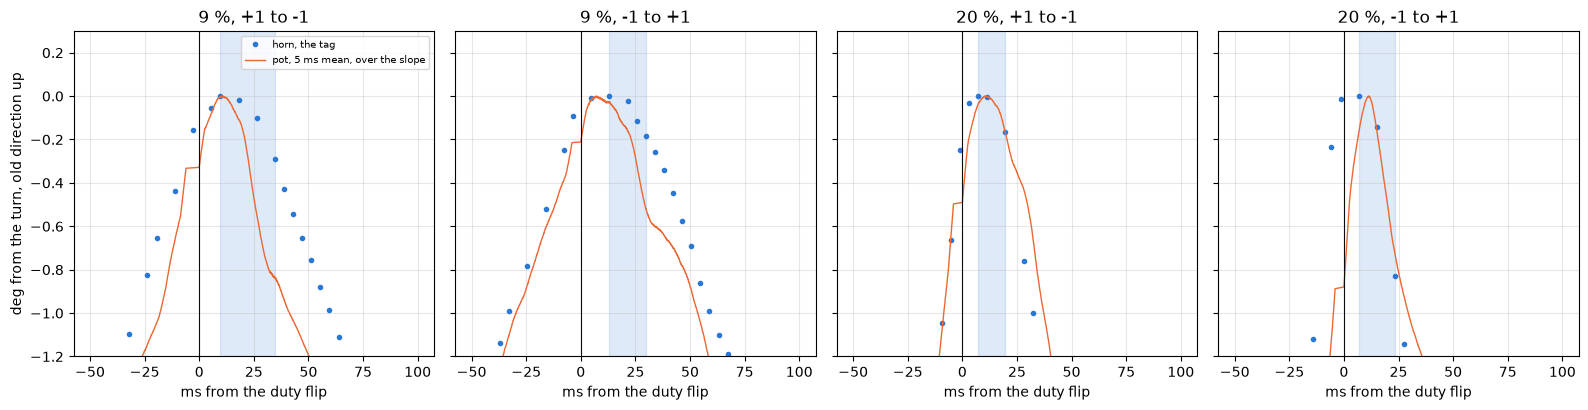

In [65]:
fig, axes = plt.subplots(1, 4, figsize=(16, 4.2), sharey=True)
for ax, (duty, ev, hd) in zip(axes, LASH_TRACES):
    d0 = ev["d0"]
    w = (hd["t"] > -0.05) & (hd["t"] < 0.1)
    turn = hd["ang"][np.argmin(np.abs(hd["t"] - hd["t_ext"]))]
    ax.plot(hd["t"][w] * 1e3, d0 * (hd["ang"][w] - turn), "o", ms=3,
            color=BLUE, label="horn, the tag")
    pw = (hd["pt"] > -0.05) & (hd["pt"] < 0.1)
    p_turn = hd["pp"][np.argmax(np.where((hd["pt"] > 0) & (hd["pt"] < 0.5),
                                         d0 * hd["pp"], -np.inf))]
    ax.plot(hd["pt"][pw] * 1e3, d0 * (hd["pp"][pw] - p_turn) / SCALE, "-",
            color=ORANGE, lw=1, label="pot, 5 ms mean, over the slope")
    ax.axvline(0, color=INK, lw=0.8)
    ax.axvspan(hd["t_ext"] * 1e3, hd["t_dep"] * 1e3, color=BLUE, alpha=0.15)
    ax.set_ylim(-1.2, 0.3)
    figures.label(ax, x="ms from the duty flip",
                  title=f"{duty} %, {d0:+d} to {-d0:+d}")
axes[0].set_ylabel("deg from the turn, old direction up")
axes[0].legend(fontsize=7)
figures.finish(fig)

The four reversals on one scale, the angle from the turn with the old direction up, the horn's dwell shaded. The motor's travel during the dwell is the lash. The pot turns before the horn in every event, 8 +/- 6 ms earlier, so the pot sits on the gear side of a small play of about 0.2 degrees to the horn, inside the train's lash.

The count gives 0.15 +/- 0.19 degrees (sd, 4 events) and the model 0.56 +/- 0.33, with the same count over the horn's dwell between them at 0.39 +/- 0.16. Speed times the dwell bounds it at 0.95 +/- 0.38. The lash at the output reads 0.15 to 0.6 degrees here, with low confidence on the value. The dwells are 12 ms for the pot and 16 to 18 ms for the horn by the two rules. A free horn shows the lash poorly, since nothing loads the train through the reversal, and the horn coasts on after the teeth let go, which hides part of the play. These readings are a lower bound on the play, and the hand rock below reads it from the other side.

## The lash by hand

A reversal loads the train only through the motor, and the horn coasts on after the teeth let go, which hides part of the play. A second sitting reads the play from the horn's side. The servo sits free at zero duty while a finger rocks the horn through its play, a light push each way until the train takes up and about a second still at each end. The tag and the pot both see the horn. The motor's taps see the motor, so a push that goes on past the play and back-drives the gears shows on them, and a push through the play does not.

The block is `lash-hand-10` in `pot-table/`, the optional `lash-hand` plan of `plan.py`, with the sitting's manifest `sittings/servo-camera-10.csv`. One chain of fifteen 3 s coasts, the longest burst the servo streams, gives 45.6 s of rows. The operator rocked mid travel first, then a spot 32 degrees below it and one 67 degrees above that, and went on rocking two spots after the stream ended, which only the tag records. The clip was shot in landscape, so its lens is sitting 9's turned a quarter turn. The angle of record is the horn tag against the reference tag, as in sitting 9.

In [66]:
HAND = DATA / "lash-hand-10"            # sitting 10's one block
HAND_EVENTS = pd.read_csv(PAIR_DIR / "sittings" / "servo-camera-10.csv")
show(HAND_EVENTS[HAND_EVENTS["event"] != "prompt"][["event", "detail"]],
     n=None)
hand_clip = pd.read_json(HAND / "manifest.json",
                         typ="series")["clips"]["lash-hand.mp4"]
hand_lens = pd.read_json(HAND / "camera.json", typ="series")
print(f"lash-hand.mp4: {hand_clip['frames']} frames at "
      f"{hand_clip['fps']:.1f} fps over {hand_clip['duration_s']:.1f} s, "
      f"{hand_clip['width']} x {hand_clip['height']}")
print(f"lens: {hand_lens['note']}, f {hand_lens['K'][0][0]:.0f} "
      f"{hand_lens['K'][1][1]:.0f} px against sitting 9's "
      f"{CAM.K[0, 0]:.0f} {CAM.K[1, 1]:.0f}")

,event,detail
0,start,"servo mg90-d, motor mg90-d, board dev-v006-2A-..."
2,plan,lash-hand
3,dataset,lash-hand: telemetry/mg90-d__dev-v006-2A-D/pot...
5,clip,lash-hand started
6,dps,on at 5.25 V
7,rail,"5.0 V: reads 4.998 V, DPS 5.250 V"
8,probe,telemetry/mg90-d__dev-v006-2A-D/pot-table/lash...
10,clip,lash-hand stopped
11,guards,414 to 3460 counts
12,probe,"center: pos 2007, ntc_raw 2047, vbus_raw 1237"


lash-hand.mp4: 27850 frames at 239.9 fps over 116.1 s, 1920 x 1080
lens: crawl-9's lens turned a quarter turn: this clip was shot landscape, f 1564 1563 px against sitting 9's 1563 1564


In [67]:
HAND_CLOCK = clock("lash-hand-10", "lash-hand")   # the midpoint fit
corners_h = pd.read_csv(HAND / "lash-hand.corners.csv")
angles_h = fd.angles(corners_h)


def own_angle(tag):
    """One tag's own edge direction in the image, deg CCW, unwrapped."""
    v = -fd.edge_direction(fd.corners(corners_h, tag))
    ok = np.isfinite(v)
    v[ok] = np.degrees(np.unwrap(np.radians(v[ok])))
    return v


HAND_TAG = pd.DataFrame({
    "host": HAND_CLOCK["h0"]
    + (angles_h["t"] - HAND_CLOCK["offset"]) / HAND_CLOCK["rate"],
    "ang": angles_h[ANGLE],             # horn against reference, of record
    "horn": own_angle("h"),             # the horn tag alone
    "ref": own_angle("r")})             # the reference tag alone
hand_seen = np.isfinite(HAND_TAG["ang"]).to_numpy()
HAND_TAG = HAND_TAG[hand_seen].reset_index(drop=True)
print(f"clock: {HAND_CLOCK['flashes']} flashes of 12 logged, midpoints "
      f"{HAND_CLOCK['rms_ms']:.2f} ms rms, onsets "
      f"{HAND_CLOCK['onset_rms_ms']:.2f} ms, rate "
      f"{(HAND_CLOCK['rate'] - 1) * 1e6:+.0f} ppm")
print(f"both tags in {100 * hand_seen.mean():.1f} % of "
      f"{len(hand_seen)} frames")

clock: 12 flashes of 12 logged, midpoints 0.71 ms rms, onsets 1.15 ms, rate +8 ppm
both tags in 99.0 % of 27850 frames


In [68]:
hdf, hmeta, hseg = load_sweep("lash-hand-10", 0)   # board checked
hdf["emf"] = hdf["vmotor_a"] - hdf["vmotor_b"]      # tap difference, counts
H0 = hdf["host"].min()                              # the stream's start
hdf["s"] = hdf["host"] - H0
HAND_TAG["s"] = HAND_TAG["host"] - H0
dark_ms = (hseg["t_start"].to_numpy()[1:]
           - hseg["t_end"].to_numpy()[:-1]) * 1e3
STREAM_S = hdf["s"].max()
in_stream = HAND_TAG["s"].between(0, STREAM_S)
print(f"{len(hseg)} segments, {len(hdf)} rows over {STREAM_S:.1f} s, "
      f"{hmeta['rows_dropped']} rows dropped, {dark_ms.min():.0f} to "
      f"{dark_ms.max():.0f} ms dark between segments")
print(f"duty {hdf['duty_counts'].abs().max()} counts throughout, pos "
      f"{hdf['pos'].min()} to {hdf['pos'].max()}; {in_stream.sum()} frames "
      f"inside the stream and the clip on to {HAND_TAG['s'].max():.1f} s")

16 segments, 910000 rows over 45.6 s, 0 rows dropped, 0 to 6 ms dark between segments
duty 0 counts throughout, pos 1435 to 2754; 10804 frames inside the stream and the clip on to 75.3 s


The clapper's twelve flashes all match, and the clock fits to 0.71 ms rms at the midpoints and 1.15 ms at the onsets, inside sitting 9's range. Both tags are found in 99.0 % of the frames. The stream has no dropped rows and is dark for at most 6 ms between bursts.

### The held ends and the rocks

The stream is read at 1 kHz, every 20th row, with the tag interpolated to each row's host time. Each spot is the stretch between the back-drives that carried the horn from one spot to the next, 0.5 to 17.3 s, 18.6 to 31.5 s and 34.0 to 45.6 s from the stream's start. Inside a spot, the tag's midpoint between its 5th and 95th percentiles splits the up ends from the down ends. A stretch on one side longer than 0.45 s is a held end, and it is read over its stillest 0.4 s, the window where the pot's 95 % range over 2 counts plus the tag's over 0.1 degrees is least. A rock is two consecutive held ends on opposite sides. Its change is signed by the side it ends on, so a rock reads positive either way. The pot is taken into tag degrees through the inverse of the table of record.

In [69]:
HAND_SPOTS = {"mid": (0.5, 17.3), "low": (18.6, 31.5),  # s from the
              "high": (34.0, 45.6)}                      # stream's start
BACK_DRIVES = ((17.3, 18.6), (31.5, 34.0))   # s, the moves between spots
HELD_MIN_S = 0.45       # s, a held end lasts at least this long
STILL_S = 0.4           # s, the window an end is read over
STILL_STEP = 10         # samples between the windows tried
STILL_NORM = {"pos": 2.0, "ang": 0.1}   # counts and deg, the still scale


def stillest(d, cols):
    """The rows of the window in d where the sum of each column's 95 %
    range over its scale is least."""
    t, best = d["s"].to_numpy(), None
    for i in range(0, len(d), STILL_STEP):
        j = np.searchsorted(t, t[i] + STILL_S)
        if j > len(d) - 1:
            break
        if t[j - 1] - t[i] < 0.9 * STILL_S:
            continue                    # a window across a dark gap
        score = sum(np.ptp(np.percentile(d[c].to_numpy()[i:j], [2.5, 97.5]))
                    / STILL_NORM[c] for c in cols)
        if best is None or score < best[0]:
            best = (score, i, j)
    return None if best is None else d.iloc[best[1]:best[2]]

In [70]:
def held_ends(d, cols):
    """One spot's held ends: the side, the stretch on that side and the
    readings over its stillest window."""
    mid = np.mean(np.percentile(d["ang"], [5, 95]))
    up = (d["ang"] > mid).to_numpy()
    cut = np.r_[0, np.flatnonzero(np.diff(up.astype(int))) + 1, len(d)]
    rows = []
    for a, b in zip(cut[:-1], cut[1:]):
        g = d.iloc[a:b]
        if g["s"].iloc[-1] - g["s"].iloc[0] < HELD_MIN_S:
            continue
        w = stillest(g, cols)
        if w is None:
            continue
        row = {"side": 1 if up[a] else -1, "t_a": g["s"].iloc[0],
               "t_b": g["s"].iloc[-1], "w_a": w["s"].iloc[0],
               **{c: w[c].mean() for c in ("ang", "horn", "ref")}}
        if "pos" in cols:
            row.update({"pos": w["pos"].median(),
                        "pos_range": np.ptp(np.percentile(w["pos"],
                                                          [2.5, 97.5])),
                        "pot_table_deg": np.median(pot_deg(w["pos"]))})
        rows.append(row)
    return pd.DataFrame(rows)


def rocks(ends):
    """Consecutive held ends on opposite sides, each change signed by the
    side the rock ends on, so a rock reads positive."""
    out, cols = [], [c for c in ("ang", "horn", "ref", "pos",
                                 "pot_table_deg") if c in ends]
    for i in range(len(ends) - 1):
        x, y = ends.iloc[i], ends.iloc[i + 1]
        if x["side"] == y["side"]:
            continue                    # two ends on one side, no rock
        out.append({"t_from": x["w_a"] + STILL_S, "t_to": y["w_a"] + STILL_S,
                    "side": int(y["side"]),
                    **{c: y["side"] * (y[c] - x[c]) for c in cols}})
    return pd.DataFrame(out)

In [71]:
tag_s = HAND_TAG.set_index("s")
DEC = hdf.iloc[::20].copy()             # the stream at 1 kHz
for c in ("ang", "horn", "ref"):
    DEC[c] = np.interp(DEC["s"], tag_s.index, tag_s[c])
end_parts, rock_parts = [], []
for spot, (t0, t1) in HAND_SPOTS.items():
    e = held_ends(DEC[DEC["s"].between(t0, t1)], ("pos", "ang"))
    end_parts.append(e.assign(spot=spot))
    rock_parts.append(rocks(e).assign(spot=spot))
ENDS = pd.concat(end_parts, ignore_index=True)
ROCKS = pd.concat(rock_parts, ignore_index=True)
for spot, e in ENDS.groupby("spot", sort=False):
    print(f"{spot}: tag near {e['ang'].median():.0f} deg, pos "
          f"{e['pos'].min():.0f} to {e['pos'].max():.0f}, {len(e)} held "
          f"ends, {(ROCKS['spot'] == spot).sum()} rocks; the pot's 95 % "
          f"range in a window {e['pos_range'].median():.0f} counts median, "
          f"{e['pos_range'].max():.0f} max")
show(ENDS[["spot", "side", "t_a", "t_b", "w_a", "pos", "pos_range", "ang",
           "pot_table_deg", "ref"]], n=4)

mid: tag near -87 deg, pos 2047 to 2093, 17 held ends, 16 rocks; the pot's 95 % range in a window 3 counts median, 15 max
low: tag near -119 deg, pos 1446 to 1490, 15 held ends, 13 rocks; the pot's 95 % range in a window 3 counts median, 5 max
high: tag near -52 deg, pos 2681 to 2747, 10 held ends, 9 rocks; the pot's 95 % range in a window 4 counts median, 4 max


,spot,side,t_a,t_b,w_a,pos,pos_range,ang,pot_table_deg,ref
0,mid,-1,1.315,2.018,1.565,2047.000,2.000,-87.831,-88.394,-89.994
1,mid,1,2.019,2.817,2.199,2081.000,4.000,-86.738,-86.115,-89.882
2,mid,-1,2.818,3.699,3.088,2047.000,0.000,-88.024,-88.394,-89.932
3,mid,1,3.700,4.577,3.860,2083.000,3.000,-86.660,-85.985,-89.871


Each spot gives 10 to 17 held ends and 9 to 16 rocks. The first two held ends at the low spot sit on the same side, so they make no rock. The pot's 95 % range over a window is 3 to 4 counts at the median. Two down ends at mid travel span 13 and 15 counts, since there the pot jumps between code 2047 and the codes above the converter's missing run, the subject of the last part of this section.

### Whether the motor turned

With the bridge open, the tap difference $v_A - v_B$ is the motor's back EMF, so a push that back-drives the train shows on it, and its integral over a rock is the motor's travel. The scale comes from the two back-drives between the spots, where the hand carried the horn 33 and 68 degrees with the motor turning all the way. It is a line of the tap difference on the tag's speed, the gradient of the tag smoothed over 7 frames, over every back-drive row faster than 15 degrees per second. The zero is the mean tap difference wherever the tag moves slower than 0.5 degrees per second. A rock runs from the end of one held window to the end of the next. It turned the motor when the tap difference stood 8 counts or more off its zero, and its swing is then read less the motor's travel.

In [72]:
SPEED_FRAMES = 7        # frames, the tag's speed smoothing
EMF_STILL_DEG_S = 0.5   # deg/s, the tag still: the taps' zero
FAST_DEG_S = 15         # deg/s, the back-drive rows the scale is fit on
TURNED_COUNTS = 8       # counts off zero, a rock that turned the motor
tag_smooth = tag_s["ang"].rolling(SPEED_FRAMES, center=True).mean()
tag_speed = np.gradient(tag_smooth.bfill().ffill().to_numpy(),
                        tag_s.index.to_numpy())
hdf["tag_speed"] = np.interp(hdf["s"], tag_s.index, tag_speed)
EMF_ZERO = hdf.loc[hdf["tag_speed"].abs() < EMF_STILL_DEG_S, "emf"].mean()
on_drive = np.zeros(len(hdf), bool)
for t0, t1 in BACK_DRIVES:
    on_drive |= hdf["s"].between(t0, t1).to_numpy()
fast_rows = (hdf["tag_speed"].abs() > FAST_DEG_S).to_numpy()
EMF_LINE = results.fit_line(hdf["tag_speed"][on_drive & fast_rows],
                            hdf["emf"][on_drive & fast_rows] - EMF_ZERO)
EMF_K = EMF_LINE["slope"]               # counts per deg/s of output
every_fast = results.fit_line(hdf["tag_speed"][fast_rows],
                              hdf["emf"][fast_rows] - EMF_ZERO)
print(f"zero {EMF_ZERO:.2f} counts; scale {EMF_K:.3f} +/- "
      f"{EMF_LINE['slope_se']:.3f} counts per deg/s over "
      f"{EMF_LINE['n']} back-drive rows, intercept "
      f"{EMF_LINE['intercept']:+.2f}, rms {EMF_LINE['rms']:.1f}")
for t0, t1 in BACK_DRIVES:
    g = hdf[hdf["s"].between(t0, t1)]
    turn = np.interp(t1, tag_s.index, tag_s["ang"]) - np.interp(
        t0, tag_s.index, tag_s["ang"])
    print(f"  back-drive {t0}-{t1} s: tag {turn:+.2f} deg, integral over "
          f"the turn {(g['emf'] - EMF_ZERO).sum() / FS / turn:.3f} counts "
          f"per deg/s")
print(f"the same line over every row faster than {FAST_DEG_S} deg/s, the "
      f"rocks included: {every_fast['slope']:.3f} counts per deg/s")

zero -1.23 counts; scale 1.580 +/- 0.001 counts per deg/s over 43362 back-drive rows, intercept -0.00, rms 9.8
  back-drive 17.3-18.6 s: tag -33.49 deg, integral over the turn 1.520 counts per deg/s
  back-drive 31.5-34.0 s: tag +67.95 deg, integral over the turn 1.536 counts per deg/s
the same line over every row faster than 15 deg/s, the rocks included: 1.373 counts per deg/s


In [73]:
def motor_travel(t_from, t_to):
    """(output deg the motor turned, peak counts off zero, its time and
    its sign) between two stream times, from the tap difference."""
    g = hdf[hdf["s"].between(t_from, t_to)]
    e = g["emf"] - EMF_ZERO
    i = e.abs().to_numpy().argmax()
    return (e.sum() / FS / EMF_K, e.abs().max(), g["s"].iloc[i],
            np.sign(e.iloc[i]))


ROCKS[["motor_deg", "emf_peak", "t_peak", "peak_sign"]] = np.array(
    [motor_travel(a, b) for a, b in zip(ROCKS["t_from"], ROCKS["t_to"])])
ROCKS["turned"] = ROCKS["emf_peak"] >= TURNED_COUNTS
# a rock that turned the motor less the motor's own turn, signed as a rock
ROCKS["swing"] = np.where(ROCKS["turned"], ROCKS["ang"]
                          - ROCKS["side"] * ROCKS["motor_deg"], ROCKS["ang"])
for spot, g in ROCKS.groupby("spot", sort=False):
    q_ = g[~g["turned"]]
    t_ = g[g["turned"]]
    print(f"{spot}: motor turned in {len(t_)} of {len(g)} rocks"
          + (f", {t_['motor_deg'].abs().min():.2f} to "
             f"{t_['motor_deg'].abs().max():.2f} deg" if len(t_) else "")
          + "; the still rocks' motor travel "
          f"{q_['motor_deg'].abs().mean():.3f} deg mean, "
          f"{q_['motor_deg'].abs().max():.3f} max")

mid: motor turned in 11 of 16 rocks, 0.01 to 0.65 deg; the still rocks' motor travel 0.017 deg mean, 0.034 max
low: motor turned in 0 of 13 rocks; the still rocks' motor travel 0.009 deg mean, 0.023 max
high: motor turned in 0 of 9 rocks; the still rocks' motor travel 0.038 deg mean, 0.086 max


The scale is 1.58 counts per degree per second of output over the back-drive rows, with no intercept, and the integral over each back-drive's whole turn gives 1.52 and 1.54. The same line over every row of the stream faster than 15 degrees per second reads 1.37. That line takes in the rocks themselves, where the tag moves fast and the motor stays still, which pulls it down. On it every motor travel below would read 15 % larger.

The motor turned in 11 of the 16 rocks at mid travel, 0.01 to 0.65 degrees of output, and in none at the other two spots, where the integral over a rock stays under 0.09 degrees. At mid travel the push most likely overcame the motor's cogging, and those rocks are read less the motor's turn.

### After the stream

The clip ran on for 30 s after the stream, with two more spots rocked on the tag alone. A spot there is a stretch of 2 s or more between moves, a move being 5 degrees of tag over a second of frames, whose tag spans under 5 degrees from its 5th to its 95th percentile. Its held ends and rocks are read as above on the tag alone.

In [74]:
MOVE_DEG = 5.0          # deg over a second of frames, a move between spots
MOVE_FRAMES = 240       # frames, about one second at 240 fps
SPOT_MIN_S = 2.0        # s, a rocked spot lasts at least this long
SPOT_MAX_DEG = 5.0      # deg, a rocked spot's 5 to 95 % range at most
tail_tag = HAND_TAG[HAND_TAG["s"] > STREAM_S + 0.5].copy()
tail_moving = tail_tag["ang"].diff().abs().rolling(
    MOVE_FRAMES).sum() > MOVE_DEG
tail_parts = []
for _, g in tail_tag.groupby(tail_moving.cumsum()):
    if (g["s"].iloc[-1] - g["s"].iloc[0] < SPOT_MIN_S
            or np.ptp(np.percentile(g["ang"], [5, 95])) > SPOT_MAX_DEG):
        continue
    r = rocks(held_ends(g, ("ang",)))
    tail_parts.append(r.assign(spot=f"after, {g['ang'].median():.0f} deg"))
TAIL_ROCKS = pd.concat(tail_parts, ignore_index=True)
TAIL_ROCKS["swing"] = TAIL_ROCKS["ang"]   # no taps after the stream
for spot, g in TAIL_ROCKS.groupby("spot", sort=False):
    print(f"{spot}: {len(g)} rocks from {g['t_from'].min():.1f} to "
          f"{g['t_to'].max():.1f} s, swing {g['swing'].mean():.2f} +/- "
          f"{g['swing'].std():.2f} deg, the reference "
          f"{g['ref'].abs().max():.3f} deg at most")

after, -53 deg: 14 rocks from 48.8 to 60.8 s, swing 1.30 +/- 0.10 deg, the reference 0.008 deg at most
after, -90 deg: 7 rocks from 64.9 to 71.8 s, swing 1.22 +/- 0.09 deg, the reference 0.005 deg at most


### The swing

Per spot, the tag's swing, less the motor's turn where it turned, with its sd, the tag's raw swing, the rocks that turned the motor, the pot's swing in counts and through the table, the ratio of the pot's swing through the table to the tag's, the pot's counts per tag degree over a rock, the reference tag's own turn per rock, and how far the horn tag alone differs from the horn against the reference. The stream's high spot is held apart as the firm push, for the reason given below the figures.

In [75]:
FIRM_SPOT = "high"      # the stream's high spot, pushed harder (see text)
spot_parts = []
for spot, g in pd.concat([ROCKS, TAIL_ROCKS]).groupby("spot", sort=False):
    tap = "turned" in g and g["turned"].notna().all()
    spot_parts.append({
        "spot": spot, "rocks": len(g), "swing_deg": g["swing"].mean(),
        "swing_sd": g["swing"].std(), "raw_deg": g["ang"].mean(),
        "turned": int(g["turned"].sum()) if tap else np.nan,
        "pot_counts": g.get("pos", pd.Series(np.nan)).mean(),
        "pot_table_deg": g.get("pot_table_deg", pd.Series(np.nan)).mean(),
        "ratio": (g.get("pot_table_deg", np.nan) / g["ang"]).mean(),
        "climb": (g.get("pos", np.nan) / g["ang"]).mean(),
        "ref_deg": g["ref"].mean(),
        "horn_alone_less": (g["horn"] - g["ang"]).abs().mean()})
SPOT_TABLE = pd.DataFrame(spot_parts)
show(SPOT_TABLE, n=None)
light_spots = SPOT_TABLE[SPOT_TABLE["spot"] != FIRM_SPOT]
LASH_HAND = (light_spots["swing_deg"].mean(),
             light_spots["swing_deg"].std())
FIRM = ROCKS[ROCKS["spot"] == FIRM_SPOT]["swing"]
PLAY = (LASH["count_horn_deg"].mean(), light_spots["swing_deg"].min())
print(f"light: {LASH_HAND[0]:.2f} +/- {LASH_HAND[1]:.2f} deg (sd of the "
      f"{len(light_spots)} spot means, "
      f"{int(light_spots['rocks'].sum())} rocks); firm "
      f"{FIRM.mean():.2f} +/- {FIRM.std():.2f} deg ({len(FIRM)} rocks); "
      f"the play between {PLAY[0]:.2f} and {PLAY[1]:.2f} deg")

,spot,rocks,swing_deg,swing_sd,raw_deg,turned,pot_counts,pot_table_deg,ratio,climb,ref_deg,horn_alone_less
0,mid,16,1.300,0.089,1.450,11.000,37.375,2.471,1.714,25.912,0.035,0.035
1,low,13,1.125,0.035,1.125,0.000,37.692,2.139,1.899,33.470,-0.042,0.049
2,high,9,1.655,0.120,1.655,0.000,60.556,2.751,1.664,36.644,0.006,0.006
3,"after, -53 deg",14,1.297,0.100,1.297,NaN,NaN,NaN,NaN,NaN,0.001,0.003
4,"after, -90 deg",7,1.224,0.093,1.224,NaN,NaN,NaN,NaN,NaN,-0.002,0.002


light: 1.24 +/- 0.08 deg (sd of the 4 spot means, 50 rocks); firm 1.65 +/- 0.12 deg (9 rocks); the play between 0.39 and 1.12 deg


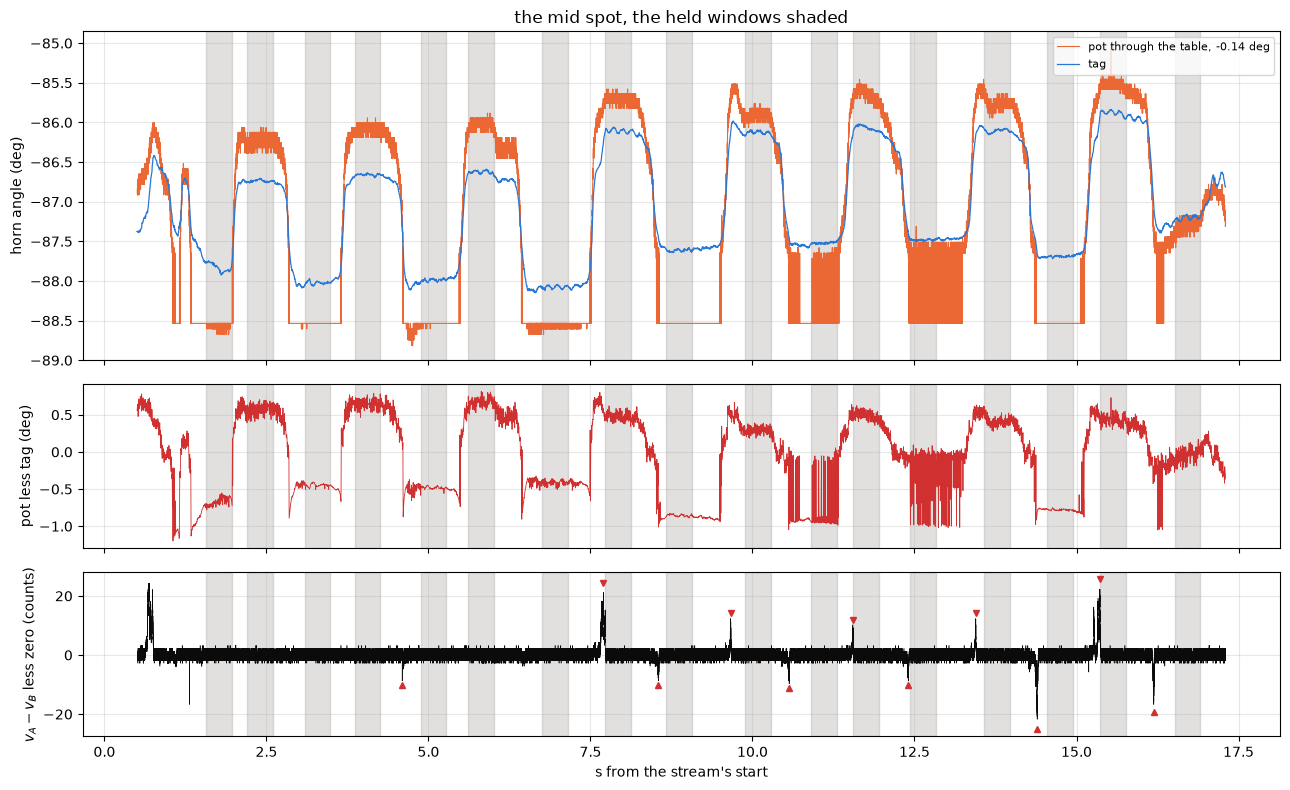

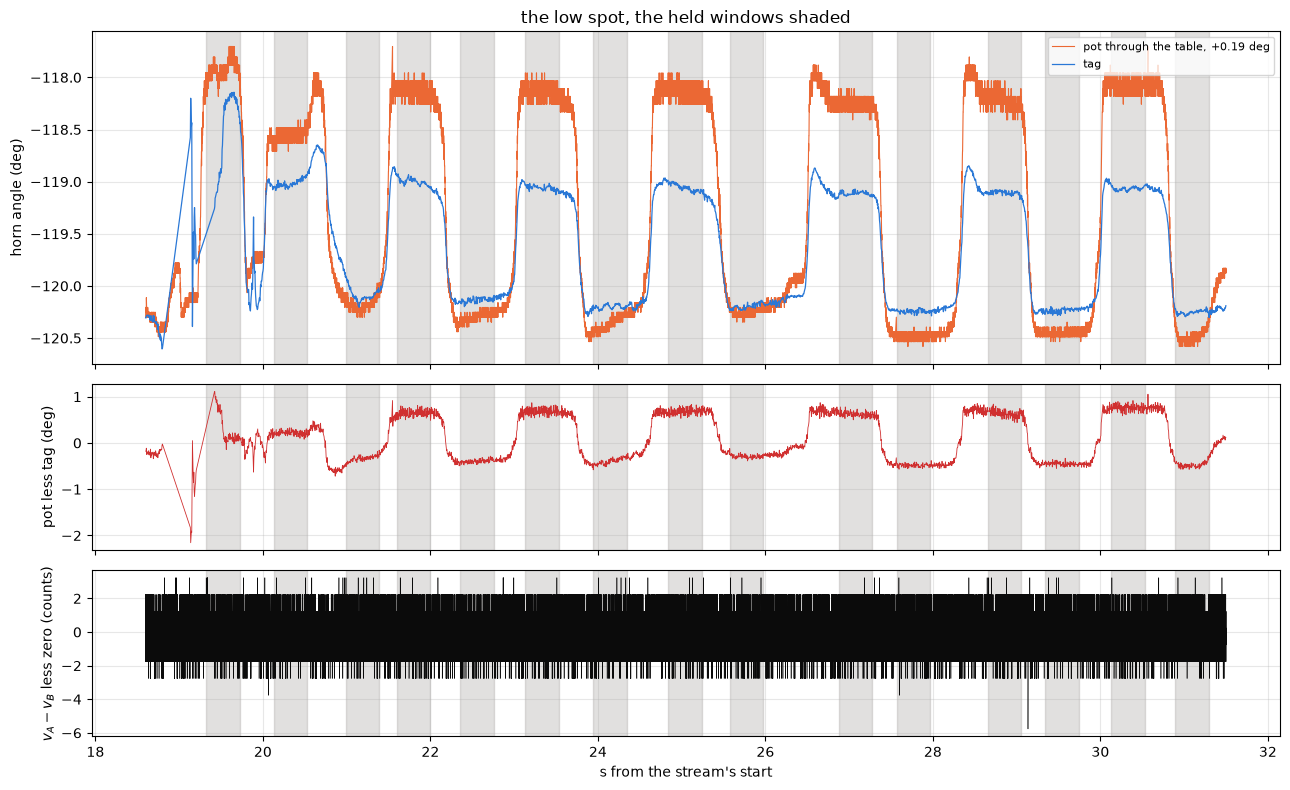

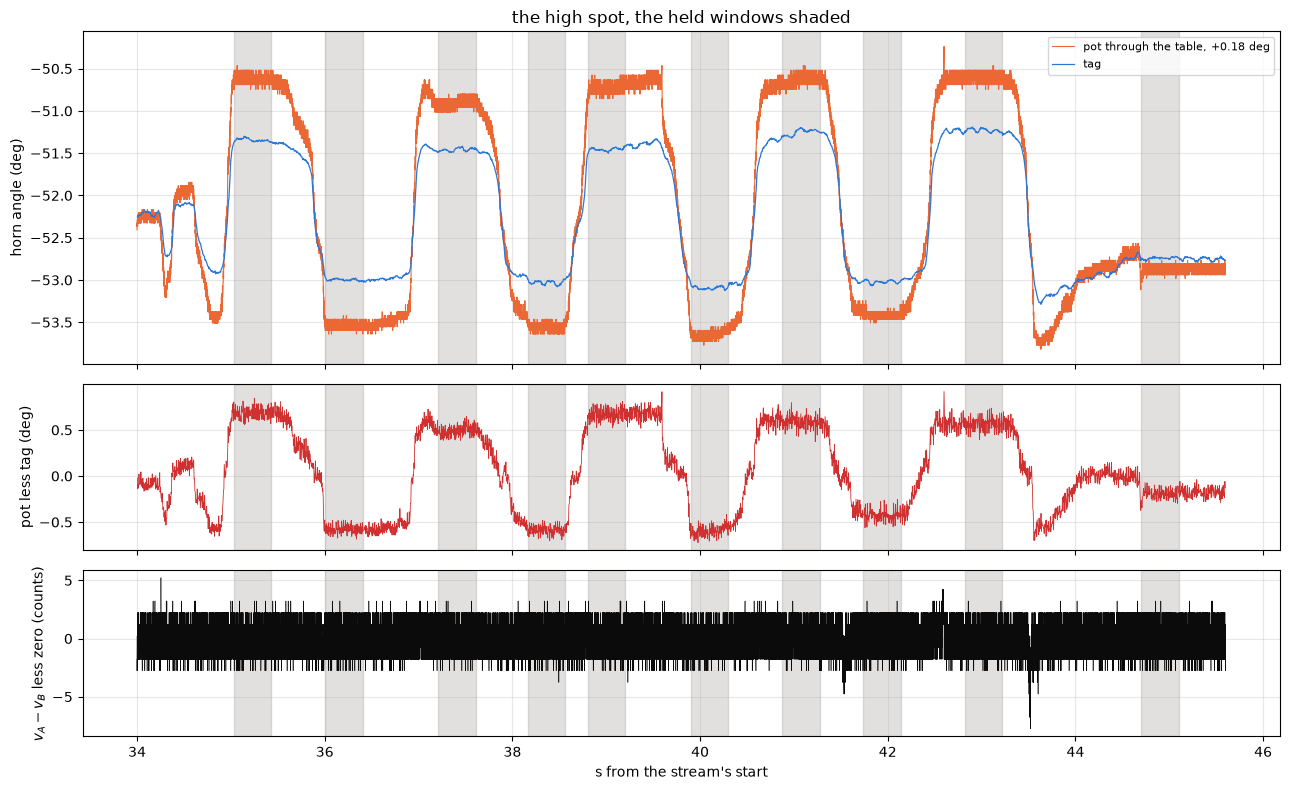

In [76]:
def spot_figure(spot):
    """Tag and pot, their difference and the taps over one spot."""
    t0, t1 = HAND_SPOTS[spot]
    d = DEC[DEC["s"].between(t0, t1)]
    r = hdf[hdf["s"].between(t0, t1)]
    f = tag_s[(tag_s.index >= t0) & (tag_s.index <= t1)]
    pot = pot_deg(d["pos"])
    shift = np.median(f["ang"]) - np.nanmedian(pot)
    resid = pot_deg(np.interp(f.index, hdf["s"], hdf["pos"])) - f["ang"]
    fig, ax = plt.subplots(3, 1, figsize=(13, 8), sharex=True,
                           gridspec_kw={"height_ratios": [2, 1, 1]})
    ax[0].plot(d["s"], pot + shift, "-", color=ORANGE, lw=0.8,
               label=f"pot through the table, {shift:+.2f} deg")
    ax[0].plot(f.index, f["ang"], "-", color=BLUE, lw=0.9, label="tag")
    ax[1].plot(f.index, resid - np.nanmedian(resid), "-", color=RED, lw=0.6)
    ax[2].plot(r["s"], r["emf"] - EMF_ZERO, "-", color=INK, lw=0.4)
    for _, e in ENDS[ENDS["spot"] == spot].iterrows():
        for a in ax:
            a.axvspan(e["w_a"], e["w_a"] + STILL_S, color=MUTED, alpha=0.25)
    for _, k in ROCKS[(ROCKS["spot"] == spot) & ROCKS["turned"]].iterrows():
        ax[2].plot(k["t_peak"], k["peak_sign"] * k["emf_peak"] * 1.15,
                   "v" if k["peak_sign"] > 0 else "^", color=RED, ms=5)
    ax[0].legend(fontsize=8, loc="upper right")
    figures.label(ax[0], y="horn angle (deg)",
                  title=f"the {spot} spot, the held windows shaded")
    figures.label(ax[1], y="pot less tag (deg)")
    figures.label(ax[2], x="s from the stream's start",
                  y="$v_A - v_B$ less zero (counts)")
    figures.finish(fig)


for spot in HAND_SPOTS:
    spot_figure(spot)

One figure per spot. Top, the tag and the pot through the table, the pot shifted by its median difference from the tag over the spot, the held windows shaded. Middle, the pot less the tag, its median out. Bottom, the tap difference less its zero, with a red triangle beyond the peak of each rock that turned the motor.

At every spot the pot swings further than the tag. At the low and high spots the taps stay within 8 counts of zero through every rock, a motor travel under 0.09 degrees, so the train did not turn and the horn moved through the play alone. At mid travel the taps spike on most pushes. The pot's down ends there sit on the flat floor of code 2047, and in two of them the pot jumps between 2047 and the codes above the missing run. The pot less the tag steps by about a degree at every rock, up at the up ends and down at the down ends, and creeps back toward zero inside each hold.

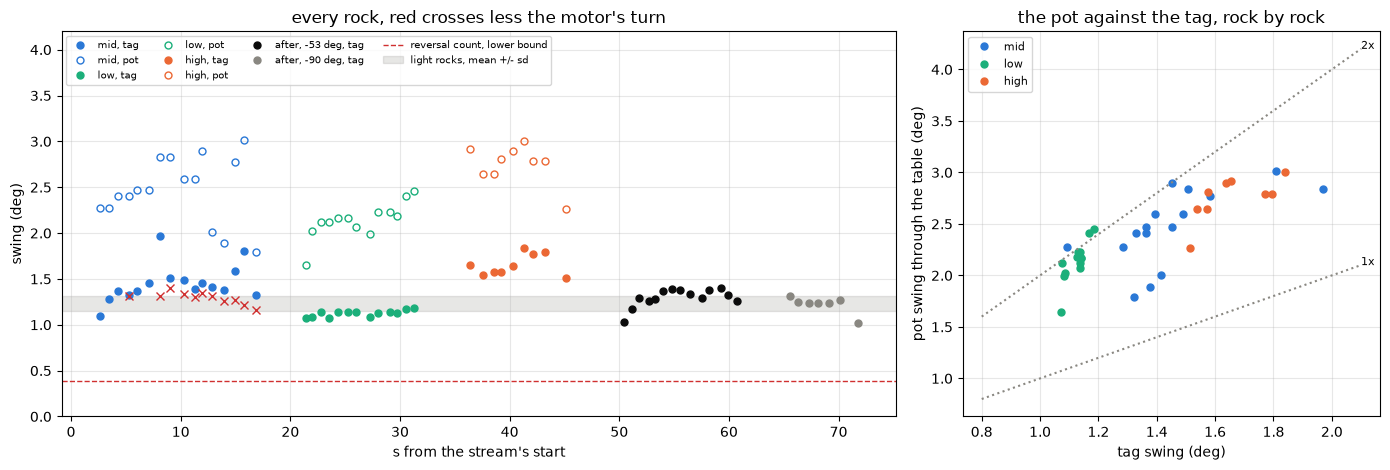

In [77]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4.8),
                       gridspec_kw={"width_ratios": [2, 1]})
hand_shade = dict(zip(list(HAND_SPOTS) + sorted(TAIL_ROCKS["spot"].unique()),
                 (BLUE, GREEN, ORANGE, INK, MUTED)))
for spot, g in pd.concat([ROCKS, TAIL_ROCKS]).groupby("spot", sort=False):
    c = hand_shade[spot]
    ax[0].plot(g["t_to"], g["ang"], "o", color=c, ms=5, label=f"{spot}, tag")
    if "pot_table_deg" in g and g["pot_table_deg"].notna().any():
        ax[0].plot(g["t_to"], g["pot_table_deg"], "o", mfc="none", color=c,
                   ms=5, label=f"{spot}, pot")
        ax[1].plot(g["ang"], g["pot_table_deg"], "o", color=c, ms=5,
                   label=spot)
    tu = g[g["turned"].eq(True)]       # the rocks less the motor's turn
    ax[0].plot(tu["t_to"], tu["swing"], "x", color=RED, ms=6)
ax[0].axhline(PLAY[0], color=RED, ls="--", lw=1,
              label="reversal count, lower bound")
ax[0].axhspan(LASH_HAND[0] - LASH_HAND[1], LASH_HAND[0] + LASH_HAND[1],
              color=MUTED, alpha=0.2, label="light rocks, mean +/- sd")
ax[0].set_ylim(0, 4.2)                  # room for the legend
ax[0].legend(fontsize=7, ncol=4, loc="upper left")
figures.label(ax[0], x="s from the stream's start", y="swing (deg)",
              title="every rock, red crosses less the motor's turn")
ref_x = np.linspace(0.8, 2.1, 2)
for k in (1, 2):
    ax[1].plot(ref_x, k * ref_x, ls=":", color=MUTED)
    ax[1].annotate(f"{k}x", (ref_x[-1], k * ref_x[-1]), fontsize=8)
ax[1].legend(fontsize=8)
figures.label(ax[1], x="tag swing (deg)", y="pot swing through the table "
              "(deg)", title="the pot against the tag, rock by rock")
figures.finish(fig)

Left, every rock's swing on the tag, filled, and the pot's through the table, open, against the time the rock ended, the mid rocks less the motor's turn as red crosses, the light rocks' mean +/- sd shaded and the reversals' count as the dashed line. Right, the pot's swing through the table against the tag's, rock by rock, with the lines of one and two times.

At a light push the tag swings 1.12 +/- 0.04 degrees at the low spot, 1.30 +/- 0.09 at mid travel less the motor's turn, and 1.30 +/- 0.10 and 1.22 +/- 0.09 at the two spots after the stream. The four spot means give 1.24 +/- 0.08 degrees over 50 rocks, the hand's lash of record. During the stream the high spot swung 1.65 +/- 0.12 degrees over 9 rocks, while the same place, -53 degrees, swung 1.30 after the stream. The larger swing goes with a firmer push, not with the place, and it is carried as the firm reading. The reference tag turns 0.04 degrees or less per rock on average, and the horn tag alone agrees with the horn against the reference to 0.05 degrees, so the reference does not move with the push.

The swing is the play plus the train's wind-up under the finger's torque, which is not measured, so it is an upper bound on the pure play, and the firm reading shows it growing with the push. The reversals' count over the horn's dwell, 0.39 degrees, is a lower bound. The pure free play lies between 0.39 and 1.12 degrees, the lightest spot. Graded weights at a known radius, the swing against torque followed to zero torque, separate the play from the wind-up.

### The pot's force term

Through the table the pot swings 1.66 to 1.90 times the tag at the three spots of the stream, 37, 38 and 61 counts a rock against 1.45, 1.12 and 1.65 degrees of tag. Each held end is read as the pot through the table less the tag, with each spot's mean over its ends taken out, and split by side.

In [78]:
ENDS["resid"] = ENDS["pot_table_deg"] - ENDS["ang"]
ENDS["excess"] = ENDS["resid"] - ENDS.groupby("spot")["resid"].transform(
    "mean")                             # each spot's level out
side_parts = []
for spot, g in ENDS.groupby("spot", sort=False):
    up, down = g[g["side"] > 0]["excess"], g[g["side"] < 0]["excess"]
    side_parts.append({"spot": spot, "up_deg": up.mean(), "up_sd": up.std(),
                      "down_deg": down.mean(), "down_sd": down.std(),
                      "up_less_down_deg": up.mean() - down.mean(),
                      "ends": len(g)})
EXCESS = pd.DataFrame(side_parts)
show(EXCESS, n=None)

,spot,up_deg,up_sd,down_deg,down_sd,up_less_down_deg,ends
0,mid,0.529,0.120,-0.470,0.318,0.999,17
1,low,0.458,0.166,-0.524,0.067,0.982,15
2,high,0.536,0.071,-0.536,0.170,1.073,10


In [79]:
RELAX_SKIP_S = 0.15     # s, the arrival at an end out
RELAX_END_S = 0.02      # s, the departure out
RELAX_MIN_FRAMES = 60   # frames a hold needs


def relax(e):
    """Changes over one hold, by a line through it: the pot less the tag,
    the tag, the pot through the table, all deg, and the hold's length."""
    f = tag_s[(tag_s.index >= e["t_a"] + RELAX_SKIP_S)
              & (tag_s.index <= e["t_b"] - RELAX_END_S)]
    if len(f) < RELAX_MIN_FRAMES:
        return [np.nan] * 4
    t = f.index.to_numpy() - f.index[0]
    pot = pot_deg(np.interp(f.index, hdf["s"], hdf["pos"]))
    change = [np.polyfit(t, y, 1)[0] * t[-1]
              for y in (pot - f["ang"], f["ang"], pot)]
    return change + [t[-1]]


ENDS[["d_resid", "d_tag", "d_pot", "hold_s"]] = np.array(
    [relax(e) for _, e in ENDS.iterrows()])
relaxed = (np.sign(ENDS["d_resid"]) == -ENDS["side"]).sum()
show(ENDS.groupby(["spot", "side"], sort=False)[
    ["d_resid", "d_tag", "d_pot", "hold_s"]].mean().reset_index(), n=None)
print(f"the pot less the tag moved back against the push in {relaxed} of "
      f"{ENDS['d_resid'].notna().sum()} holds, {ENDS['hold_s'].min():.2f} "
      f"to {ENDS['hold_s'].max():.2f} s long")

,spot,side,d_resid,d_tag,d_pot,hold_s
0,mid,-1,0.278,0.111,0.388,0.766
1,mid,1,-0.362,-0.244,-0.606,0.725
2,low,1,-0.242,-0.040,-0.282,0.583
3,low,-1,0.312,0.107,0.419,0.669
4,high,1,-0.357,-0.178,-0.535,0.784
5,high,-1,0.331,0.277,0.609,0.992


the pot less the tag moved back against the push in 42 of 42 holds, 0.32 to 1.93 s long


At every held end the pot reads past the tag in the direction of the push, +0.46 to +0.54 degrees at the up ends and -0.47 to -0.54 at the down ends, so up less down is 1.00, 0.98 and 1.07 degrees at mid, low and high. The excess is the same size at three places spread over 67 degrees of travel, and in both directions.

Inside a hold it relaxes. Each hold is read from 0.15 s after it arrives to 0.02 s before it leaves, by a line through each reading, the change over the hold being the line's slope times the hold's length. In all 42 holds the pot less the tag moves back against the push, by 0.24 to 0.36 degrees on the side means over holds of 0.6 to 1.0 s on average. The tag moves back too, 0.04 to 0.28 degrees, most likely the finger easing, and the pot through the table by 0.28 to 0.61, about the tag's change and the relaxation together.

The same codes under motion come from sitting 9. Its passes, crawls, reversals and steps cross the low and high spots' codes, and every crossing that spans 0.8 degrees of tag or more at 20 degrees per second or faster gives a slope of pos on the tag.

In [80]:
MOTION_CODES = {"low": (1440, 1500), "high": (2670, 2760)}   # counts
CROSS_GAP_S = 0.05      # s, a gap that ends one crossing
CROSS_MIN_ROWS = 20     # rows a crossing needs
CROSS_MIN_DEG = 0.8     # deg of tag a crossing spans at least
CROSS_MIN_DEG_S = 20    # deg/s, the crossings that count as motion
motion_parts = []
for (name, k), (df, _, _) in SWEEPS.items():
    a = TAGS[name][TAGS[name]["both"]]
    h, ang = a["host"].to_numpy(), a[ANGLE].to_numpy()
    cam = np.interp(df["host"], h, ang, left=np.nan, right=np.nan)
    sm = pd.Series(ang).rolling(5, center=True).mean().bfill().ffill()
    v = np.interp(df["host"], h, np.gradient(sm.to_numpy(), h))
    for spot, (lo, hi) in MOTION_CODES.items():
        m = df["pos"].between(lo, hi).to_numpy() & np.isfinite(cam)
        t, p, c, w = (df["host"].to_numpy()[m], df["pos"].to_numpy()[m],
                      cam[m], v[m])
        if not len(t):
            continue
        n = np.r_[0, np.cumsum(np.diff(t) > CROSS_GAP_S)]
        for i in np.unique(n):
            s = n == i
            if s.sum() < CROSS_MIN_ROWS or np.ptp(c[s]) < CROSS_MIN_DEG:
                continue
            motion_parts.append({"spot": spot, "clip": name, "k": k,
                           "slope": np.polyfit(c[s], p[s], 1)[0],
                           "speed": np.median(np.abs(w[s])),
                           "dir": np.sign(np.median(w[s]))})
MOTION = pd.DataFrame(motion_parts)
MOTION = MOTION[MOTION["speed"] >= CROSS_MIN_DEG_S]
show(MOTION.groupby(["spot", "dir"]).agg(
    crossings=("slope", "size"), slope=("slope", "mean"),
    sd=("slope", "std"), speed_lo=("speed", "min"),
    speed_hi=("speed", "max")).reset_index(), n=None)

,spot,dir,crossings,slope,sd,speed_lo,speed_hi
0,high,-1.000,14,21.125,1.072,21.283,215.047
1,high,1.000,2,20.260,0.111,31.494,106.404
2,low,-1.000,2,16.936,0.047,28.091,91.765
3,low,1.000,16,17.488,0.787,21.567,199.010


In [81]:
for spot in MOTION_CODES:
    g = MOTION[MOTION["spot"] == spot]
    hand = ROCKS[ROCKS["spot"] == spot]
    print(f"{spot}: under motion {g['slope'].mean():.1f} +/- "
          f"{g['slope'].std():.1f} counts/deg ({len(g)} crossings, "
          f"{g['speed'].min():.0f} to {g['speed'].max():.0f} deg/s); the "
          f"hand's ends {(hand['pos'] / hand['ang']).mean():.1f} +/- "
          f"{(hand['pos'] / hand['ang']).std():.1f}")
spot_level = {s: (np.nanmedian(pot_deg(DEC.loc[DEC["s"].between(*t), "pos"])),
             DEC.loc[DEC["s"].between(*t), "ang"].median())
         for s, t in HAND_SPOTS.items()}
for a, b in (("mid", "low"), ("low", "high")):
    print(f"{a} to {b}: the table "
          f"{spot_level[b][0] - spot_level[a][0]:+.2f} deg, the tag "
          f"{spot_level[b][1] - spot_level[a][1]:+.2f}")

low: under motion 17.4 +/- 0.8 counts/deg (18 crossings, 22 to 199 deg/s); the hand's ends 33.5 +/- 2.2
high: under motion 21.0 +/- 1.0 counts/deg (16 crossings, 21 to 215 deg/s); the hand's ends 36.6 +/- 2.5
mid to low: the table -32.87 deg, the tag -32.48
low to high: the table +67.12 deg, the tag +67.04


Under motion the pot reads 17.4 +/- 0.8 counts per degree at the low spot's codes over 18 crossings and 21.0 +/- 1.0 at the high spot's over 16, at 21 to 215 degrees per second both ways. Held by hand at the same codes it climbs 33.5 and 36.6 counts per tag degree. The track reads the horn at its usual scale when the horn moves, and the extra swing appears only with the horn held against a push. The moves between the spots agree on both, -32.87 against -32.48 degrees through the table and on the tag, and +67.12 against +67.04, so neither the tag's scale nor the table's is off.

The sign rules out the horn's side of the train. Play between the horn and the output spline, the horn bending under the finger, or the rig moving would each let the tag turn more than the shaft the pot sits on, and make the tag's swing the larger. Here the pot's is the larger, by 1.7 to 1.9 times. The servo's body, pushed through the train the same way as the horn, would turn with it in its pocket and make the pot's swing the smaller, the wrong sign as well.

The pot most likely carries a force term of its own. Held against a push it reads about 0.5 degrees past the horn in the push's direction, the same at three spots, and gives back about 0.3 of it while the push is held, while under motion its slope is the table's. The mechanism is open. The leading hypothesis is a side shift or tilt of the output shaft under the push dragging the pot's wiper, with a deflection of the wiper arm beside it. Two tests separate it. A radial push on the horn with no twist moves the pot and not the tag if a side load is the route. A clip on the hub tag during a ladder hold of the load sitting gives the pot's bias against a known torque, $m g L \sin\theta$, which any compensation needs first. A force the firmware cannot see is not open to compensation, so a design that wants the position under a side load supports the output shaft. Until then, the pot's swing through a hand rock, 2.1 to 2.8 degrees on the spot means, is not a lash reading.

In [82]:
mid_pos = hdf.loc[hdf["s"].between(*HAND_SPOTS["mid"]), "pos"]
mid_ends = ENDS[ENDS["spot"] == "mid"]
mid_span = range(int(mid_ends["pos"].min()),
                 int(mid_ends["pos"].max()) + 1)
NEVER_MID = runs([c for c in mid_span
                  if c not in set(mid_pos.unique())])
MID_DOWNS = mid_ends[mid_ends["side"] < 0]
ON_2047 = int((MID_DOWNS["pos"] == 2047).sum())
wide_2047 = CROSS[CROSS["code"] == 2047]["deg"]
print(f"mid spot: between the ends' codes {mid_span.start} and "
      f"{mid_span.stop - 1} never output {NEVER_MID}")
off_2047 = sorted(MID_DOWNS.loc[MID_DOWNS["pos"] != 2047, "pos"]
                  .astype(int))
print(f"down ends on 2047: {ON_2047} of {len(MID_DOWNS)}, the others "
      f"{off_2047}")
print(f"sitting 9: 2047 covers {wide_2047.mean():.2f} +/- "
      f"{wide_2047.std():.2f} deg of horn, missing runs "
      f"{[r for r in MISSING_RUNS if r[0] == 2048]}")

mid spot: between the ends' codes 2047 and 2093 never output [(2048, 2057)]
down ends on 2047: 7 of 9, the others [2060, 2065]
sitting 9: 2047 covers 0.71 +/- 0.13 deg of horn, missing runs [(2048, 2058)]


### The mid spot on code 2047

At mid travel 7 of the 9 down ends sit on code 2047, and between the ends' codes the codes 2048 to 2057 never appear in the hand stream, the converter's carry that sitting 9 shows as the missing run 2048 to 2058. Code 2047 covers 0.71 degrees of horn, so a down end anywhere in that width reads 2047, and the down ends at mid travel are known to that width and no finer. The excess survives it. Up less down is 1.00 degrees at mid travel against 0.98 and 1.07 at the other two spots, where no carry sits inside the swing.

## The steps

Steps of 1 % from a 9 % crawl, to 10 % and to 8 %, both directions. A segment's speed is the tag's line from 250 ms in to its end, with its error from four quarter windows, and the pot's and the motor's commutation tach beside it.

In [83]:
STEP_SKIP_S = 0.25      # s, the step's transient out


def line_and_error(t, y):
    """Slope over the window and its error from four quarter windows."""
    q = [np.polyfit(t[i], y[i], 1)[0] for i in
         np.array_split(np.arange(len(t)), 4) if len(i) > 5]
    return np.polyfit(t, y, 1)[0], np.std(q, ddof=1) / np.sqrt(len(q))


step_rows = []
a = TAGS["steps"][TAGS["steps"]["both"]]
for k in (0, 1):
    df, _, seg = SWEEPS[("steps", k)]
    for s_hold, s_step in ((2, 3), (5, 6)):
        out = {"k": k, "dir": int(seg.loc[s_hold, "dir"])}
        for part, s in (("hold", s_hold), ("step", s_step)):
            g = df[df["seg"] == s]
            t0 = g["host"].iloc[0]
            fa = a[(a["host"] >= t0 + STEP_SKIP_S)
                   & (a["host"] <= g["host"].iloc[-1])]
            v, e = line_and_error(fa["host"].to_numpy() - t0,
                                  fa[ANGLE].to_numpy())
            out[f"{part}_duty"] = abs(round(100 * seg.loc[s, "cmd_duty_q15"]
                                            / 32768))
            out[f"{part}_deg_s"], out[f"{part}_err"] = abs(v), e
        dd = out["step_duty"] - out["hold_duty"]
        out["per_pct"] = (out["step_deg_s"] - out["hold_deg_s"]) / dd
        out["per_pct_err"] = (np.hypot(out["step_err"], out["hold_err"])
                              / abs(dd))
        step_rows.append(out)
STEPS = pd.DataFrame(step_rows)
show(STEPS, n=None)
print(f"steps: {STEPS['per_pct'].mean():.1f} +/- "
      f"{STEPS['per_pct'].std() / np.sqrt(len(STEPS)):.1f} deg/s per % "
      f"(sd {STEPS['per_pct'].std():.1f}, {len(STEPS)} steps)")

,k,dir,hold_duty,hold_deg_s,hold_err,step_duty,step_deg_s,step_err,per_pct,per_pct_err
0,0,1,9,31.257,1.653,10,37.702,1.601,6.445,2.301
1,0,-1,9,33.260,2.764,10,38.658,1.389,5.398,3.093
2,1,1,9,25.455,1.755,8,26.949,0.583,-1.494,1.850
3,1,-1,9,32.741,1.368,8,22.420,2.527,10.321,2.873


steps: 5.2 +/- 2.5 deg/s per % (sd 4.9, 4 steps)


The four steps read +6.5, +5.4, -1.5 and +10.3 degrees per second per percent, 5.2 +/- 2.5 on average with an sd of 4.9. Each step's segment runs 20 to 25 degrees on from its hold, and the crawl above showed the speed at a given duty moving with position by as much as a step of 1 %. One hold of the 9 to 8 % steps ran at 25 degrees per second where the others ran at 31 to 33, which gives the step its negative sign. The steps are confounded by position, and the holds' 6.5 to 6.8 degrees per second per percent is the number.

## What stages 4 to 7 take from this

- The position table. The table of record on a 1 degree grid over -163 to -29 degrees of tag angle, written beside the result file as `results/mg90-d__dev-v006-2A-D.table.csv`, with the pot's counts and the table's local slope at each degree. Its shape is the line of 18.9 counts per degree, a smooth bend of 50 counts peak to peak, and a fine texture of 6 counts rms. Past the table's range the ends run 22.3 and 22.9 counts per degree up to the guards, which sit 154.1 degrees apart. A table at 1.5 degree pitch holds the texture, and a coarser one leaves it as an error of about 0.3 degrees rms. The converter's carry codes sit inside it, and how a firmware table treats them is a design choice.
- The crawl floor by position. Open loop at 5 V nothing sustains 2 to 5 degrees per second. The slowest sustained crawl is 12 to 16 degrees per second, the sustaining duty moves by more than 1 % across the travel, and moving + from the low guard takes 9 %. Near the floor 1 % of duty adds 6.5 to 6.8 degrees per second.
- The ripple notch. The crawl's speed ripple is locked to the angle at 0.14 to 0.17 cycles per output degree, with a second line at 0.039, so in hertz it sits at 0.14 to 0.17 times the speed, 1 to 7.5 Hz over 7 to 45 degrees per second. A velocity estimator that is not to chase it needs a notch that follows the speed. Its size is 0.3 to 0.8 degrees of wobble, and 8 % sd of the speed per motor revolution.
- The lash. The pure play at the output lies between 0.39 degrees, the reversals' lower bound, and 1.12, the lightest hand rock, which still carries the train's wind-up under the finger. A light hand rock swings 1.24 +/- 0.08 degrees and a firmer one 1.65. The pot sits on the gear side of about 0.2 degrees of play to the horn.
- The pot's force term. Held against a push the pot reads about 0.5 degrees past the horn in the push's direction and gives back about 0.3 of it while held, the same at three spots, while under motion its slope is the table's. A hold under torque reads the pot with this term in it until the load sitting measures it against a known torque.
- The pot's timing. No lag of the pot against the horn is resolved, within the 4 ms floor of the stamps after alignment. The stamps themselves lead the motion by 0 to 30 ms and wander, so any timing against the host's segment stamps needs the alignment until the tooling issue is fixed.

The table file.

In [84]:
TABLE_PATH = results.path("3-servo", "pot-table", pair=PAIR).with_suffix(
    ".table.csv")
TABLE = pd.DataFrame({"angle_deg": GRID, "counts": T_GRID,
                      "local_scale_counts_per_deg": SLOPE})
TABLE_PATH.parent.mkdir(parents=True, exist_ok=True)
TABLE.to_csv(TABLE_PATH, index=False, float_format="%.3f")
back = pd.read_csv(TABLE_PATH)
show(back, n=5)
print(f"wrote {results.rel(TABLE_PATH)}: {len(back)} rows, "
      f"{back['angle_deg'].min():.0f} to {back['angle_deg'].max():.0f} deg, "
      f"{back['counts'].min():.0f} to {back['counts'].max():.0f} counts")

,angle_deg,counts,local_scale_counts_per_deg
0,-163.000,582.207,25.071
1,-162.000,607.278,24.998
2,-161.000,632.203,23.543
3,-160.000,654.364,20.835
4,-159.000,673.874,18.375


wrote stages/3-servo/pot-table/results/mg90-d__dev-v006-2A-D.table.csv: 135 rows, -163 to -29 deg, 582 to 3188 counts


### The result file

Some errors here are the spread between two blind analyses of this sitting, from their reconciliation, where this notebook computes one analysis's construction. They are carried in one place, named for the key they bound.

In [85]:
# the reconciliation's errors where one construction is computed here
RECONCILED = {
    "table_smooth_pp_counts": 3.0,      # A 50 against B 53
    "table_smooth_rms_counts": 0.5,     # A 12.4 against B 13.1
    "table_fine_rms_counts": 1.0,       # A 6.0 against B 7.2
    "table_fine_pp_counts": 5.0,        # A 31 against B 32
    "hysteresis_bound_counts": 3.0,     # under 3 counts, not established
    "pot_tag_speed_ratio": 0.01,        # A 1.0015 against B 0.995 +/- 0.021
}
q = results.quantity
pm = results.pm

In [86]:
QUANTITIES = {
    "pot_scale_counts_per_deg": pm(SCALES_BY_DEF.mean(),
                                   SCALES_BY_DEF.std(ddof=1), "counts/deg"),
    "pot_scale_low_end": pm(END_LO["slope"], END_LO["slope_se"],
                            "counts/deg"),
    "pot_scale_high_end": pm(END_HI["slope"], END_HI["slope_se"],
                             "counts/deg"),
    "guard_span_deg": pm(SPAN, SPAN_SE, "deg"),
    "pot_scale_guard_average_counts_per_deg": q(
        (GUARDS[1] - GUARDS[0]) / SPAN, unit="counts/deg"),
    "pot_scale_nominal_counts_per_deg": q(NOMINAL, unit="counts/deg"),
    "table_knot_deg": q(KNOT, unit="deg"),
    "table_resid_rms_counts": q(np.sqrt(np.mean(MOVING["resid"] ** 2)),
                                unit="counts"),
    "table_smooth_pp_counts": pm(SMOOTH_PP, RECONCILED[
        "table_smooth_pp_counts"], "counts"),
    "table_smooth_rms_counts": pm(SMOOTH_RMS, RECONCILED[
        "table_smooth_rms_counts"], "counts"),
    "table_fine_rms_counts": pm(np.sqrt(np.mean(FINE ** 2)), RECONCILED[
        "table_fine_rms_counts"], "counts"),
    "table_fine_pp_counts": pm(np.ptp(FINE), RECONCILED[
        "table_fine_pp_counts"], "counts"),
    "table_fine_pass_share": q(np.mean([SHARES.mean(), A_SHARE.mean()]),
                               min(SHARES.min(), A_SHARE.min()),
                               max(SHARES.max(), A_SHARE.max()), "ratio"),
    "table_fine_pass_share_poly": q(SHARES.mean(), SHARES.min(),
                                    SHARES.max(), "ratio"),
    "table_fine_pass_share_table": q(A_SHARE.mean(), A_SHARE.min(),
                                     A_SHARE.max(), "ratio"),
    "table_fine_pass_share_stamp_plus_lead": q(
        OTHER_SHARES.mean(), OTHER_SHARES.min(), OTHER_SHARES.max(), "ratio"),
    "table_fine_chain_corr": q(TEXTURE["carries masked"]["pairs"][:, 0]
                               .mean(), unit="r"),
}

In [87]:
wide_deg = {str(c): results.mean_sd(CROSS[CROSS["code"] == c]["deg"], "deg")
            for c in WIDE}
QUANTITIES.update({
    "adc_wide_codes": WIDE,
    "adc_wide_code_lsb": {str(c): q(widths[c] / local[c], unit="LSB")
                          for c in WIDE},
    "adc_wide_code_deg": wide_deg,
    "adc_code_2047_deg": wide_deg["2047"],
    "adc_missing_codes": [list(r) for r in MISSING_RUNS],
    "adc_missing_8_code_rule_n": q(len(eight), unit="codes"),
    "adc_dnl_sd_lsb": q(np.nanstd(DNL[others]), unit="LSB"),
    "adc_carry_step_counts": results.median_range(CARRY["step_counts"],
                                                  "counts"),
    "drift_open_close_counts": q(DRIFT, DRIFT - 2 * DRIFT_SE,
                                 DRIFT + 2 * DRIFT_SE, "counts"),
    "drift_trend_counts_per_10min": pm(10 * trend,
                                       10 * np.sqrt(trend_cov[0, 0]),
                                       "counts per 10 min"),
    "hysteresis_counts": q(HYST, -RECONCILED["hysteresis_bound_counts"],
                           RECONCILED["hysteresis_bound_counts"], "counts"),
    "hysteresis_rest_split_counts": pm(HYST, HYST_SE, "counts"),
    "stamp_lead_ms_range": results.median_range(PER_CLIP["tau_ms"], "ms"),
    "stamp_lead_open_ms": pm(LEAD_LINE["intercept"],
                             LEAD_LINE["intercept_se"], "ms"),
    "stamp_lead_ms_per_min": pm(LEAD_LINE["slope"], LEAD_LINE["slope_se"],
                                "ms per min"),
    "stamp_lead_rms_ms": q(LEAD_LINE["rms"], unit="ms"),
    "direction_term_per_clip_counts": pm(H_THREE[0], H_THREE[1], "counts"),
})

In [88]:
by_duty = {f"{d} %": q(r["mean"], r["mean"] - r["sd"], r["mean"] + r["sd"],
                       "deg/s") for d, r in BY_DUTY.iterrows()}
routes = np.array([held_route[0], all_route[0]])
sustained_hi = running[running["duty_pct"] >= 7]["speed"].min()
QUANTITIES.update({
    "crawl_speed_by_duty": by_duty,
    "crawl_stalled_by_duty": {f"{d} %": int(r["stalled"])
                              for d, r in BY_DUTY.iterrows()},
    "crawl_slowest_sustained_deg_s": q(moving_at_end["speed"].min(),
                                       moving_at_end["speed"].min(),
                                       sustained_hi, "deg/s"),
    "crawl_sustained_2_to_5": bool(len(in_band) > 0),
    "speed_per_duty_pct": q(routes.mean(), routes.min(), routes.max(),
                            "deg/s per %"),
    "speed_per_duty_se": q(max(held_route[1], all_route[1]),
                           unit="deg/s per %"),
    "speed_zero_duty_pct": q(held_route[2], unit="%"),
    "steps_speed_per_duty_pct": results.mean_se(STEPS["per_pct"],
                                                "deg/s per %"),
    "stick_slip": "none" if (SLIP["restarts"] == 0).all() else "seen",
    "ripple_cycles_per_deg": q(LINE_CPD["at"], *TOP_CPD,
                               "cycles per output deg"),
    "ripple_second_line": q(SECOND_CPD, unit="cycles per output deg"),
    "ripple_amplitude_deg": q(RIP_MOVING["amp_deg"].mean(),
                              RIP_BY_DUTY["amp_deg"].min(),
                              RIP_BY_DUTY["amp_deg"].max(), "deg"),
    "ripple_hz_per_deg_s": q(LINE_CPD["at"], *TOP_CPD, "Hz per deg/s"),
    "ripple_hz_on_speed_per_hold": pm(FIT_HZ["slope"], FIT_HZ["slope_se"],
                                      "Hz per deg/s"),
    "ripple_speed_sd_per_rev_pct": results.mean_sd(COMM["rev_sd_pct"], "%"),
    "gear_ratio_commutation": pm(GEAR_COMM[0], GEAR_COMM[1], "ratio"),
    "gear_ratio_teeth": q(GEAR, unit="ratio"),
})

In [89]:
QUANTITIES.update({
    "lash_deg": q(LASH["count_horn_deg"].mean(), LASH["count_deg"].mean(),
                  LASH["model_deg"].mean(), "deg"),
    "lash_bound_deg": q(LASH["bound_deg"].mean(), unit="deg"),
    "reversal_dwell_ms": {
        "pot": results.mean_sd(LASH["pot_dwell_ms"], "ms"),
        "horn": q(LASH[["horn_dwell_2count_ms", "horn_dwell_ms"]].mean()
                  .mean(), LASH["horn_dwell_2count_ms"].mean(),
                  LASH["horn_dwell_ms"].mean(), "ms")},
    "pot_before_horn_ms": results.mean_sd(LASH["pot_before_horn_ms"], "ms"),
    "pot_lag_ms": q(0.0, -LEAD_LINE["rms"], LEAD_LINE["rms"], "ms"),
    "pot_tag_speed_ratio": pm(POT_TAG[0], RECONCILED["pot_tag_speed_ratio"],
                              "ratio"),
    "pot_follows_counts": results.mean_sd(CRAWL["pot_less_table_sd"],
                                          "counts"),
    "clock_rms_ms": q(CLOCKS["rms_ms"].median(), min(
        CLOCKS["rms_ms"].min(), CLOCKS["onset_rms_ms"].min()), max(
        CLOCKS["rms_ms"].max(), CLOCKS["onset_rms_ms"].max()), "ms"),
    "clock_rate_ppm": q(CLOCKS["ppm"].mean(), min(
        CLOCKS["ppm"].min(), CLOCKS["onset_ppm"].min()), max(
        CLOCKS["ppm"].max(), CLOCKS["onset_ppm"].max()), "ppm"),
    "frames_both_tags_pct": results.median_range(QUALITY["both_pct"], "%"),
    "ref_motion_px": results.median_range(QUALITY["ref_med_px"], "px"),
    "tag_rest_sd_deg": results.median_range(NOISE["tag_sd_deg"], "deg"),
    "tag_grade_deg": q(TAG_GRADE_DEG, unit="deg"),
    "pot_rest_sd_counts": results.median_range(NOISE["pot_sd"], "counts"),
})
print(len(QUANTITIES), "keys")

65 keys


In [90]:
QUANTITIES.update({
    "lash_hand_deg": pm(LASH_HAND[0], LASH_HAND[1], "deg"),
    "lash_hand_by_spot_deg": {
        r["spot"]: pm(r["swing_deg"], r["swing_sd"], "deg")
        for _, r in SPOT_TABLE.iterrows()},
    "lash_hand_firm_deg": results.mean_sd(FIRM, "deg"),
    "lash_play_deg": q(np.mean(PLAY), PLAY[0], PLAY[1], "deg"),
    "lash_hand_rocks": {s: int(r["rocks"])
                        for s, r in SPOT_TABLE.set_index("spot").iterrows()},
    "lash_hand_motor_turned": {s: int(g["turned"].sum())
                               for s, g in ROCKS.groupby("spot", sort=False)},
    "lash_hand_emf_counts_per_deg_s": results.line_q(
        EMF_LINE, "slope", "counts/(deg/s)"),
    "lash_hand_clock_rms_ms": q(HAND_CLOCK["rms_ms"], unit="ms"),
    "pot_force_excess_deg": q(EXCESS["up_less_down_deg"].mean(),
                              EXCESS["up_less_down_deg"].min(),
                              EXCESS["up_less_down_deg"].max(), "deg"),
    "pot_force_relax_deg": q(ENDS["d_resid"].abs().mean(),
                             ENDS.groupby(["spot", "side"])["d_resid"]
                             .mean().abs().min(),
                             ENDS.groupby(["spot", "side"])["d_resid"]
                             .mean().abs().max(), "deg"),
    "pot_hand_ratio": q(SPOT_TABLE["ratio"].mean(), SPOT_TABLE["ratio"].min(),
                        SPOT_TABLE["ratio"].max(), "ratio"),
    "pot_hand_counts_per_deg": {
        s: results.mean_sd(g["pos"] / g["ang"], "counts/deg")
        for s, g in ROCKS.groupby("spot", sort=False)},
    "pot_motion_counts_per_deg": {
        s: results.mean_sd(g["slope"], "counts/deg")
        for s, g in MOTION.groupby("spot", sort=False)},
    "lash_hand_mid_down_on_2047": {"ends": int(len(MID_DOWNS)),
                                   "on_2047": ON_2047},
})
print(len(QUANTITIES), "keys")

79 keys


The notes that define every key.

In [91]:
NOTES = (
    "stage 3 pot-table of mg90-d on dev-v006-2A-D, sitting servo-camera-9 "
    "(ten phone clips at 240 fps from above, pass-open, six crawl clips, "
    "reversal, steps, pass-close, 5 V). Angle of record the image reading "
    "of the horn tag against the reference tag (stage 0 camera-tag, 0.16 "
    "deg); frames to host time by a line through the 12 clapper flash "
    "midpoints per clip (t_before + 50 ms); pot rows at segments.csv "
    "t_start + tick / 20 kHz. pot_scale_counts_per_deg the mean of the "
    "table's line over the fitted range and over -155 to -37 deg, their "
    "sd as bounds; the table pos = T(tag) + one offset per moving segment, "
    "T a cubic B-spline at table_knot_deg knots chosen by two-fold "
    "cross-validation over chains, the rest points (last 100 ms of "
    "baselines and coasts, drive starts) at offset 0; the table is written "
    "to results/<pair>.table.csv on a 1 deg grid with its local slope. "
    "pot_scale_low_end/high_end and guard_span_deg from lines through the "
    "11 drive starts within 150 counts of each guard (414 and 3460), se "
    "bounds; table_smooth_* the 10 deg knot table about its line on 2 deg "
    "bins over -155 to -37 deg, table_fine_* the 1.5 deg table less the "
    "smooth one there; their bounds and those of hysteresis_counts and "
    "pot_tag_speed_ratio are the reconciliation's spread between two blind "
    "analyses. table_fine_pass_share_*: the slope of each pass group's "
    "1 deg bins on the slow bins, carry codes masked (+/-12 counts of each "
    "multiple of 256), mean of four with their range; _poly against a "
    "degree-5 table over the slow data (rest points, crawl holds under 35 "
    "deg/s, kicks at 0.1 weight past the ends) with the pot read at the "
    "frame's time less the chain's lead, the reading whose pass re-timing "
    "agrees with the leads in sign; _stamp_plus_lead the same with the pot "
    "read at the time plus the lead; _table on the table of record's "
    "smooth part with each segment's offset out; table_fine_pass_share "
    "the mean of _poly and _table with the range of both. "
    "table_fine_chain_corr the mean correlation between crawl chains of "
    "one direction and start about the degree-5 table. "
)

In [92]:
NOTES += (
    "adc_*: codes weighted by speed over every driven row above 150 "
    "counts/s; missing runs never output with output on both sides, the "
    "8-code rule's count beside them; wide codes over 2.5x the 61-code "
    "running median, adc_wide_code_deg the horn travel on one code from "
    "the tag, mean +/- sd over crossings; adc_carry_step_counts the "
    "degree-5 residual within 12 counts of each carry less 12 to 36 "
    "counts out, median and range. drift_open_close_counts close less "
    "open rest points, 2 sigma bounds; hysteresis_rest_split_counts the "
    "rest reading arriving - less arriving +, se bounds; "
    "direction_term_per_clip_counts the h of c = c0 + h dir + tau v per "
    "clip of 6+ segments, mean +/- se. stamp_lead_ms_range the per-clip "
    "tau of the same fit, median and range (positive = the segment stamps "
    "lead the motion); stamp_lead_open_ms, _ms_per_min and _rms_ms the "
    "line over the sitting of the per-chain lead from the correlation of "
    "10 ms smoothed differences of tag and pot. crawl_*: holds from 200 "
    "ms in, tag line speed, mean +/- sd per duty, stalled = ended stopped "
    "(pot 20 ms slope under 1 deg/s for 40 ms); crawl_slowest_sustained "
    "the slowest hold still moving at its end to the slowest at 7 % or "
    "more that never stopped; speed_per_duty_pct the holds that never "
    "stopped at 7 to 11 % and every moving hold from 300 ms in as bounds. "
    "stick_slip by a restart of 0.3 deg after a 40 ms stop under 0.5 "
    "deg/s on the tag. ripple_*: Lomb-Scargle of the detrended tag over "
    "holds above 5 deg/s from 300 ms in, pooled against angle (x = v t); "
    "ripple_cycles_per_deg and ripple_hz_per_deg_s the pooled maximum, "
    "bounds the flat top's two bumps rounded outward to 0.01; amplitude "
    "sd x sqrt 2, mean over holds with the duty means as "
    "bounds. gear_ratio_commutation the commutation cycles per tag degree "
    "over holds of 100+ cycles, mean +/- se. "
)

In [93]:
NOTES += (
    "lash_deg: a lower bound on the play, value the commutation count "
    "in the horn's dwell, lo the "
    "count in the pot's dwell (2 counts of its turn), hi the "
    "re-acceleration model on the horn's dwell (extremum to 0.15 deg of "
    "departure), four reversals at 9 and 20 %; lash_bound_deg speed x "
    "dwell. reversal_dwell_ms the pot's dwell mean +/- sd, the horn's by "
    "the 2-count rule (lo) and the 0.15 deg rule (hi). pot_lag_ms no lag "
    "resolved, bounds the lead's rms about its line. pot_follows_counts "
    "the sd of pot less table within each hold. clock_rms_ms and "
    "clock_rate_ppm the midpoint fit's median or mean with the range of "
    "both the midpoint and the onset fits; tag_rest_sd_deg the detrended "
    "sd over the 21 baselines' second halves, median and range. One "
    "sitting, one servo with a free horn, a train in fresh Super Lube."
)

In [94]:
NOTES += (
    " lash_hand_*: sitting servo-camera-10, block lash-hand-10, the servo "
    "free at zero duty (15 chained 3 s coasts streamed) while a finger "
    "rocked the horn at three spots, then camera-only rocks after the "
    "stream. Held ends: the 0.4 s window per stretch on one side of the "
    "tag's 5-95 % midpoint (stretch over 0.45 s) minimizing the pot's 95 % "
    "range / 2 counts + the tag's / 0.1 deg (the tag's alone after the "
    "stream); a rock is two consecutive ends on opposite sides. Motor "
    "travel per rock the tap difference vA - vB less its zero (tag under "
    "0.5 deg/s) integrated over the rock, on the scale "
    "lash_hand_emf_counts_per_deg_s fitted on the two back-drives (rows "
    "over 15 deg/s); a rock turned the motor at 8 counts off zero and is "
    "then read less the motor's turn. lash_hand_deg the mean +/- sd of the "
    "spot means over every spot but the stream's high one, which "
    "lash_hand_firm_deg carries (mean +/- sd of its rocks); both carry the "
    "train's wind-up under an unmeasured finger torque, an upper bound on "
    "the play. lash_play_deg the bracket on the pure play, lo lash_deg's "
    "value, hi the lowest light spot mean, its value the middle of the "
    "bracket, not a measurement. pot_force_excess_deg the pot through the "
    "table less the tag at the held ends, up ends less down ends with each "
    "spot's mean out, mean over the three spots and their range; "
    "pot_force_relax_deg the change of the same over each hold (0.15 s in "
    "to 0.02 s before it ends, by a line), mean |change| and the range of "
    "the side means. pot_hand_ratio the pot's swing through the table over "
    "the tag's per rock, mean of the spot means and their range; "
    "pot_hand_counts_per_deg pos over tag per rock; "
    "pot_motion_counts_per_deg sitting 9's slope of pos on the tag over "
    "crossings of the same codes at 20 deg/s or more, both directions."
)

In [95]:
path = results.write("3-servo", "pot-table", DATA, pair=PAIR, notes=NOTES,
                     **QUANTITIES)
written = results.read("3-servo", "pot-table", pair=PAIR)
print("wrote", path, "with", len(QUANTITIES), "keys, capture",
      written["capture"])
flat = [{"key": k, **v} for k, v in written.items()
        if isinstance(v, dict) and "value" in v]
show(pd.DataFrame(flat), n=None)
for k, v in written.items():
    if k not in ("capture", "notes") and not (isinstance(v, dict)
                                               and "value" in v):
        print(k, v if not isinstance(v, dict) else
              {kk: (vv["value"] if isinstance(vv, dict) else vv)
               for kk, vv in v.items()})

wrote stages/3-servo/pot-table/results/mg90-d__dev-v006-2A-D.json with 79 keys, capture telemetry/mg90-d__dev-v006-2A-D/pot-table


,key,value,lo,hi,unit
0,pot_scale_counts_per_deg,18.913,18.826,19.000,counts/deg
1,pot_scale_low_end,22.348,21.540,23.157,counts/deg
2,pot_scale_high_end,22.904,22.319,23.488,counts/deg
3,guard_span_deg,154.117,153.932,154.302,deg
4,pot_scale_guard_average_counts_per_deg,19.764,NaN,NaN,counts/deg
...,...,...,...,...,...
59,lash_hand_emf_counts_per_deg_s,1.580,1.578,1.581,counts/(deg/s)
60,lash_hand_clock_rms_ms,0.713,NaN,NaN,ms
61,pot_force_excess_deg,1.018,0.982,1.073,deg
62,pot_force_relax_deg,0.308,0.242,0.362,deg


adc_wide_codes [511, 1023, 1279, 2047, 2559]
adc_wide_code_lsb {'511': 4.576091850517819, '1023': 12.808429118773782, '1279': 3.108028720626688, '2047': 7.908787201654008, '2559': 5.9231690074128736}
adc_wide_code_deg {'511': 0.19959112207660587, '1023': 0.6226466603113893, '1279': 0.19542120973287724, '2047': 0.714011384851077, '2559': 0.32275256185337886}
adc_missing_codes [[512, 517], [768, 768], [1024, 1034], [1280, 1281], [2048, 2058], [2304, 2305], [2560, 2565], [3328, 3329]]
crawl_speed_by_duty {'6 %': 6.406780330847916, '7 %': 15.247880050898253, '8 %': 20.77389287349223, '9 %': 30.564926967126386, '11 %': 44.31869851752706}
crawl_stalled_by_duty {'6 %': 4, '7 %': 1, '8 %': 1, '9 %': 0, '11 %': 0}
crawl_sustained_2_to_5 False
stick_slip none
reversal_dwell_ms {'pot': 11.862456798553467, 'horn': 16.660720109939575}
lash_hand_by_spot_deg {'mid': 1.2999733401870661, 'low': 1.124742981348104, 'high': 1.654670675721312, 'after, -53 deg': 1.2967668196857574, 'after, -90 deg': 1.22441

## Limitations

- One sitting, one servo with a free horn, a train in fresh Super Lube that is still running in.
- Each pass direction covered only half the travel, since its 915 ms window was sized for twice the speed the passes ran at. The two directions of a pass overlap over 15 to 20 degrees, so the drift between the open and the close rests on three rest points each.
- The steady moving data stop 7 degrees short of the low guard and 13 short of the high one. There the table is the end lines through the drive starts, not the spline.
- The holds last 0.46 to 2.1 s, so the ripple's line is resolved only to about its own width, and two neighboring gear lines are not separated.
- The pot's lag is a bound here, not a measurement. The lash is a bracket. The reversals read it low on a free horn, and the hand rock reads the play plus the train's wind-up under an unmeasured finger torque.
- The hand rock is one sitting of one operator's pushes, the spots rocked in turn, so a change of push between spots reads as a change of swing. The firm spot is told from the light ones by its swing at the same place after the stream, not by a measured torque.
- The stamps' lead wanders by 30 ms over the sitting. The table's offsets per segment take it out of the table, and the alignment per chain out of the reversals, but any reading against the raw stamps carries it.
- The ripple line's top is flat. Its two highest bumps, near 0.143 and 0.166 cycles per degree, differ in power by under 1 %, so the position of the pooled maximum rests on small differences between the holds, and the line is carried as its top, 0.14 to 0.17.

## Open questions

1. The fine texture's origin and its speed dependence. It is locked to the angle, repeats between chains to 2.1 counts and survives the carry mask. The fast passes see 0.56 to 0.95 of it by the two constructions, so whether it weakens at speed is unresolved. Candidates are the pot's wiper or its coupling to the output gear sticking at a crawl, which weakens at speed, and a feature of the pot's track or the train's transmission error read through the pot, which do not. A slow pass with the ripple tach, counts per motor revolution against the angle, separates the pot from the train, since the train's error moves the horn and the tag with it. A hand-turned horn with the servo unpowered separates a static track feature, which stays, from a dynamic one, which goes. A pass at 20 % covering the whole travel each way, beside a crawl at the same angles, settles the speed dependence on one construction.
2. Which gear carries the main ripple line. Gear A once per turn predicts 0.160 cycles per degree and the final mesh 0.106, and the pooled line's flat top spans 0.14 to 0.17 with gear A inside it. Holds of several seconds at mid travel resolve the two, and a mark on gear A filmed through a window in the case would show its turn against the wobble directly.
3. The stamp lead's cause, notebooks#63. Candidates are `osc-lab` stamping a step when it sends it while the servo starts it a varying 0 to 30 ms later, and the host's serial batching. Logging the first telemetry row's arrival beside the command's stamp separates them, since a late start moves both while batching moves only the arrival, and a clap at both ends of each clip bounds any clock drift inside it. The passes' re-timing on the table comes out at about half the opening pass's correlation lead, which the same log would also explain or rule out.
4. The lash's value. The reversals bound the pure play below at 0.39 degrees and the light hand rock above at 1.12, the hand's swing carrying the train's wind-up under the finger. Within the reversals, events missed near zero motor speed lower the count and a re-acceleration time constant set from a short window raises the model. Graded weights at a known radius rocked the same way give the swing against torque, and its line to zero torque is the play, with the train's torsional compliance as its slope. The load sitting's arm holds the train against one side through a reversal.
5. A rest split of 1.8 +/- 0.7 counts at rest, against no direction term under motion. Candidates are a dead band of about 0.09 degrees in the pot's coupling and chance at 2.5 sigma. A sweep of rest points approached from each side at the same angles, ten each, separates them.
6. The crawl's floor moves with position. Candidates are friction that varies over the travel, an eccentric gear, and the load of the end stops' approach. Holds at 6 and 7 % started every 10 degrees across the travel map the floor directly, and the load sitting's crawls add a known torque.
7. The short holds' gear ratio reads 301 to 305 between its quartiles. The likely candidate is a cycle lost at each edge of a short count. Counting only the interior cycles of the long holds and of the short ones on the same rule separates an edge loss from a real change.
8. The pot's force term. Held against a push the pot reads about 0.5 degrees past the horn in the push's direction and relaxes during the hold, while under motion its slope is the table's. The leading candidate is a side shift or tilt of the output shaft under the push dragging the wiper, and a deflection of the wiper arm is the other. A radial push on the horn with no twist moves the pot and not the tag if a side load is the route. A clip on the hub tag during a ladder hold of the load sitting gives the pot's bias against a known torque.

## Conclusion

The pot on mg90-d reads 18.9 +/- 0.1 counts per degree through mid travel, 4.5 % under the registry's 19.8, which is the guard-to-guard average lifted by the steep ends, 22.3 and 22.9 counts per degree in the last ten degrees each side. The guards are 154.1 +/- 0.2 degrees apart. About its line the table bends 50 counts peak to peak, and on that a fine texture of 6 counts rms, 30 peak to peak, is locked to the angle and repeats chain to chain. The fast passes see 0.56 to 0.95 of it by two constructions, so its speed dependence is unresolved, and its origin is open. The converter misses codes at multiples of 256 and holds the codes just below them wide, so code 2047 covers 0.71 degrees of horn. No drift and no hysteresis show above 4 and 3 counts.

The segment stamps lead the motion by 0 to 30 ms, wandering over the sitting, and that lead is what first looked like a direction split of the pot against the horn. It is a tooling issue, notebooks#63. Once the lead is taken out, the pot follows the horn to about 2 counts within a crawl hold and its speed agrees with the tag's to 0.2 %.

The crawl never sustained 2 to 5 degrees per second open loop. Below 9 % a hold ran at about 12 degrees per second or more, or stopped once and stayed stopped, with no stick-slip, and where it stopped depends on the position. Near the floor 1 % of duty adds 6.5 to 6.8 degrees per second. The crawl's speed ripple is locked to the angle at 0.14 to 0.17 cycles per output degree, gear A turning most likely, with gear B at 0.039, so its frequency scales with the speed. The commutation count gives the train as 306.5 +/- 1.3 to 1, within 0.5 % of the 308.05 from the teeth, which stands. The reversals read the lash at 0.15 to 0.6 degrees, a lower bound, with the pot turning 8 ms before the horn. Rocked by hand, the horn swings 1.24 +/- 0.08 degrees at a light push and 1.65 at a firmer one, the play plus the train's wind-up, so the pure play lies between 0.39 and 1.12 degrees. Held against the push, the pot reads about 0.5 degrees past the horn in the push's direction at all three spots and gives part of it back during the hold, while under motion its slope is the table's. It is a force term of the pot's own, likely, and its mechanism is open. The steps of 1 % are confounded by position and leave the holds' number as the one to use.